# Barrier-hit models and diagnostics

Explore forward targets, time-based model evaluation, drift-based folds and tree diagnostics.

**Part 1/2 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py barrier_hit --export outputs/barrier_hit_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Test_Hit.ipynb`, original cells 0–197 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


In [ ]:
import polars as pl

df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_to_Tree.parquet")))

In [ ]:
import polars as pl
import numpy as np

def add_realized_range_and_roll_median(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    high_col: str = "high",
    low_col: str = "low",
    close_col: str = "close",
    missing_col: str = "is_missing_fill",
    # rolling settings
    win: int = 480,          # เช่น 480 นาที = 8 ชั่วโมง
    min_periods: int = 50,   # กันช่วงต้นที่ข้อมูลน้อย
    # output names
    out_range: str = "realized_range",
    out_range_bps: str = "realized_range_bps",
    out_med: str = "rr_med_480",
    out_med_bps: str = "rr_med_480_bps",
) -> pl.DataFrame:
    """
    realized_range      = high - low
    realized_range_bps  = (high-low)/close * 1e4
    rr_med_*            = rolling median ของ realized_range (robust scale)
    rr_med_*_bps        = rolling median ในหน่วย bps (แนะนำเอาไปตั้ง barrier)
    """
    df = df.sort(tcol)

    # range (absolute) + normalized (bps)
    out = df.with_columns([
        (pl.col(high_col) - pl.col(low_col))
            .cast(pl.Float64)
            .alias(out_range),

        ((pl.col(high_col) - pl.col(low_col)) / pl.col(close_col) * 1e4)
            .cast(pl.Float64)
            .alias(out_range_bps),
    ])

    # mask missing-fill rows -> null (กัน data discontinuity)
    out = out.with_columns([
        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range))
          .alias(out_range),

        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range_bps))
          .alias(out_range_bps),
    ])

    # rolling median (robust to spikes)
    out = out.with_columns([
        pl.col(out_range)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med),

        pl.col(out_range_bps)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med_bps),
    ])

    return out

In [ ]:
df = add_realized_range_and_roll_median(df, win=480, min_periods=100)

/tmp/ipython-input-2235444625.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)
/tmp/ipython-input-2235444625.py:60: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)


# Forward Target Distribution (สนใจอันนี้)

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 25.5 MB/s eta 0:00:00


In [ ]:
import math
import numpy as np
import polars as pl

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    roc_auc_score, f1_score, confusion_matrix,
    precision_score
)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

In [ ]:
def sanity_check_time(df: pl.DataFrame, tcol="t") -> None:
    dt = df.schema[tcol]
    assert dt in (pl.Datetime, pl.Datetime("us"), pl.Datetime("ms"), pl.Datetime("ns")), f"{tcol} dtype is {dt}, not Datetime"
    # sorted?
    t = df[tcol].to_numpy()
    assert np.all(t[1:] >= t[:-1]), f"{tcol} is not monotonic non-decreasing"
sanity_check_time(df)

def add_tb30_label_with_report(
    df: pl.DataFrame,
    *,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    rr_win=480,
    rr_min_periods=50,
    rr_use_bps=True,
    missing_col="is_missing_fill",
    H=30,
    k=5.0,
    out_col="y_tb30",
    tie_to_nan=True,
):
    df = df.sort(tcol)
    sanity_check_time(df, tcol=tcol)

    # build realized range scale (robust)
    rr = (pl.col(high_col) - pl.col(low_col)).cast(pl.Float64)
    if rr_use_bps:
        rr = (rr / pl.col(close_col) * 1e4).alias("_rr_bps")
    else:
        rr = rr.alias("_rr_abs")

    df = df.with_columns(rr)

    scale_col = "_rr_bps" if rr_use_bps else "_rr_abs"
    df = df.with_columns(
        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(scale_col))
          .rolling_median(window_size=rr_win, min_periods=rr_min_periods)
          .alias("_rr_med")
    )

    missing = df[missing_col].to_numpy().astype(bool)
    close = df[close_col].to_numpy().astype(float)
    high  = df[high_col].to_numpy().astype(float)
    low   = df[low_col].to_numpy().astype(float)
    rr_med = df["_rr_med"].to_numpy()

    n = len(df)
    y = np.full(n, np.nan, dtype=float)
    tie = np.zeros(n, dtype=bool)

    scale = k * np.sqrt(H)

    if rr_use_bps:
        dist = close * (np.asarray(rr_med, dtype=float) / 1e4) * scale
        # width in bps: (U-L)/close*1e4 = 2*dist/close*1e4
        width_bps = 2.0 * (np.asarray(rr_med, dtype=float)) * scale
    else:
        dist = np.asarray(rr_med, dtype=float) * scale
        width_bps = (2.0 * dist / close) * 1e4

    U = close + dist
    L = close - dist

    for i in range(n):
        if missing[i] or not np.isfinite(U[i]) or not np.isfinite(L[i]) or (i + H >= n):
            y[i] = np.nan
            continue

        ui, li = U[i], L[i]
        hit = 0.0
        tied = False

        for j in range(i + 1, i + H + 1):
            up = high[j] >= ui
            dn = low[j] <= li
            if up and dn:
                tied = True
                hit = np.nan if tie_to_nan else 0.0
                break
            if up:
                hit = +1.0
                break
            if dn:
                hit = -1.0
                break

        y[i] = hit
        tie[i] = tied

    out = (
        df.with_columns([
            pl.Series("_U", U),
            pl.Series("_L", L),
            pl.Series(out_col, y),
            pl.Series(out_col + "_tie", tie),
            pl.Series(out_col + "_width_bps", width_bps),
        ])
        .drop(["_rr_bps","_rr_abs","_rr_med"], strict=False)
    )

    valid = out.filter(pl.col(out_col).is_not_null() & pl.col(out_col).is_finite())

    rep = valid.select([
        pl.col(out_col + "_tie").mean().alias("tie_rate"),
        pl.col(out_col + "_width_bps").median().alias("width_bps_median"),
        pl.col(out_col + "_width_bps").quantile(0.90).alias("width_bps_p90"),
        pl.col(out_col).value_counts().alias("label_counts"),
    ])

    return out, rep

In [ ]:
df1, label_rep = add_tb30_label_with_report(df, H=30, out_col="y_tb30",k=1,rr_use_bps=True,rr_win=480)
print(label_rep)

/tmp/ipython-input-3319782450.py:42: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=rr_win, min_periods=rr_min_periods)


shape: (3, 4)
┌──────────┬──────────────────┬───────────────┬───────────────┐
│ tie_rate ┆ width_bps_median ┆ width_bps_p90 ┆ label_counts  │
│ ---      ┆ ---              ┆ ---           ┆ ---           │
│ f64      ┆ f64              ┆ f64           ┆ struct[2]     │
╞══════════╪══════════════════╪═══════════════╪═══════════════╡
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {1.0,731625}  │
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {0.0,1650534} │
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {-1.0,770790} │
└──────────┴──────────────────┴───────────────┴───────────────┘


In [ ]:
# drop missing-fill rows + invalid labels
df1 = df1.filter((~pl.col("is_missing_fill")) & pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())

# Drop rows with missing fill or label NaN
df1 = df1.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("y_tb30").is_not_null())
)

In [ ]:
df1 = df1.with_row_count("i")

/tmp/ipython-input-2811521729.py:1: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df1 = df1.with_row_count("i")


In [ ]:
FEATURES = [
    # ─────────────────────────────
    # A) Market Direction / Pressure
    # ─────────────────────────────
    "signed_quote",
    "signed_quote_rank_like_Lint",
    "sq_rank_with_sign",
    "sq_rank_with_sign_rank_ema_30",
    "sq_rank_with_sign_rank_ema_120",
    "sq_rank_with_sign_rank_ema_480",
    'sq_rank_with_sign_rank_ema_1440',
    "sq_rank_with_sign_rank_ema_480_slope_120",
    'sq_rank_with_sign_rank_ema_480_accel_120',
    "signed_quote_evt_frac_60m",
    "signed_quote_evt_frac_240m",

    # ─────────────────────────────
    # B) Activity / Participation
    # ─────────────────────────────
    "active_ms",
    "active_ms_rank_like_Lint",
    "active_ms_rank_ema_30",
    "active_ms_rank_ema_120",
    "active_ms_rank_ema_480",
    'active_ms_rank_ema_1440',
    'active_ms_rank_ema_120_slope_30',
    "active_ms_rank_ema_120_slope_120",
    "active_ms_evt_frac_60m",
    "active_ms_evt_frac_240m",

    # robust slope state (activity)
    "active_ms_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # C) Trade Size / Commitment
    # ─────────────────────────────
    "avg_trade_q",
    "avg_trade_q_rank_like_Lint",
    "avg_trade_q_rank_ema_30",
    "avg_trade_q_rank_ema_120",
    "avg_trade_q_rank_ema_480",
    'avg_trade_q_rank_ema_1440',
    'avg_trade_q_rank_ema_120_slope_30',
    "avg_trade_q_rank_ema_120_slope_120",
    "avg_trade_q_evt_frac_60m",
    "avg_trade_q_evt_frac_240m",

    # robust slope state (size)
    "avg_trade_q_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # D) Run / Continuity
    # ─────────────────────────────
    "run_mean",
    "run_mean_q_rank_like_Lint",
    "run_mean_q_rank_ema_30",
    "run_mean_q_rank_ema_120",
    "run_mean_q_rank_ema_480",
    'run_mean_q_rank_ema_1440',
    'run_mean_q_rank_ema_120_slope_30',
    "run_mean_q_rank_ema_120_slope_120",
    "run_max",
    "run_max_evt_frac_60m",

    # robust slope state (continuity)
    "run_mean_q_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # E) Volatility / Range (TB-aligned)
    # ─────────────────────────────
    "rv_sqrt",
    "rv_sqrt_q_rank_like_Lint",
    "rv_sqrt_q_rank_ema_30",
    "rv_sqrt_q_rank_ema_120",
    "rv_sqrt_q_rank_ema_480",
    "rv_sqrt_ema_480",
    "rv_sqrt_q_rank_ema_480_slope_30",
    "rv_sqrt_q_rank_ema_480_slope_120",
    "rv_sqrt_evt_frac_60m",
    "realized_range",
    "realized_range_bps",
    # "rr_med_480_bps",

    # ─────────────────────────────
    # F) Intensity / Burst
    # ─────────────────────────────
    "intensity_peak_1s",
    "intensity_peak_1s_evt_frac_60m",
    "intensity_peak_1s_evt_frac_240m",

    # ─────────────────────────────
    # G) Regime Anchor
    # ─────────────────────────────
    "climate_state",
]

## PLot

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_tb30_from_cols(
    df: pl.DataFrame,
    i: int,
    *,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    H=30,
    pad_left=100,
    pad_right=100,
    U_col="_U",
    L_col="_L",
    y_col="y_tb30",
    # markers
    mark_mode=None,         # None | "labels" | "hit" | "hit_u" | "hit_l"
    mark_scope="window",    # "window" or "horizon"
    s_mark=30,
    alpha_mark=0.9,
    # label markers style
    label_up_color="orange",
    label_dn_color="green",
    # hit markers style (บน close)
    hit_color="orange",
    hit_u_color="orange",
    hit_l_color="green",
):
    df = df.sort(tcol)
    n = len(df)

    a = max(0, i - pad_left)
    b = min(n, i + H + pad_right)

    t = df[tcol].to_numpy()[a:b]
    close = df[close_col].to_numpy()[a:b]
    U = df[U_col].to_numpy()[a:b]
    L = df[L_col].to_numpy()[a:b]

    Ui = float(df[U_col][i])
    Li = float(df[L_col][i])
    y  = float(df[y_col][i]) if (y_col in df.columns and df[y_col][i] is not None) else np.nan

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t, close, label="close")
    ax.plot(t, U, linestyle="--", label="U[t]")
    ax.plot(t, L, linestyle="--", label="L[t]")

    ax.hlines(Ui, t[0], t[-1], linestyles=":", label=f"U[i]={Ui:.3f}")
    ax.hlines(Li, t[0], t[-1], linestyles=":", label=f"L[i]={Li:.3f}")

    if i + H < n:
        ax.axvspan(df[tcol][i], df[tcol][i + H], alpha=0.15, label=f"H={H}")
    ax.axvline(df[tcol][i], linestyle=":", alpha=0.6)

    # ---- first hit for THIS i (เหมือนเดิม) ----
    high_all = df[high_col].to_numpy()
    low_all  = df[low_col].to_numpy()

    hit_j = None
    hit_type = None  # "up" | "down" | "tie"
    if np.isfinite(Ui) and np.isfinite(Li) and i + H < n:
        for j in range(i + 1, i + H + 1):
            up = high_all[j] >= Ui
            dn = low_all[j] <= Li
            if up and dn:
                hit_j, hit_type = j, "tie"; break
            if up:
                hit_j, hit_type = j, "up"; break
            if dn:
                hit_j, hit_type = j, "down"; break

    if hit_j is not None:
        if hit_type == "up":
            ax.scatter(df[tcol][hit_j], df[high_col][hit_j], s=80, label="first hit U")
        elif hit_type == "down":
            ax.scatter(df[tcol][hit_j], df[low_col][hit_j], s=80, label="first hit L")
        else:
            ax.scatter(df[tcol][hit_j], df[high_col][hit_j], s=80, label="tie (high)")
            ax.scatter(df[tcol][hit_j], df[low_col][hit_j], s=80, label="tie (low)")

    # ---- choose region for "all markers" ----
    if mark_scope == "horizon":
        aa = i
        bb = min(n, i + H + 1)
    else:  # "window"
        aa, bb = a, b

    # ---- markers: LABELS (+1 on U[t], -1 on L[t]) ----
    if mark_mode == "labels":
        t_all = df[tcol].to_numpy()[aa:bb]
        U_all = df[U_col].to_numpy()[aa:bb]
        L_all = df[L_col].to_numpy()[aa:bb]
        y_all = np.asarray(df[y_col].to_numpy()[aa:bb], dtype=float)

        mask_up = np.isfinite(y_all) & (y_all == 1.0) & np.isfinite(U_all)
        mask_dn = np.isfinite(y_all) & (y_all == -1.0) & np.isfinite(L_all)

        ax.scatter(t_all[mask_up], U_all[mask_up], s=s_mark, c=label_up_color,
                   alpha=alpha_mark, label="+1 on U[t]")
        ax.scatter(t_all[mask_dn], L_all[mask_dn], s=s_mark, c=label_dn_color,
                   alpha=alpha_mark, label="-1 on L[t]")

    # ---- markers: HIT MAP (บน close ณ เวลาเริ่มต้นของแต่ละ i) ----
    elif mark_mode in ("hit", "hit_u", "hit_l"):
        starts = np.arange(aa, min(bb, n - H - 1), dtype=int)

        t_st = df[tcol].to_numpy()[starts]
        c_st = df[close_col].to_numpy()[starts]
        U_st = df[U_col].to_numpy()[starts]
        L_st = df[L_col].to_numpy()[starts]

        hit_any = np.zeros(len(starts), dtype=bool)
        hit_u = np.zeros(len(starts), dtype=bool)
        hit_l = np.zeros(len(starts), dtype=bool)

        for k, s in enumerate(starts):
            Ui_s = U_st[k]
            Li_s = L_st[k]
            if not (np.isfinite(Ui_s) and np.isfinite(Li_s)):
                continue

            # first-hit logic (tie counts as hit_any but not U/L)
            for j in range(s + 1, s + H + 1):
                up = high_all[j] >= Ui_s
                dn = low_all[j] <= Li_s
                if up and dn:
                    hit_any[k] = True
                    break
                if up:
                    hit_any[k] = True
                    hit_u[k] = True
                    break
                if dn:
                    hit_any[k] = True
                    hit_l[k] = True
                    break

        if mark_mode == "hit":
            ax.scatter(t_st[hit_any], c_st[hit_any], s=s_mark, c=hit_color,
                       alpha=alpha_mark, label="hit (U or L within H)")
        elif mark_mode == "hit_u":
            ax.scatter(t_st[hit_u], c_st[hit_u], s=s_mark, c=hit_u_color,
                       alpha=alpha_mark, label="hit U first")
        elif mark_mode == "hit_l":
            ax.scatter(t_st[hit_l], c_st[hit_l], s=s_mark, c=hit_l_color,
                       alpha=alpha_mark, label="hit L first")

    ax.set_title(f"i={i} | y_tb30={y} | close={float(df[close_col][i]):.3f} | U={Ui:.3f} | L={Li:.3f}")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

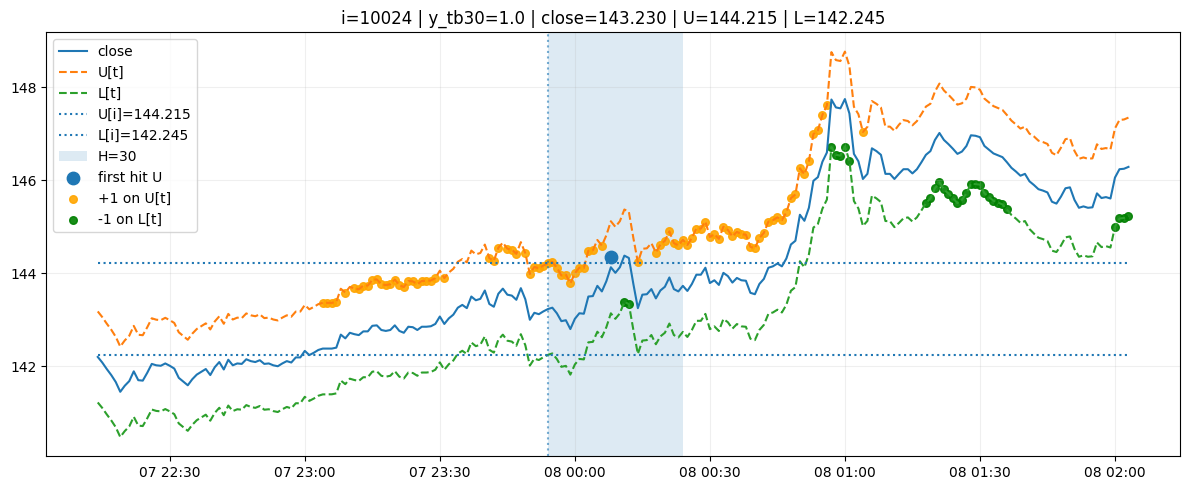

In [ ]:
plot_tb30_from_cols(df1, i=10024, H=30, mark_mode="labels", mark_scope="window")

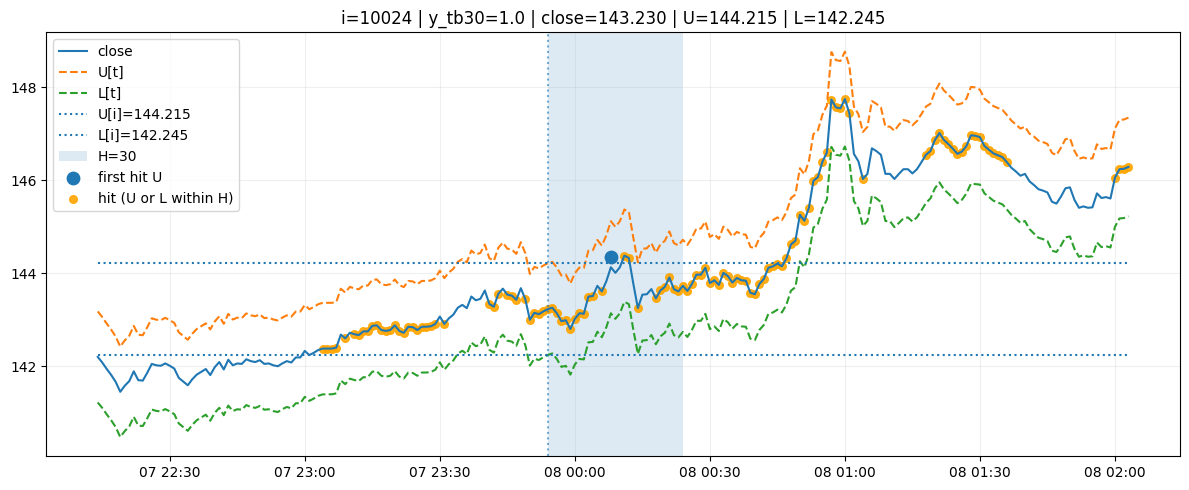

In [ ]:
plot_tb30_from_cols(df1, i=10024, H=30, mark_mode="hit", mark_scope="window")

## Train

In [ ]:
model_df = (
    df1.select(["t", "y_tb30"] + FEATURES)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

In [ ]:
sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3152949 n_features = 46


In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df_bin = make_binary(model_df)

In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

In [ ]:
folds = make_walkforward_splits(
    df,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,      # test ไม่ซ้อน
    mode="rolling",
    purge_minutes=30,
    embargo_minutes=60,
)

In [ ]:
def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

X = (
    df_bin
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)
)

y = df_bin["y_hit"].to_numpy()

## Train

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

fold_results = []
models = {}

for f in folds:
    fold_id = f["fold"]
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    # inner split
    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="Logloss",
        depth=6,
        learning_rate=0.05,
        iterations=4000,
        l2_leaf_reg=20,
        subsample=0.8,
        rsm=0.8,
        random_strength=1.0,
        bagging_temperature=1.0,
        auto_class_weights="SqrtBalanced",
        random_seed=42,
        verbose=200,
    )

    # early stopping ใช้ "val" เท่านั้น
    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    # evaluate on TEST (ห้ามใช้ใน fit)
    p = model.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, p)

    fold_results.append({
        "fold": fold_id,
        "auc": float(auc),
        "best_iter": int(model.get_best_iteration() or -1),
        "train_start": f["train_start"],
        "train_end": f["train_end"],
        "test_start": f["test_start"],
        "test_end": f["test_end"],
        "n_train": int(len(tr2_idx)),
        "n_val": int(len(va2_idx)),
        "n_test": int(len(te_idx)),
    })
    models[fold_id] = model

0:	learn: 0.6895838	test: 0.6898160	best: 0.6898160 (0)	total: 109ms	remaining: 7m 13s
200:	learn: 0.6182651	test: 0.6509612	best: 0.6501515 (163)	total: 8.44s	remaining: 2m 39s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6501514524
bestIteration = 163

Shrink model to first 164 iterations.
0:	learn: 0.6898647	test: 0.6896803	best: 0.6896803 (0)	total: 50.3ms	remaining: 3m 21s
200:	learn: 0.6214789	test: 0.6438233	best: 0.6397525 (89)	total: 7.72s	remaining: 2m 25s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.639752538
bestIteration = 89

Shrink model to first 90 iterations.
0:	learn: 0.6893997	test: 0.6881680	best: 0.6881680 (0)	total: 39.1ms	remaining: 2m 36s
200:	learn: 0.6165067	test: 0.6332976	best: 0.6332079 (196)	total: 7.18s	remaining: 2m 15s
400:	learn: 0.5895396	test: 0.6349621	best: 0.6319500 (291)	total: 15.4s	remaining: 2m 18s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6319499656
bestIteration = 291

In [ ]:
import numpy as np

aucs = [r["auc"] for r in fold_results]
print("fold AUCs:", aucs)
print("mean AUC:", float(np.mean(aucs)))
print("std  AUC:", float(np.std(aucs)))

fold AUCs: [0.6613043883627128, 0.626678789916947, 0.6318805870613345, 0.6250646880485667, 0.6519950789919857, 0.6774606411562045, 0.6751532468033614, 0.657283459976825, 0.7026272549444917, 0.7389115455959824, 0.7507939754131272, 0.8152955241914777, 0.7287365941983646, 0.7122448940146353, 0.7255954769421101, 0.7114015753305267, 0.716670612774181, 0.7071031707821261, 0.7045086852202563, 0.7024952630157111]
mean AUC: 0.6961602726370464
std  AUC: 0.04560617492231182


In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # เอาเวลาออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        p = model.predict_proba(X[te])[:, 1]

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te],
            "p": p,
            "test_start": f["test_start"],
            "test_end": f["test_end"],
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

In [ ]:
pred = build_oof_predictions_table(df, X, y, folds, models, tcol="t")

In [ ]:
pred["y_pred"] = pred["p"] > 0.5

In [ ]:
pred["y"].value_counts()

,count
y,
0,1357866
1,1271574


In [ ]:
pred["y_pred"].value_counts()

,count
y_pred,
False,1493942
True,1135498


In [ ]:
pred.to_csv(str(data_path("Micro Structure Behavior/canyougivemeonemoreday/hit_pred_fold_CatBoostClassifier_v1.csv")),index=False)

## EDA

In [ ]:
import pandas as pd
import numpy as np

def feature_importance_per_fold(models: dict, feature_names: list):
    rows = []
    for fold_id, m in models.items():
        imp = m.get_feature_importance()  # default: PredictionValuesChange
        part = pd.DataFrame({
            "fold": fold_id,
            "feature": feature_names,
            "importance": imp,
        }).sort_values("importance", ascending=False)
        rows.append(part)
    return pd.concat(rows, ignore_index=True)

In [ ]:
fi_fold = feature_importance_per_fold(models, FEATURES)

In [ ]:
def summarize_feature_importance(fi_fold: pd.DataFrame, top_k=30):
    agg = (fi_fold
        .groupby("feature", as_index=False)
        .agg(
            imp_mean=("importance", "mean"),
            imp_std=("importance", "std"),
        )
        .sort_values("imp_mean", ascending=False)
        .reset_index(drop=True)
    )
    agg["rank"] = np.arange(1, len(agg) + 1)
    return agg.head(top_k), agg

fi_top30, fi_all = summarize_feature_importance(fi_fold, top_k=30)

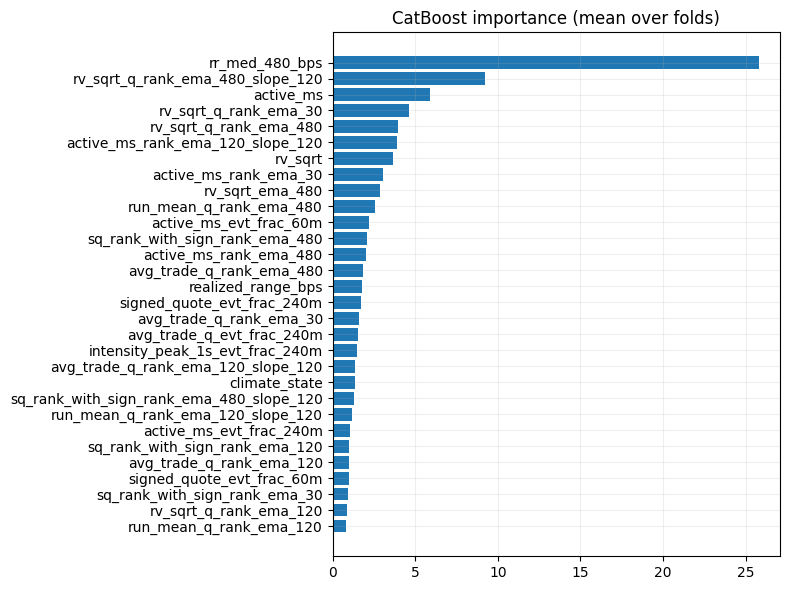

In [ ]:
import matplotlib.pyplot as plt

def plot_top_importance(df_top: pd.DataFrame, value_col="imp_mean", title="Top Feature Importance"):
    d = df_top.copy().iloc[::-1]  # reverse for nice barh
    plt.figure(figsize=(8, 6))
    plt.barh(d["feature"], d[value_col])
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

plot_top_importance(fi_top30.head(30), value_col="imp_mean", title="CatBoost importance (mean over folds)")

In [ ]:
pred_pl = pl.from_pandas(
    pred[["t", "p", "y_pred"]]
)

In [ ]:
df2 = df1.join(
    pred_pl,
    on="t",
    how="inner"   # หรือ "left" ถ้าอยากเก็บทุกแถว
)

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df2 = make_binary(df2)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_tb30_compare_strip(
    df: pl.DataFrame,
    i: int,
    *,
    tcol="t",
    close_col="close",
    U_col="_U",
    L_col="_L",
    H=30,
    pad_left=300,
    pad_right=300,
    # truth/pred sources
    y_true_col="y_hit",
    y_pred_col="y_pred",
    p_col="p",
    use_p_as_pred=True,
    p_thr=0.55,
    # display toggles
    show_p=True,
    show_price_band=True,
    # marker sizes
    s_top=18,
    s_strip=18,
    alpha=0.85,
):
    df = df.sort(tcol)
    n = len(df)

    a = max(0, i - pad_left)
    b = min(n, i + H + pad_right)

    # window arrays
    t = df[tcol].to_numpy()[a:b]
    close = np.asarray(df[close_col].to_numpy()[a:b], dtype=float)
    U = np.asarray(df[U_col].to_numpy()[a:b], dtype=float)
    L = np.asarray(df[L_col].to_numpy()[a:b], dtype=float)

    # y_true in window
    y_true = np.asarray(df[y_true_col].to_numpy()[a:b], dtype=float)
    y_true = np.where(np.isfinite(y_true), y_true, 0.0).astype(int)

    # y_pred source
    if use_p_as_pred:
        if p_col not in df.columns:
            raise ValueError(f"p_col='{p_col}' not found in df")
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float)
        p = np.where(np.isfinite(p), p, np.nan)
        y_pred = (p >= p_thr).astype(int)
    else:
        y_pred = np.asarray(df[y_pred_col].to_numpy()[a:b], dtype=float)
        y_pred = np.where(np.isfinite(y_pred), y_pred, 0.0).astype(int)
        # still get p for plotting if available
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float) if (p_col in df.columns) else None
        if p is not None:
            p = np.where(np.isfinite(p), p, np.nan)

    # confusion masks
    true1 = (y_true == 1)
    pred1 = (y_pred == 1)
    tp = true1 & pred1
    fp = (~true1) & pred1
    fn = true1 & (~pred1)
    tn = (~true1) & (~pred1)

    # --- build figure layout ---
    nrows = 3 if (show_p and (p is not None)) else 2
    height_ratios = [4, 1.3, 0.8] if nrows == 3 else [4, 0.9]

    fig, axes = plt.subplots(
        nrows=nrows, ncols=1, figsize=(14, 6 if nrows == 3 else 5),
        sharex=True, gridspec_kw={"height_ratios": height_ratios}
    )
    ax_price = axes[0]
    ax_p = axes[1] if nrows == 3 else None
    ax_strip = axes[2] if nrows == 3 else axes[1]

    # ===== Panel 1: price + bands =====
    ax_price.plot(t, close, label="close")
    ax_price.plot(t, U, linestyle="--", label="U[t]")
    ax_price.plot(t, L, linestyle="--", label="L[t]")

    if show_price_band and (i + H < n):
        ax_price.axvspan(df[tcol][i], df[tcol][i + H], alpha=0.12, label=f"H={H}")
    ax_price.axvline(df[tcol][i], linestyle=":", alpha=0.6)

    # mark TP/FP/FN on price (optional but helpful)
    ax_price.scatter(t[tp], close[tp], s=s_top, c="green", alpha=alpha, label="TP")
    ax_price.scatter(t[fp], close[fp], s=s_top, c="red", alpha=alpha, marker="x", label="FP")
    ax_price.scatter(t[fn], close[fn], s=s_top, c="purple", alpha=alpha, marker="x", label="FN")

    ax_price.grid(alpha=0.2)

    # ===== Panel 2: p line =====
    if ax_p is not None:
        ax_p.plot(t, p, alpha=0.7, label="p")
        ax_p.set_ylim(0, 1)
        ax_p.hlines(p_thr, t[0], t[-1], linestyles="--", alpha=0.6, label=f"p_thr={p_thr}")
        ax_p.grid(alpha=0.2)
        ax_p.legend(loc="upper left")

    # ===== Panel 3: strip (TP/FP/FN/TN) =====
    # Put them on 4 discrete y-levels to avoid overlap
    # y levels: TP=3, FP=2, FN=1, TN=0
    y_strip = np.full(len(t), np.nan, dtype=float)
    y_strip[tp] = 3
    y_strip[fp] = 2
    y_strip[fn] = 1
    y_strip[tn] = 0

    ax_strip.scatter(t[tn], np.zeros(tn.sum()), s=s_strip, c="gray", alpha=0.35, label="TN")
    ax_strip.scatter(t[fn], np.ones(fn.sum()), s=s_strip, c="purple", alpha=alpha, label="FN")
    ax_strip.scatter(t[fp], np.full(fp.sum(), 2.0), s=s_strip, c="red", alpha=alpha, label="FP")
    ax_strip.scatter(t[tp], np.full(tp.sum(), 3.0), s=s_strip, c="green", alpha=alpha, label="TP")

    ax_strip.set_yticks([0, 1, 2, 3])
    ax_strip.set_yticklabels(["TN", "FN", "FP", "TP"])
    ax_strip.grid(alpha=0.2, axis="x")

    # titles + legend
    mode = "p>=thr" if use_p_as_pred else "y_pred col"
    prec = tp.sum() / max(1, (tp.sum() + fp.sum()))
    rec = tp.sum() / max(1, (tp.sum() + fn.sum()))

    ax_price.set_title(
        f"Compare (mode={mode}) | window [{a}:{b}) | center i={i} | "
        f"TP={tp.sum()} FP={fp.sum()} FN={fn.sum()} | precision={prec:.3f} recall={rec:.3f}"
    )
    ax_price.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

    return {
        "a": a, "b": b,
        "tp": int(tp.sum()), "fp": int(fp.sum()), "fn": int(fn.sum()), "tn": int(tn.sum()),
        "precision": float(prec), "recall": float(rec),
        "mode": mode,
    }

In [ ]:
df2.filter(pl.col("p") > 0.9)

i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,…,avg_trade_q_rank_ema_120_slope_120_bin3_robust_raw,avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp,avg_trade_q_rank_ema_120_slope_120_bin3_robust_streak,avg_trade_q_rank_ema_120_slope_120_bin3_robust_pending,avg_trade_q_rank_ema_120_slope_120_bin3_robust,avg_trade_q_rank_ema_120_slope_120_med,avg_trade_q_rank_ema_120_slope_120_mad,avg_trade_q_rank_ema_120_slope_120_tau,run_mean_q_rank_ema_120_slope_120_bin3_robust_raw,run_mean_q_rank_ema_120_slope_120_bin3_robust_grp,run_mean_q_rank_ema_120_slope_120_bin3_robust_streak,run_mean_q_rank_ema_120_slope_120_bin3_robust_pending,run_mean_q_rank_ema_120_slope_120_bin3_robust,run_mean_q_rank_ema_120_slope_120_med,run_mean_q_rank_ema_120_slope_120_mad,run_mean_q_rank_ema_120_slope_120_tau,rv_sqrt_q_rank_like_Lint,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_q_rank_ema_1440,rv_sqrt_ema_480_right,rv_sqrt_ema_1440_right,rv_sqrt_q_rank_ema_480_slope_30,rv_sqrt_q_rank_ema_480_slope_120,realized_range,realized_range_bps,rr_med_480,rr_med_480_bps,_U,_L,y_tb30,y_tb30_tie,y_tb30_width_bps,p,y_pred,y_hit
u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,…,i8,i32,u32,i8,i8,f64,f64,f64,i8,i32,u32,i8,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,f64,bool,i8
393640,2020-10-01 00:22:00,360.55,360.56,360.36,360.43,177.37153,63937.955607,89.0,34.0,55.0,4224.494399,59713.461208,360.474737,1.483333,-0.867856,0.2,0.000555,360.58,-0.000333,-0.000416,-0.000083,664.863636,237.5,1932.0,0.227273,3.6942e-7,0.306818,61,24,37,0.09,-0.05,88,718.403996,0.51123,4.4,…,1,14983,57,1,1,-0.000037,0.000431,0.00032,1,18783,48,1,1,-0.000047,0.000373,0.000276,0.506926,0.52979,0.453935,0.392018,0.377235,0.00057,0.000556,0.000638,0.000286,0.2,5.548928,0.25,6.997706,361.811457,359.048543,-1.0,false,76.656025,0.924249,true,1
393641,2020-10-01 00:23:00,360.44,360.64,360.4,360.62,106.70244,38472.172519,58.0,29.0,29.0,15885.730811,22586.441707,360.555696,0.966667,-0.17417,0.24,0.000666,360.43,0.000499,0.000527,0.000028,1001.561404,255.0,2701.0,0.140351,2.6158e-7,0.350877,37,21,16,0.1,-0.05,57,663.313319,0.56195,4.53955,…,1,14983,58,1,1,-0.000037,0.000431,0.00032,1,18783,49,1,1,-0.000047,0.000373,0.000276,0.355401,0.518539,0.452306,0.391866,0.377205,0.000569,0.000556,0.000676,0.000292,0.24,6.655205,0.25,6.992226,362.001102,359.238898,-1.0,false,76.595997,0.927714,true,1
393650,2020-10-01 00:32:00,359.52,359.68,359.18,359.58,458.86773,164955.856289,132.0,59.0,73.0,69972.980465,94982.875824,359.484543,2.2,-0.151616,0.5,0.001391,359.48,0.000167,0.000278,0.000111,426.587786,108.0,1586.0,0.122137,3.4060e-7,0.343511,86,46,40,0.07,-0.06,131,1249.665578,1.1,9.25,…,1,14983,67,1,1,-0.000037,0.000431,0.00032,1,18783,58,1,1,-0.000047,0.000374,0.000277,0.471775,0.586917,0.482314,0.401992,0.380802,0.000578,0.000559,0.000896,0.000334,0.5,13.905112,0.25,7.025037,360.963582,358.196418,0.0,false,76.955429,0.910632,true,0
393651,2020-10-01 00:33:00,359.58,359.68,359.41,359.51,161.16133,57949.618899,76.0,29.0,47.0,17378.744569,40570.87433,359.575209,1.266667,-0.400212,0.27,0.000751,359.58,-0.000195,-0.000195,0.0,788.08,171.0,1997.0,0.173333,4.3702e-7,0.306667,52,22,30,0.09,-0.08,75,762.494986,0.58,5.56,…,1,14983,68,1,1,-0.000037,0.000431,0.00032,1,18783,59,1,1,-0.000047,0.000374,0.000277,0.562015,0.58531,0.483632,0.402657,0.381054,0.000578,0.00056,0.000889,0.000346,0.27,7.510222,0.25,7.025037,360.893312,358.126688,0.0,false,76.955429,0.936687,true,0
393652,2020-10-01 00:34:00,359.51,359.53,359.3,359.34,235.36305,84595.809352,93.0,59.

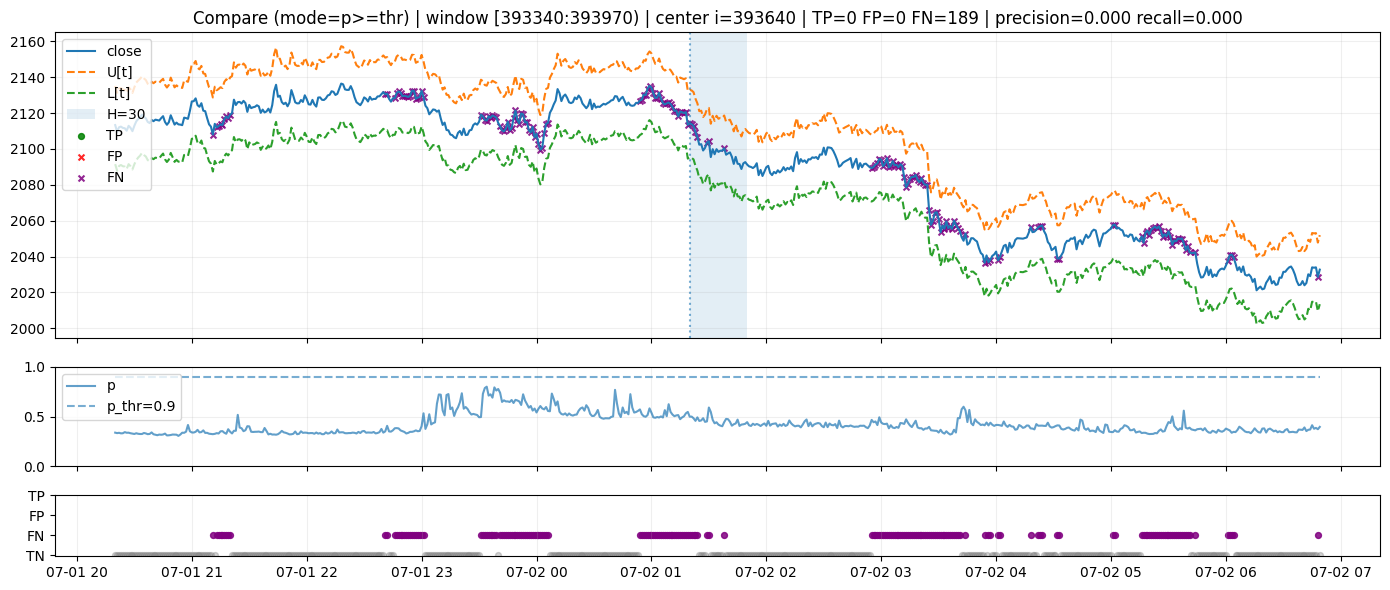

{'a': 393340,
 'b': 393970,
 'tp': 0,
 'fp': 0,
 'fn': 189,
 'tn': 441,
 'precision': 0.0,
 'recall': 0.0,
 'mode': 'p>=thr'}

In [ ]:
plot_tb30_compare_strip(df2, i=393640, H=30, use_p_as_pred=True, p_thr=0.9)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Core helpers
# -----------------------------
def _confusion_counts(y_true: np.ndarray, y_pred: np.ndarray):
    y_true = y_true.astype(int)
    y_pred = y_pred.astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall    = tp / (tp + fn) if (tp + fn) else np.nan
    fpr       = fp / (fp + tn) if (fp + tn) else np.nan
    tpr       = recall
    acc       = (tp + tn) / (tp + fp + fn + tn) if (tp + fp + fn + tn) else np.nan
    return tp, fp, fn, tn, precision, recall, fpr, tpr, acc

def _logloss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y*np.log(p) + (1-y)*np.log(1-p)).mean())

def _brier(y, p):
    return float(np.mean((p - y) ** 2))

# -----------------------------
# EDA tables
# -----------------------------
def per_fold_metrics(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        yhat = g[y_pred_col].astype(int).values
        p = g[p_col].astype(float).values

        tp, fp, fn, tn, precision, recall, fpr, tpr, acc = _confusion_counts(y, yhat)
        rows.append({
            "fold": fold,
            "n": len(g),
            "base_rate": float(y.mean()),
            "pred_rate": float(yhat.mean()),
            "mean_p": float(np.mean(p)),
            "p_p10": float(np.quantile(p, 0.10)),
            "p_p50": float(np.quantile(p, 0.50)),
            "p_p90": float(np.quantile(p, 0.90)),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": precision, "recall": recall, "fpr": fpr, "acc": acc,
            "logloss": _logloss(y, p),
            "brier": _brier(y, p),
        })
    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

def lift_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
    by_fold: bool = False,
    fold_col="fold",
):
    df = pred[[p_col, y_col] + ([fold_col] if by_fold else [])].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    def _one(g):
        # qcut so each bin has ~equal size
        g = g.copy()
        g["bin"] = pd.qcut(g[p_col], q=n_bins, duplicates="drop")
        out = g.groupby("bin", observed=True).agg(
            n=(y_col, "size"),
            p_mean=(p_col, "mean"),
            y_rate=(y_col, "mean"),
            p_min=(p_col, "min"),
            p_max=(p_col, "max"),
        ).reset_index(drop=True)
        base = float(g[y_col].mean())
        out["lift_vs_base"] = out["y_rate"] / (base + 1e-12)
        # sort from high-p to low-p
        out = out.sort_values("p_mean", ascending=False).reset_index(drop=True)
        return out

    if by_fold:
        res = []
        for f, g in df.groupby(fold_col):
            tmp = _one(g)
            tmp[fold_col] = f
            res.append(tmp)
        return pd.concat(res, ignore_index=True)
    else:
        return _one(df)

def calibration_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
):
    df = pred[[p_col, y_col]].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    df["bin"] = pd.qcut(df[p_col], q=n_bins, duplicates="drop")
    cal = df.groupby("bin", observed=True).agg(
        n=(y_col, "size"),
        p_mean=(p_col, "mean"),
        y_rate=(y_col, "mean"),
        p_min=(p_col, "min"),
        p_max=(p_col, "max"),
    ).reset_index(drop=True)
    cal["gap(y_rate - p_mean)"] = cal["y_rate"] - cal["p_mean"]
    return cal.sort_values("p_mean").reset_index(drop=True)

def error_breakdown(
    pred: pd.DataFrame,
    *,
    y_col="y",
    y_pred_col="y_pred",
    group_cols=("climate_group", "regime_id_confirmed"),
):
    # keep only existing group cols
    group_cols = [c for c in group_cols if c in pred.columns]
    if not group_cols:
        return None

    df = pred.copy()
    y = df[y_col].astype(int).values
    yhat = df[y_pred_col].astype(int).values

    df["_TP"] = ((y == 1) & (yhat == 1)).astype(int)
    df["_FP"] = ((y == 0) & (yhat == 1)).astype(int)
    df["_FN"] = ((y == 1) & (yhat == 0)).astype(int)
    df["_TN"] = ((y == 0) & (yhat == 0)).astype(int)

    out = df.groupby(group_cols, observed=True).agg(
        n=(y_col, "size"),
        base_rate=(y_col, "mean"),
        pred_rate=(y_pred_col, "mean"),
        tp=("_TP", "sum"),
        fp=("_FP", "sum"),
        fn=("_FN", "sum"),
        tn=("_TN", "sum"),
    ).reset_index()

    out["precision"] = out["tp"] / (out["tp"] + out["fp"]).replace(0, np.nan)
    out["recall"]    = out["tp"] / (out["tp"] + out["fn"]).replace(0, np.nan)
    out["fpr"]       = out["fp"] / (out["fp"] + out["tn"]).replace(0, np.nan)
    return out.sort_values(["n"], ascending=False).reset_index(drop=True)

# -----------------------------
# Plots (matplotlib only)
# -----------------------------
def plot_calibration(cal: pd.DataFrame):
    plt.figure(figsize=(6,5))
    plt.plot(cal["p_mean"], cal["y_rate"], marker="o")
    plt.plot([0,1],[0,1], linestyle="--")
    plt.xlabel("mean predicted p")
    plt.ylabel("empirical y=1 rate")
    plt.title("Calibration (Reliability)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_lift(lift: pd.DataFrame, base_rate: float = None):
    plt.figure(figsize=(6,4))
    plt.plot(lift["y_rate"].values, marker="o")
    if base_rate is not None:
        plt.axhline(base_rate, linestyle="--")
    plt.ylabel("y=1 rate")
    plt.title("Lift by p-bin (high→low)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_rolling_p_vs_y(
    pred: pd.DataFrame,
    *,
    t_col="t",
    p_col="p",
    y_col="y",
    window=500,
    min_periods=100,
):
    df = pred[[t_col, p_col, y_col]].copy()
    df[t_col] = pd.to_datetime(df[t_col])
    df = df.sort_values(t_col)
    df["p_roll"] = df[p_col].astype(float).rolling(window, min_periods=min_periods).mean()
    df["y_roll"] = df[y_col].astype(int).rolling(window, min_periods=min_periods).mean()

    plt.figure(figsize=(10,4))
    plt.plot(df[t_col], df["p_roll"], label="rolling mean p")
    plt.plot(df[t_col], df["y_roll"], label="rolling mean y")
    plt.title(f"Rolling mean p vs y (window={window})")
    plt.xlabel("time")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

# -----------------------------
# One-call EDA runner
# -----------------------------
def run_pred_eda(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    t_col="t",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),
    do_plots=True,
):
    # tables
    pf = per_fold_metrics(pred, fold_col=fold_col, y_col=y_col, y_pred_col=y_pred_col, p_col=p_col)
    lift = lift_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins, by_fold=False)
    cal = calibration_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins)
    err = error_breakdown(pred, y_col=y_col, y_pred_col=y_pred_col, group_cols=group_cols)

    if do_plots:
        plot_calibration(cal)
        base = float(pred[y_col].astype(int).mean())
        plot_lift(lift, base_rate=base)
        plot_rolling_p_vs_y(pred, t_col=t_col, p_col=p_col, y_col=y_col)

    return {
        "per_fold": pf,
        "lift": lift,
        "calibration": cal,
        "error_breakdown": err,
    }

In [ ]:
out["per_fold"]

,fold,n,base_rate,pred_rate,mean_p,p_p10,p_p50,p_p90,tp,fp,fn,tn,precision,recall,fpr,acc,logloss,brier
0,0,132480,0.413345,0.326464,0.470617,0.321373,0.442486,0.666064,24927,18323,29833,59397,0.576347,0.455205,0.235757,0.636504,0.642044,0.225488
1,1,129600,0.353156,0.401188,0.485920,0.344952,0.467697,0.657539,23791,28203,21978,55628,0.457572,0.519806,0.336427,0.612801,0.660561,0.234014
2,2,131040,0.373718,0.263851,0.426567,0.255150,0.397158,0.650698,18443,16132,30529,65936,0.533420,0.376603,0.196569,0.643918,0.639024,0.223889
3,3,132480,0.390459,0.212107,0.424656,0.301564,0.398833,0.585738,15991,12109,35737,68643,0.569075,0.309136,0.149953,0.638844,0.644197,0.226296
4,4,132480,0.396732,0.346150,0.470301,0.337818,0.453749,0.629475,24955,20903,27604,59018,0.544180,0.474800,0.261546,0.633854,0.645364,0.226929
5,5,129600,0.436265,0.401767,0.473676,0.292246,0.466848,0.673608,30654,21415,25886,51645,0.588719,0.542165,0.293115,0.635023,0.636299,0.222942
6,6,131040,0.456967,0.389415,0.463240,0.271517,0.453512,0.662030,32041,18988,27840,52171,0.627898,0.535078,0.266839,0.642643,0.639200,0.224126
7,7,132480,0.446233,0.282511,0.425747,0.261858,0.410134,0.612336,23497,13930,35620,59433,0.627809,0.397466,0.189878,0.625981,0.646816,0.227605
8,8,132480,0.546792,0.654974,0.576500,0.365324,0.571091,0.799322,55908,30863,16531,29178,0.644317,0.771794,0.514032,0.642255,0.623600,0.218012
9,9,129600,0.527816,0.692824,0.604933,0.362689,0.605170,0.847686,56836,32954,11569,28241,0.632988,0.830875,0.538508,0.656458,0.612130,0.213316


In [ ]:
out["lift"]

,n,p_mean,y_rate,p_min,p_max,lift_vs_base
0,262944,0.858068,0.871444,0.767074,0.998456,1.802026
1,262944,0.707451,0.700446,0.656321,0.767074,1.448425
2,262944,0.615636,0.596922,0.578350,0.656321,1.234352
3,262944,0.546595,0.522370,0.517132,0.578350,1.080189
4,262944,0.490947,0.458132,0.466041,0.517131,0.947353
5,262944,0.442717,0.410787,0.419932,0.466041,0.849451
6,262944,0.397792,0.374045,0.375629,0.419932,0.773474
7,262944,0.352640,0.341449,0.328480,0.375629,0.706070
8,262944,0.300072,0.308469,0.267692,0.328479,0.637871
9,262944,0.214680,0.251848,0.036952,0.267692,0.520788


In [ ]:
out["calibration"]

,n,p_mean,y_rate,p_min,p_max,gap(y_rate - p_mean)
0,262944,0.214680,0.251848,0.036952,0.267692,0.037169
1,262944,0.300072,0.308469,0.267692,0.328479,0.008397
2,262944,0.352640,0.341449,0.328480,0.375629,-0.011191
3,262944,0.397792,0.374045,0.375629,0.419932,-0.023746
4,262944,0.442717,0.410787,0.419932,0.466041,-0.031930
5,262944,0.490947,0.458132,0.466041,0.517131,-0.032816
6,262944,0.546595,0.522370,0.517132,0.578350,-0.024225
7,262944,0.615636,0.596922,0.578350,0.656321,-0.018714
8,262944,0.707451,0.700446,0.656321,0.767074,-0.007005
9,262944,0.858068,0.871444,0.767074,0.998456,0.013376


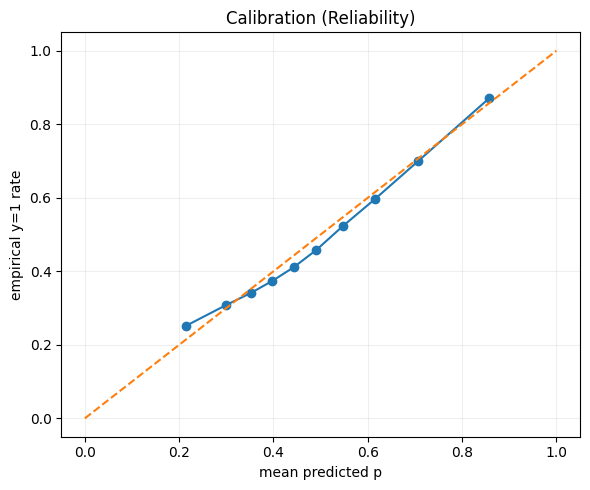

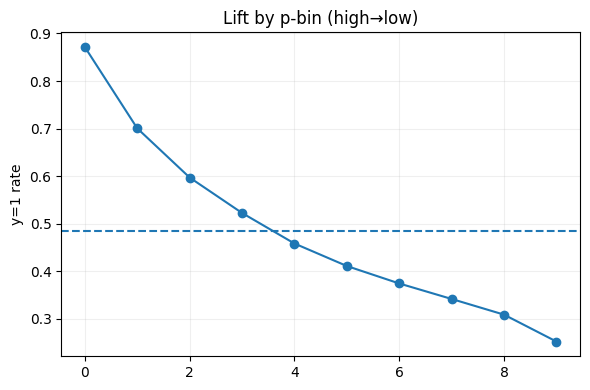

/tmp/ipython-input-462777707.py:208: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


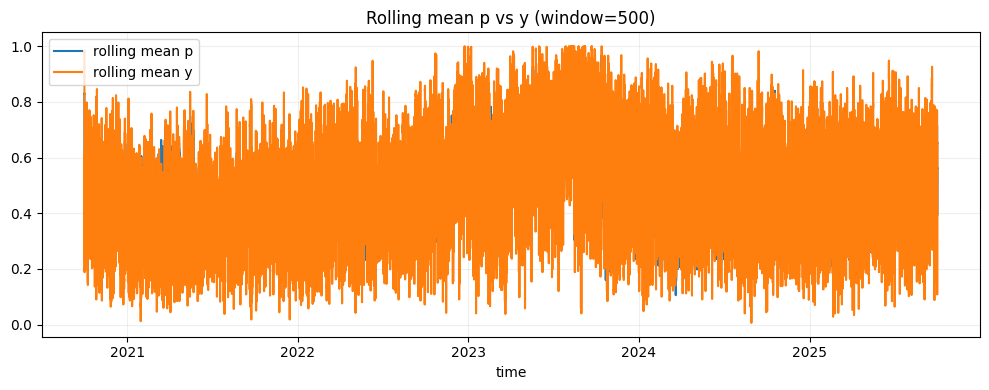

In [ ]:
out = run_pred_eda(
    pred,
    y_col="y",          # ของจริง (hit)
    y_pred_col="y_pred",
    p_col="p",
    fold_col="fold",
    t_col="t",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),  # ถ้ายังไม่ได้ join ก็ปล่อยไว้ได้
    do_plots=True,
)

out["per_fold"].head()
out["lift"].head()
out["calibration"].head()
out["error_breakdown"].head() if out["error_breakdown"] is not None else None

In [ ]:
import numpy as np
import pandas as pd

def sweep_thresholds_per_fold(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    p_col="p",
    thresholds=None,
):
    if thresholds is None:
        thresholds = np.linspace(0.2, 0.9, 15)

    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        base = y.mean()

        for thr in thresholds:
            yhat = (p >= thr).astype(int)

            tp = np.sum((y == 1) & (yhat == 1))
            fp = np.sum((y == 0) & (yhat == 1))
            fn = np.sum((y == 1) & (yhat == 0))
            tn = np.sum((y == 0) & (yhat == 0))

            precision = tp / (tp + fp) if (tp + fp) else np.nan
            recall    = tp / (tp + fn) if (tp + fn) else np.nan
            trade_rate = yhat.mean()

            rows.append({
                "fold": fold,
                "thr": float(thr),
                "n": len(g),
                "base_rate": float(base),
                "trade_rate": float(trade_rate),
                "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
                "precision": float(precision) if precision==precision else np.nan,
                "recall": float(recall) if recall==recall else np.nan,
            })

    return pd.DataFrame(rows).sort_values(["fold","thr"]).reset_index(drop=True)

In [ ]:
sweep = sweep_thresholds_per_fold(pred)

In [ ]:
sweep[sweep["thr"]==0.55].sort_values("precision")

,fold,thr,n,base_rate,trade_rate,tp,fp,fn,tn,precision,recall
22,1,0.55,129600,0.353156,0.275571,17993,17721,27776,66110,0.503808,0.393126
37,2,0.55,131040,0.373718,0.193781,14483,10910,34489,71158,0.570354,0.295740
67,4,0.55,132480,0.396732,0.216531,17202,11484,35357,68437,0.599665,0.327289
52,3,0.55,132480,0.390459,0.136700,11145,6965,40583,73787,0.615406,0.215454
7,0,0.55,132480,0.413345,0.226804,18564,11483,36196,66237,0.617832,0.339007
82,5,0.55,129600,0.436265,0.270640,22555,12520,33985,60540,0.643051,0.398921
142,9,0.55,129600,0.527816,0.600671,51817,26030,16588,35165,0.665626,0.757503
97,6,0.55,131040,0.456967,0.280670,24736,12043,35145,59116,0.672558,0.413086
127,8,0.55,132480,0.546792,0.546792,48961,23478,23478,36563,0.675893,0.675893
112,7,0.55,132480,0.446233,0.185779,16754,7858,42363,65505,0.680725,0.283404


In [ ]:
def pick_thr_by_precision(sweep: pd.DataFrame, target_precision=0.70):
    out = []
    for fold, g in sweep.groupby("fold"):
        gg = g.dropna(subset=["precision"]).copy()
        gg = gg[gg["precision"] >= target_precision]
        if len(gg) == 0:
            # ถ้าไม่มี threshold ไหนถึงเป้า เลือกที่ precision สูงสุด
            best = g.dropna(subset=["precision"]).sort_values(["precision","trade_rate"], ascending=[False,True]).head(1)
        else:
            # ถ้ามีหลายอันถึงเป้า เลือก trade_rate ต่ำสุด (กัน FP/overtrade)
            best = gg.sort_values(["trade_rate","thr"], ascending=[True,True]).head(1)
        out.append(best)

    return pd.concat(out, ignore_index=True).sort_values("fold").reset_index(drop=True)

In [ ]:
sweep = sweep_thresholds_per_fold(pred)
thr_by_fold = pick_thr_by_precision(sweep, target_precision=0.70)

In [ ]:
thr_by_fold

,fold,thr,n,base_rate,trade_rate,tp,fp,fn,tn,precision,recall
0,0,0.9,132480,0.413345,0.007526,922,75,53838,77645,0.924774,0.016837
1,1,0.9,129600,0.353156,0.000378,47,2,45722,83829,0.959184,0.001027
2,2,0.9,131040,0.373718,0.004342,516,53,48456,82015,0.906854,0.010537
3,3,0.9,132480,0.390459,0.001585,204,6,51524,80746,0.971429,0.003944
4,4,0.9,132480,0.396732,0.001011,131,3,52428,79918,0.977612,0.002492
5,5,0.9,129600,0.436265,0.002407,297,15,56243,73045,0.951923,0.005253
6,6,0.9,131040,0.456967,0.002755,346,15,59535,71144,0.958449,0.005778
7,7,0.9,132480,0.446233,0.000332,43,1,59074,73362,0.977273,0.000727
8,8,0.9,132480,0.546792,0.022486,2863,116,69576,59925,0.961061,0.039523
9,9,0.9,129600,0.527816,0.048665,6011,296,62394,60899,0.953068,0.087874


In [ ]:
def topq_policy_per_fold(pred: pd.DataFrame, *, fold_col="fold", y_col="y", p_col="p", q=0.10):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        thr = np.quantile(p, 1 - q)
        yhat = (p >= thr).astype(int)

        tp = np.sum((y == 1) & (yhat == 1))
        fp = np.sum((y == 0) & (yhat == 1))
        fn = np.sum((y == 1) & (yhat == 0))
        tn = np.sum((y == 0) & (yhat == 0))

        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall    = tp / (tp + fn) if (tp + fn) else np.nan

        rows.append({
            "fold": fold,
            "q": q,
            "thr": float(thr),
            "n": len(g),
            "base_rate": float(y.mean()),
            "trade_rate": float(yhat.mean()),
            "precision": float(precision) if precision==precision else np.nan,
            "recall": float(recall) if recall==recall else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        })

    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

In [ ]:
top10 = topq_policy_per_fold(pred, q=0.10)
top5  = topq_policy_per_fold(pred, q=0.05)

In [ ]:
top5

,fold,q,thr,n,base_rate,trade_rate,precision,recall,tp,fp,fn,tn
0,0,0.05,0.756259,132480,0.413345,0.05,0.799064,0.096658,5293,1331,49467,76389
1,1,0.05,0.714898,129600,0.353156,0.05,0.703858,0.099653,4561,1919,41208,81912
2,2,0.05,0.739892,131040,0.373718,0.05,0.743284,0.099445,4870,1682,44102,80386
3,3,0.05,0.662299,132480,0.390459,0.05,0.708182,0.090686,4691,1933,47037,78819
4,4,0.05,0.692177,132480,0.396732,0.05,0.776570,0.097871,5144,1480,47415,78441
5,5,0.05,0.743424,129600,0.436265,0.05,0.821605,0.094163,5324,1156,51216,71904
6,6,0.05,0.729565,131040,0.456967,0.05,0.849969,0.093001,5569,983,54312,70176
7,7,0.05,0.674820,132480,0.446233,0.05,0.819293,0.091801,5427,1197,53690,72166
8,8,0.05,0.855475,132480,0.546792,0.05,0.922856,0.084388,6113,511,66326,59530
9,9,0.05,0.898487,129600,0.527816,0.05,0.951698,0.090154,6167,313,62238,60882


In [ ]:
def sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20), fold_col="fold", y_col="y", p_col="p"):
    out = []
    for q in qs:
        rows = topq_policy_per_fold(pred, fold_col=fold_col, y_col=y_col, p_col=p_col, q=q)
        rows["q"] = q
        out.append(rows)
    return pd.concat(out, ignore_index=True)

q_sweep = sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20))
# ดูค่าเฉลี่ยข้าม fold
q_sweep.groupby("q")[["precision","recall","trade_rate"]].mean().reset_index()

,q,precision,recall,trade_rate
0,0.01,0.944524,0.019943,0.010002
1,0.02,0.918958,0.038711,0.020002
2,0.05,0.866693,0.090830,0.050000
3,0.10,0.811403,0.169260,0.100000
4,0.20,0.740852,0.307416,0.200000


In [ ]:
top5 = topq_policy_per_fold(pred, q=0.05)
top5["edge"] = top5["precision"] - top5["base_rate"]
top5["lift"] = top5["precision"] / (top5["base_rate"] + 1e-12)
top5[["fold","base_rate","precision","edge","lift","trade_rate"]].sort_values("edge")

,fold,base_rate,precision,edge,lift,trade_rate
11,11,0.713836,0.996981,0.283145,1.396652,0.05
3,3,0.390459,0.708182,0.317723,1.813718,0.05
1,1,0.353156,0.703858,0.350702,1.993052,0.05
10,10,0.622092,0.976038,0.353945,1.568959,0.05
12,12,0.565942,0.931159,0.365217,1.645327,0.05
2,2,0.373718,0.743284,0.369567,1.988892,0.05
7,7,0.446233,0.819293,0.373060,1.836020,0.05
8,8,0.546792,0.922856,0.376064,1.687765,0.05
4,4,0.396732,0.776570,0.379838,1.957419,0.05
5,5,0.436265,0.821605,0.385340,1.883268,0.05


In [ ]:
def topq_precision_per_fold(pred, q=0.05, fold_col="fold", y_col="y", p_col="p"):
    out = []
    for f, g in pred.groupby(fold_col):
        thr = g[p_col].quantile(1-q)
        sel = g[g[p_col] >= thr]
        out.append({
            "fold": f,
            "base": g[y_col].mean(),
            "thr": thr,
            "prec_topq": sel[y_col].mean(),
            "lift_topq": sel[y_col].mean() / (g[y_col].mean() + 1e-12),
        })
    return pd.DataFrame(out).sort_values("fold")

topq_precision_per_fold(pred, q=0.05)

,fold,base,thr,prec_topq,lift_topq
0,0,0.413345,0.756259,0.799064,1.933163
1,1,0.353156,0.714898,0.703858,1.993052
2,2,0.373718,0.739892,0.743284,1.988892
3,3,0.390459,0.662299,0.708182,1.813718
4,4,0.396732,0.692177,0.776570,1.957419
5,5,0.436265,0.743424,0.821605,1.883268
6,6,0.456967,0.729565,0.849969,1.860022
7,7,0.446233,0.674820,0.819293,1.836020
8,8,0.546792,0.855475,0.922856,1.687765
9,9,0.527816,0.898487,0.951698,1.803085


# Train by covariate drift

## Feature & Fold

In [ ]:
import polars as pl

def add_alignment_contrast_regime_hit(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    rr_col: str = "rr_med_480_bps",
    y_hit_col: str = "y_hit",       # 0/1 หรือ bool
    window_size: int = 20_000,
    min_periods: int = 5_000,
    low_q: float = 0.2,
    high_q: float = 0.8,
    align_thr: float = 0.02,        # สำหรับ hit-rate มักเล็กกว่าเดิม
    contrast_thr: float = 0.02,
    out_id: str = "regime_id",
    out_cat: str = "regime_cat",
):
    """
    Regime definition (binary hit):
      p_low  = P(hit=1 | rr low)
      p_high = P(hit=1 | rr high)
      alignment = p_low - p_high
      contrast  = |alignment|
    """

    df = df.sort(tcol)

    # y_hit to Float64 (handles bool/0/1)
    df = df.with_columns(
        pl.col(y_hit_col).cast(pl.Float64).alias("_y_hit")
    )

    # rolling rr quantiles (past-only)
    df = df.with_columns([
        pl.col(rr_col)
          .rolling_quantile(low_q, window_size=window_size, min_periods=min_periods)
          .alias("_rr_q_low"),
        pl.col(rr_col)
          .rolling_quantile(high_q, window_size=window_size, min_periods=min_periods)
          .alias("_rr_q_high"),
    ])

    is_low_rr  = (pl.col(rr_col) <= pl.col("_rr_q_low"))
    is_high_rr = (pl.col(rr_col) >= pl.col("_rr_q_high"))

    # conditional rolling hit-rate
    # indicator masks
    low_mask  = (pl.col(rr_col) <= pl.col("_rr_q_low")).cast(pl.Int32)
    high_mask = (pl.col(rr_col) >= pl.col("_rr_q_high")).cast(pl.Int32)

    # rolling counts
    low_cnt = (
        low_mask
        .rolling_sum(window_size=window_size, min_periods=min_periods)
        .alias("_low_cnt")
    )

    high_cnt = (
        high_mask
        .rolling_sum(window_size=window_size, min_periods=min_periods)
        .alias("_high_cnt")
    )

    # rolling sums of hits
    low_hit_sum = (
        (pl.col("_y_hit") * low_mask)
        .rolling_sum(window_size=window_size, min_periods=min_periods)
        .alias("_low_hit_sum")
    )

    high_hit_sum = (
        (pl.col("_y_hit") * high_mask)
        .rolling_sum(window_size=window_size, min_periods=min_periods)
        .alias("_high_hit_sum")
    )

    df = df.with_columns([low_cnt, high_cnt, low_hit_sum, high_hit_sum])

    # conditional hit rates (safe divide)
    df = df.with_columns([
        pl.when(pl.col("_low_cnt") > 50)   # guard: ต้องมี sample พอ
          .then(pl.col("_low_hit_sum") / pl.col("_low_cnt"))
          .otherwise(None)
          .alias("p_hit_low_rr"),

        pl.when(pl.col("_high_cnt") > 50)
          .then(pl.col("_high_hit_sum") / pl.col("_high_cnt"))
          .otherwise(None)
          .alias("p_hit_high_rr"),
    ])

    # alignment & contrast
    df = df.with_columns([
        (pl.col("p_hit_low_rr") - pl.col("p_hit_high_rr")).alias("alignment"),
        (pl.col("p_hit_low_rr") - pl.col("p_hit_high_rr")).abs().alias("contrast"),
    ])

    # buckets
    # align_bucket: 0=low-worse, 1=neutral, 2=low-better
    df = df.with_columns(
        pl.when(pl.col("alignment") > align_thr).then(2)
        .when(pl.col("alignment") < -align_thr).then(0)
        .otherwise(1)
        .alias("_align_bucket")
    )

    # contrast_bucket: 0=weak, 1=strong
    df = df.with_columns(
        (pl.col("contrast") > contrast_thr).cast(pl.Int32).alias("_contrast_bucket")
    )

    # 6 regimes: align_bucket * 2 + contrast_bucket
    df = df.with_columns(
        (pl.col("_align_bucket") * 2 + pl.col("_contrast_bucket"))
        .cast(pl.Int32)
        .alias(out_id)
    )

    df = df.with_columns(
        pl.col(out_id).cast(pl.Utf8).cast(pl.Categorical).alias(out_cat)
    )

    return df

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df1 = make_binary(df1)

In [ ]:
df1

i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,…,active_ms_rank_ema_120_slope_120_mad,active_ms_rank_ema_120_slope_120_tau,avg_trade_q_rank_ema_120_slope_120_bin3_robust_raw,avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp,avg_trade_q_rank_ema_120_slope_120_bin3_robust_streak,avg_trade_q_rank_ema_120_slope_120_bin3_robust_pending,avg_trade_q_rank_ema_120_slope_120_bin3_robust,avg_trade_q_rank_ema_120_slope_120_med,avg_trade_q_rank_ema_120_slope_120_mad,avg_trade_q_rank_ema_120_slope_120_tau,run_mean_q_rank_ema_120_slope_120_bin3_robust_raw,run_mean_q_rank_ema_120_slope_120_bin3_robust_grp,run_mean_q_rank_ema_120_slope_120_bin3_robust_streak,run_mean_q_rank_ema_120_slope_120_bin3_robust_pending,run_mean_q_rank_ema_120_slope_120_bin3_robust,run_mean_q_rank_ema_120_slope_120_med,run_mean_q_rank_ema_120_slope_120_mad,run_mean_q_rank_ema_120_slope_120_tau,rv_sqrt_q_rank_like_Lint,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_q_rank_ema_1440,rv_sqrt_ema_480_right,rv_sqrt_ema_1440_right,rv_sqrt_q_rank_ema_480_slope_30,rv_sqrt_q_rank_ema_480_slope_120,realized_range,realized_range_bps,rr_med_480,rr_med_480_bps,_U,_L,y_tb30,y_tb30_tie,y_tb30_width_bps,y_hit
u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,…,f64,f64,i8,i32,u32,i8,i8,f64,f64,f64,i8,i32,u32,i8,i8,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,i8
0,2020-01-01 00:49:00,128.82,128.83,128.73,128.77,386.76163,49802.3661,70.0,48.0,22.0,43831.452955,5970.913146,128.767598,1.166667,0.760216,0.1,0.000777,128.83,-0.000388,-0.000466,-0.000078,804.898551,229.0,2799.0,0.101449,0.000001,0.376812,43,22,21,0.05,-0.07,69,711.462373,0.78,18.05364,…,null,null,0,0,49,0,0,null,null,null,0,0,49,0,0,null,null,null,null,null,null,null,null,0.001204,0.001264,null,null,0.1,7.765784,null,null,129.262702,128.277298,0.0,false,76.524284,0
1,2020-01-01 00:50:00,128.8,128.83,128.76,128.82,42.82265,5516.483846,20.0,8.0,12.0,4008.925923,1507.557923,128.821636,0.333333,0.453435,0.07,0.000543,128.77,0.000155,0.000388,0.000233,2890.157895,2381.0,5828.0,0.052632,2.7730e-7,0.263158,14,8,6,0.03,-0.04,19,275.824192,0.5093,7.15,…,null,null,0,0,50,0,0,null,null,null,0,0,50,0,0,null,null,null,null,null,null,null,null,0.001201,0.001263,null,null,0.07,5.433939,null,null,129.312836,128.327164,1.0,false,76.515375,1
2,2020-01-01 00:51:00,128.82,128.83,128.79,128.79,37.57959,4840.685064,31.0,17.0,14.0,1073.792887,3766.892177,128.811545,0.516667,-0.556347,0.04,0.000311,128.82,-0.000233,-0.000233,0.0,1851.6,1074.0,3430.0,0.0,1.5067e-7,0.366667,19,8,11,0.02,-0.02,30,156.151131,0.371,1.368,…,null,null,0,0,51,0,0,null,null,null,0,0,51,0,0,null,null,null,null,null,null,null,null,0.001197,0.001261,null,null,0.04,3.105831,null,null,129.282683,128.297317,1.0,false,76.509437,1
3,2020-01-01 00:52:00,128.76,128.76,128.73,128.74,16.05224,2066.866732,21.0,10.0,11.0,1943.153938,123.712793,128.758773,0.35,0.88029,0.03,0.000233,128.79,-0.000155,-0.000388,-0.000233,2829.5,1471.5,6231.0,0.0,8.4459e-8,0.45,11,5,6,0.01,-0.02,20,98.422225,0.09316,3.0,…,null,null,0,0,52,0,0,null,null,null,0,0,52,0,0,null,null,null,null,null,null,null,null,0.001194,0.00126,null,null,0.03,2.330278,null,null,129.232453,128.247547,1.0,false,76.5035,1
4,2020-01-01 00:53:00,128.74,128.79,128.7,128.77,53.28377,6861.144287,26.0,10.0,16.0,1280.167721,5580.976566,128.766119,0.433333,-0.626836,0.09,0.000699,128.74,0.000233,0.000233,0.0,2150.76,1660.0,5653.0,0.16,5.3696e-7,0.32,17,10,7,0.04,-0.05,25,263.890165,0.36519,5.0,…,null,null,0,0,53,0,0,null,null,null,0,0,53,0,0,null,null,null,null,null,null,null,

In [ ]:
df1 = df1.with_columns(
    pl.col("y_hit").shift(30).alias("y_hit_avail")
)

In [ ]:
df1 = add_alignment_contrast_regime_hit(
    df1,
    tcol="t",
    rr_col="rr_med_480_bps",
    y_hit_col="y_hit_avail",  # <-- ใช้ตัวนี้
    window_size=10_000,
    min_periods=2_000,
    low_q=0.2,
    high_q=0.8,
    align_thr=0.02,
    contrast_thr=0.02,
)

/tmp/ipython-input-206796852.py:36: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(low_q, window_size=window_size, min_periods=min_periods)
/tmp/ipython-input-206796852.py:39: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(high_q, window_size=window_size, min_periods=min_periods)
/tmp/ipython-input-206796852.py:54: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window_size, min_periods=min_periods)
/tmp/ipython-input-206796852.py:60: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window_size, min_periods=min_periods)
/tmp/ipython-inpu

In [ ]:
rep = (
    df1.group_by("regime_id")
    .agg([
        pl.len().alias("n"),
        pl.col("p_hit_low_rr").median().alias("p_low_med"),
        pl.col("p_hit_high_rr").median().alias("p_high_med"),
        pl.col("alignment").median().alias("align_med"),
        pl.col("contrast").median().alias("contrast_med"),
        pl.col("y_hit").mean().alias("hit_rate"),
    ])
    .sort("regime_id")
)
rep

regime_id,n,p_low_med,p_high_med,align_med,contrast_med,hit_rate
i32,u32,f64,f64,f64,f64,f64
null,178101,0.406094,0.415122,null,null,0.421828
1,209109,0.370082,0.440831,-0.068408,0.068408,0.40938
2,190262,0.418069,0.417921,0.00231,0.009511,0.418265
5,2575477,0.55606,0.390408,0.179186,0.179186,0.490046


In [ ]:
dbg = df1.select([
    pl.len().alias("n"),
    pl.col("_rr_q_low").null_count().alias("q_low_null"),
    pl.col("_rr_q_high").null_count().alias("q_high_null"),
    pl.col("p_hit_low_rr").null_count().alias("p_low_null"),
    pl.col("p_hit_high_rr").null_count().alias("p_high_null"),
    pl.col("alignment").null_count().alias("align_null"),
    pl.col("regime_id").null_count().alias("regime_null"),
])
dbg

n,q_low_null,q_high_null,p_low_null,p_high_null,align_null,regime_null
u32,u32,u32,u32,u32,u32,u32
3152949,2049,2049,91722,90427,178101,178101


In [ ]:
df1 = df1.with_columns(
    pl.col("regime_id").fill_null(2),
    pl.col("regime_cat").fill_null(pl.lit("2").cast(pl.Categorical)),
)

In [ ]:
df1

i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,…,run_mean_q_rank_ema_120_slope_120_mad,run_mean_q_rank_ema_120_slope_120_tau,rv_sqrt_q_rank_like_Lint,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_q_rank_ema_1440,rv_sqrt_ema_480_right,rv_sqrt_ema_1440_right,rv_sqrt_q_rank_ema_480_slope_30,rv_sqrt_q_rank_ema_480_slope_120,realized_range,realized_range_bps,rr_med_480,rr_med_480_bps,_U,_L,y_tb30,y_tb30_tie,y_tb30_width_bps,y_hit,y_hit_avail,_y_hit,_rr_q_low,_rr_q_high,_low_cnt,_high_cnt,_low_hit_sum,_high_hit_sum,p_hit_low_rr,p_hit_high_rr,alignment,contrast,_align_bucket,_contrast_bucket,regime_id,regime_cat
u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,i8,i8,f64,f64,f64,i32,i32,f64,f64,f64,f64,f64,f64,i32,i32,i32,cat
0,2020-01-01 00:49:00,128.82,128.83,128.73,128.77,386.76163,49802.3661,70.0,48.0,22.0,43831.452955,5970.913146,128.767598,1.166667,0.760216,0.1,0.000777,128.83,-0.000388,-0.000466,-0.000078,804.898551,229.0,2799.0,0.101449,0.000001,0.376812,43,22,21,0.05,-0.07,69,711.462373,0.78,18.05364,…,null,null,null,null,null,null,null,0.001204,0.001264,null,null,0.1,7.765784,null,null,129.262702,128.277298,0.0,false,76.524284,0,null,null,null,null,null,null,null,null,null,null,null,null,1,null,2,"""2"""
1,2020-01-01 00:50:00,128.8,128.83,128.76,128.82,42.82265,5516.483846,20.0,8.0,12.0,4008.925923,1507.557923,128.821636,0.333333,0.453435,0.07,0.000543,128.77,0.000155,0.000388,0.000233,2890.157895,2381.0,5828.0,0.052632,2.7730e-7,0.263158,14,8,6,0.03,-0.04,19,275.824192,0.5093,7.15,…,null,null,null,null,null,null,null,0.001201,0.001263,null,null,0.07,5.433939,null,null,129.312836,128.327164,1.0,false,76.515375,1,null,null,null,null,null,null,null,null,null,null,null,null,1,null,2,"""2"""
2,2020-01-01 00:51:00,128.82,128.83,128.79,128.79,37.57959,4840.685064,31.0,17.0,14.0,1073.792887,3766.892177,128.811545,0.516667,-0.556347,0.04,0.000311,128.82,-0.000233,-0.000233,0.0,1851.6,1074.0,3430.0,0.0,1.5067e-7,0.366667,19,8,11,0.02,-0.02,30,156.151131,0.371,1.368,…,null,null,null,null,null,null,null,0.001197,0.001261,null,null,0.04,3.105831,null,null,129.282683,128.297317,1.0,false,76.509437,1,null,null,null,null,null,null,null,null,null,null,null,null,1,null,2,"""2"""
3,2020-01-01 00:52:00,128.76,128.76,128.73,128.74,16.05224,2066.866732,21.0,10.0,11.0,1943.153938,123.712793,128.758773,0.35,0.88029,0.03,0.000233,128.79,-0.000155,-0.000388,-0.000233,2829.5,1471.5,6231.0,0.0,8.4459e-8,0.45,11,5,6,0.01,-0.02,20,98.422225,0.09316,3.0,…,null,null,null,null,null,null,null,0.001194,0.00126,null,null,0.03,2.330278,null,null,129.232453,128.247547,1.0,false,76.5035,1,null,null,null,null,null,null,null,null,null,null,null,null,1,null,2,"""2"""
4,2020-01-01 00:53:00,128.74,128.79,128.7,128.77,53.28377,6861.144287,26.0,10.0,16.0,1280.167721,5580.976566,128.766119,0.433333,-0.626836,0.09,0.000699,128.74,0.000233,0.000233,0.0,2150.76,1660.0,5653.0,0.16,5.3696e-7,0.32,17,10,7,0.04,-0.05,25,263.890165,0.36519,5.0,…,null,null,null,null,null,null,null,0.001192,0.001259,null,null,0.09,6.989206,null,null,129.262606,128.277394,1.0,false,76.509437,1,null,null,null,null,null,null,null,null,null,null,null,null,1,null,2,"""2"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3152944,2025-12-31 23:25:00,2976.02,2976.59,2976.01,2976.59,77.4153,230402.027702,250.0,221.0,29.0,229425.480888,976.546814,2976.182069,4.166667,0.991523,0.58,0.000195,2976.02

In [ ]:
FEATURES = FEATURES + ["regime_cat"]

In [ ]:
model_df = (
    df1.select(["t", "y_tb30"] + FEATURES)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

In [ ]:
folds = make_walkforward_splits(
    model_df,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,
    mode="rolling",
    purge_minutes=30,        # = horizon
    embargo_minutes=60,     # ตามที่คุณตั้ง (โอเค)
    min_train_rows=50_000,
)

## Train

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

model_df = make_binary(model_df)

In [ ]:
def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

X = (
    model_df
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)
)

y = model_df["y_hit"].to_numpy()

In [ ]:
len(FEATURES)

60

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

fold_results = []
models = {}

for f in folds:
    fold_id = f["fold"]
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    # inner split
    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="Logloss",
        depth=6,
        learning_rate=0.05,
        iterations=5000,
        l2_leaf_reg=20,
        subsample=0.8,
        rsm=0.75,
        random_strength=1.0,
        bagging_temperature=1.0,
        auto_class_weights=None,
        random_seed=42,
        verbose=200,
    )

    # early stopping ใช้ "val" เท่านั้น
    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    # evaluate on TEST (ห้ามใช้ใน fit)
    p = model.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, p)

    fold_results.append({
        "fold": fold_id,
        "auc": float(auc),
        "best_iter": int(model.get_best_iteration() or -1),
        "train_start": f["train_start"],
        "train_end": f["train_end"],
        "test_start": f["test_start"],
        "test_end": f["test_end"],
        "n_train": int(len(tr2_idx)),
        "n_val": int(len(va2_idx)),
        "n_test": int(len(te_idx)),
    })
    models[fold_id] = model

0:	learn: 0.6888184	test: 0.6881098	best: 0.6881098 (0)	total: 76.7ms	remaining: 6m 23s
200:	learn: 0.6128368	test: 0.6429863	best: 0.6423769 (112)	total: 9.22s	remaining: 3m 40s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6423768799
bestIteration = 112

Shrink model to first 113 iterations.
0:	learn: 0.6889480	test: 0.6877967	best: 0.6877967 (0)	total: 76.2ms	remaining: 6m 20s
200:	learn: 0.6165109	test: 0.6361099	best: 0.6332124 (84)	total: 9.07s	remaining: 3m 36s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.633212438
bestIteration = 84

Shrink model to first 85 iterations.
0:	learn: 0.6883793	test: 0.6878018	best: 0.6878018 (0)	total: 54.7ms	remaining: 4m 33s
200:	learn: 0.6074613	test: 0.6203550	best: 0.6197145 (184)	total: 9.02s	remaining: 3m 35s
400:	learn: 0.5809757	test: 0.6235811	best: 0.6191794 (231)	total: 18s	remaining: 3m 26s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6191794003
bestIteration = 231


In [ ]:
import numpy as np

aucs = [r["auc"] for r in fold_results]
print("fold AUCs:", aucs)
print("mean AUC:", float(np.mean(aucs)))
print("std  AUC:", float(np.std(aucs)))

fold AUCs: [0.6574355979587416, 0.6263204589569124, 0.6330530870244989, 0.626319671458864, 0.6546781272129493, 0.6682359952807699, 0.6779210981563197, 0.6459934507003757, 0.6903236675617017, 0.7355840396260171, 0.7355221825538427, 0.8004552272549642, 0.7168445678704902, 0.7111878048794322, 0.7172466019612816, 0.7196481122593253, 0.7110998273303066, 0.7061437634907183, 0.7004549980441195, 0.698023541254141]
mean AUC: 0.6916245910417886
std  AUC: 0.042535715492219975


In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # เอาเวลาออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        p = model.predict_proba(X[te])[:, 1]

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te],
            "p": p,
            "test_start": f["test_start"],
            "test_end": f["test_end"],
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

In [ ]:
pred = build_oof_predictions_table(model_df, X, y, folds, models, tcol="t")

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end
0,393667,0,2020-10-01 00:49:00,0,0.483408,2020-10-01 00:49:00,2021-01-01 00:49:00
1,393668,0,2020-10-01 00:50:00,0,0.488511,2020-10-01 00:49:00,2021-01-01 00:49:00
2,393669,0,2020-10-01 00:51:00,0,0.492608,2020-10-01 00:49:00,2021-01-01 00:49:00
3,393670,0,2020-10-01 00:52:00,0,0.475031,2020-10-01 00:49:00,2021-01-01 00:49:00
4,393671,0,2020-10-01 00:53:00,0,0.442977,2020-10-01 00:49:00,2021-01-01 00:49:00
...,...,...,...,...,...,...,...
2626910,3020577,19,2025-10-01 00:44:00,1,0.385456,2025-07-01 00:49:00,2025-10-01 00:49:00
2626911,3020578,19,2025-10-01 00:45:00,1,0.385997,2025-07-01 00:49:00,2025-10-01 00:49:00
2626912,3020579,19,2025-10-01 00:46:00,1,0.423733,2025-07-01 00:49:00,2025-10-01 00:49:00
2626913,3020580,19,2025-10-01 00:47:00,1,0.505680,2025-07-01 00:49:00,2025-10-01 00:49:00


In [ ]:
import numpy as np

def add_topq_pred_per_fold(pred: pd.DataFrame, *, fold_col="fold", p_col="p", q=0.05, out_col="y_pred"):
    pred = pred.copy()

    # threshold ต่อ fold: quantile(1-q)
    thr_by_fold = pred.groupby(fold_col)[p_col].quantile(1 - q)

    # map threshold กลับมาแต่ละแถว แล้วทำ yhat
    pred[out_col] = (pred[p_col] >= pred[fold_col].map(thr_by_fold)).astype(int)
    return pred, thr_by_fold

pred, thr_by_fold = add_topq_pred_per_fold(pred, q=0.05, out_col="y_pred")

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end,y_pred
0,393667,0,2020-10-01 00:49:00,0,0.483408,2020-10-01 00:49:00,2021-01-01 00:49:00,0
1,393668,0,2020-10-01 00:50:00,0,0.488511,2020-10-01 00:49:00,2021-01-01 00:49:00,0
2,393669,0,2020-10-01 00:51:00,0,0.492608,2020-10-01 00:49:00,2021-01-01 00:49:00,0
3,393670,0,2020-10-01 00:52:00,0,0.475031,2020-10-01 00:49:00,2021-01-01 00:49:00,0
4,393671,0,2020-10-01 00:53:00,0,0.442977,2020-10-01 00:49:00,2021-01-01 00:49:00,0
...,...,...,...,...,...,...,...,...
2626910,3020577,19,2025-10-01 00:44:00,1,0.385456,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626911,3020578,19,2025-10-01 00:45:00,1,0.385997,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626912,3020579,19,2025-10-01 00:46:00,1,0.423733,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626913,3020580,19,2025-10-01 00:47:00,1,0.505680,2025-07-01 00:49:00,2025-10-01 00:49:00,0


## EDA

In [ ]:
import pandas as pd
import numpy as np

def feature_importance_per_fold(models: dict, feature_names: list):
    rows = []
    for fold_id, m in models.items():
        imp = m.get_feature_importance()  # default: PredictionValuesChange
        part = pd.DataFrame({
            "fold": fold_id,
            "feature": feature_names,
            "importance": imp,
        }).sort_values("importance", ascending=False)
        rows.append(part)
    return pd.concat(rows, ignore_index=True)

In [ ]:
fi_fold = feature_importance_per_fold(models, FEATURES)

In [ ]:
def summarize_feature_importance(fi_fold: pd.DataFrame, top_k=30):
    agg = (fi_fold
        .groupby("feature", as_index=False)
        .agg(
            imp_mean=("importance", "mean"),
            imp_std=("importance", "std"),
        )
        .sort_values("imp_mean", ascending=False)
        .reset_index(drop=True)
    )
    agg["rank"] = np.arange(1, len(agg) + 1)
    return agg.head(top_k), agg

In [ ]:
fi_top60, fi_all = summarize_feature_importance(fi_fold, top_k=60)

In [ ]:
import matplotlib.pyplot as plt

def plot_top_importance(df_top: pd.DataFrame, value_col="imp_mean", title="Top Feature Importance"):
    d = df_top.copy().iloc[::-1]  # reverse for nice barh
    plt.figure(figsize=(8, 6))
    plt.barh(d["feature"], d[value_col])
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

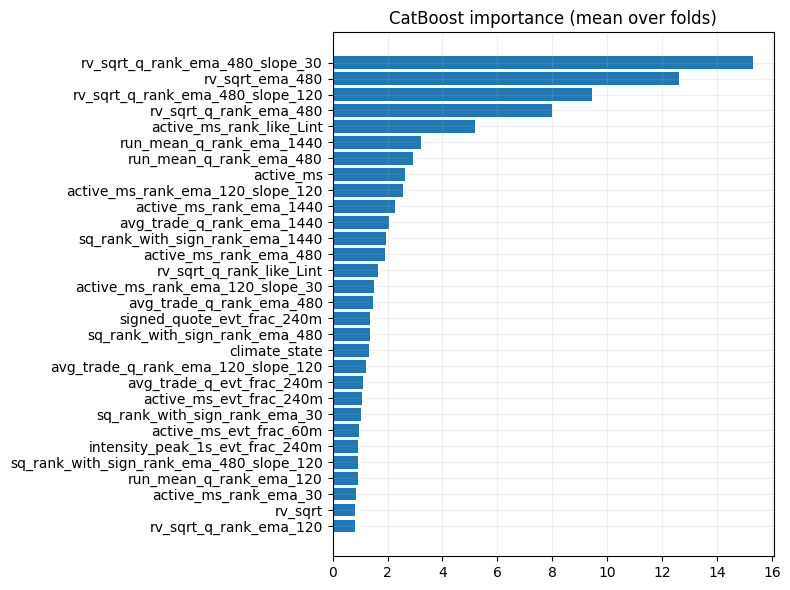

In [ ]:
plot_top_importance(fi_top60.head(30), value_col="imp_mean", title="CatBoost importance (mean over folds)")

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end
0,393667,0,2020-10-01 00:49:00,0,0.483408,2020-10-01 00:49:00,2021-01-01 00:49:00
1,393668,0,2020-10-01 00:50:00,0,0.488511,2020-10-01 00:49:00,2021-01-01 00:49:00
2,393669,0,2020-10-01 00:51:00,0,0.492608,2020-10-01 00:49:00,2021-01-01 00:49:00
3,393670,0,2020-10-01 00:52:00,0,0.475031,2020-10-01 00:49:00,2021-01-01 00:49:00
4,393671,0,2020-10-01 00:53:00,0,0.442977,2020-10-01 00:49:00,2021-01-01 00:49:00
...,...,...,...,...,...,...,...
2626910,3020577,19,2025-10-01 00:44:00,1,0.385456,2025-07-01 00:49:00,2025-10-01 00:49:00
2626911,3020578,19,2025-10-01 00:45:00,1,0.385997,2025-07-01 00:49:00,2025-10-01 00:49:00
2626912,3020579,19,2025-10-01 00:46:00,1,0.423733,2025-07-01 00:49:00,2025-10-01 00:49:00
2626913,3020580,19,2025-10-01 00:47:00,1,0.505680,2025-07-01 00:49:00,2025-10-01 00:49:00


In [ ]:
pred_pl = pl.from_pandas(
    pred[["t", "p", "y_pred"]]
)

In [ ]:
pred['y_pred'].value_counts()

,count
y_pred,
0,2495559
1,131356


In [ ]:
df2 = df1.join(
    pred_pl,
    on="t",
    how="inner"   # หรือ "left" ถ้าอยากเก็บทุกแถว
)

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df2 = make_binary(df2)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_tb30_compare_strip(
    df: pl.DataFrame,
    i: int,
    *,
    tcol="t",
    close_col="close",
    U_col="_U",
    L_col="_L",
    H=30,
    pad_left=300,
    pad_right=300,
    # truth/pred sources
    y_true_col="y_hit",
    y_pred_col="y_pred",
    p_col="p",
    use_p_as_pred=True,
    p_thr=0.55,
    # display toggles
    show_p=True,
    show_price_band=True,
    # marker sizes
    s_top=18,
    s_strip=18,
    alpha=0.85,
):
    df = df.sort(tcol)
    n = len(df)

    a = max(0, i - pad_left)
    b = min(n, i + H + pad_right)

    # window arrays
    t = df[tcol].to_numpy()[a:b]
    close = np.asarray(df[close_col].to_numpy()[a:b], dtype=float)
    U = np.asarray(df[U_col].to_numpy()[a:b], dtype=float)
    L = np.asarray(df[L_col].to_numpy()[a:b], dtype=float)

    # y_true in window
    y_true = np.asarray(df[y_true_col].to_numpy()[a:b], dtype=float)
    y_true = np.where(np.isfinite(y_true), y_true, 0.0).astype(int)

    # y_pred source
    if use_p_as_pred:
        if p_col not in df.columns:
            raise ValueError(f"p_col='{p_col}' not found in df")
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float)
        p = np.where(np.isfinite(p), p, np.nan)
        y_pred = (p >= p_thr).astype(int)
    else:
        y_pred = np.asarray(df[y_pred_col].to_numpy()[a:b], dtype=float)
        y_pred = np.where(np.isfinite(y_pred), y_pred, 0.0).astype(int)
        # still get p for plotting if available
        p = np.asarray(df[p_col].to_numpy()[a:b], dtype=float) if (p_col in df.columns) else None
        if p is not None:
            p = np.where(np.isfinite(p), p, np.nan)

    # confusion masks
    true1 = (y_true == 1)
    pred1 = (y_pred == 1)
    tp = true1 & pred1
    fp = (~true1) & pred1
    fn = true1 & (~pred1)
    tn = (~true1) & (~pred1)

    # --- build figure layout ---
    nrows = 3 if (show_p and (p is not None)) else 2
    height_ratios = [4, 1.3, 0.8] if nrows == 3 else [4, 0.9]

    fig, axes = plt.subplots(
        nrows=nrows, ncols=1, figsize=(14, 6 if nrows == 3 else 5),
        sharex=True, gridspec_kw={"height_ratios": height_ratios}
    )
    ax_price = axes[0]
    ax_p = axes[1] if nrows == 3 else None
    ax_strip = axes[2] if nrows == 3 else axes[1]

    # ===== Panel 1: price + bands =====
    ax_price.plot(t, close, label="close")
    ax_price.plot(t, U, linestyle="--", label="U[t]")
    ax_price.plot(t, L, linestyle="--", label="L[t]")

    if show_price_band and (i + H < n):
        ax_price.axvspan(df[tcol][i], df[tcol][i + H], alpha=0.12, label=f"H={H}")
    ax_price.axvline(df[tcol][i], linestyle=":", alpha=0.6)

    # mark TP/FP/FN on price (optional but helpful)
    ax_price.scatter(t[tp], close[tp], s=s_top, c="green", alpha=alpha, label="TP")
    ax_price.scatter(t[fp], close[fp], s=s_top, c="red", alpha=alpha, marker="x", label="FP")
    ax_price.scatter(t[fn], close[fn], s=s_top, c="purple", alpha=alpha, marker="x", label="FN")

    ax_price.grid(alpha=0.2)

    # ===== Panel 2: p line =====
    if ax_p is not None:
        ax_p.plot(t, p, alpha=0.7, label="p")
        ax_p.set_ylim(0, 1)
        ax_p.hlines(p_thr, t[0], t[-1], linestyles="--", alpha=0.6, label=f"p_thr={p_thr}")
        ax_p.grid(alpha=0.2)
        ax_p.legend(loc="upper left")

    # ===== Panel 3: strip (TP/FP/FN/TN) =====
    # Put them on 4 discrete y-levels to avoid overlap
    # y levels: TP=3, FP=2, FN=1, TN=0
    y_strip = np.full(len(t), np.nan, dtype=float)
    y_strip[tp] = 3
    y_strip[fp] = 2
    y_strip[fn] = 1
    y_strip[tn] = 0

    ax_strip.scatter(t[tn], np.zeros(tn.sum()), s=s_strip, c="gray", alpha=0.35, label="TN")
    ax_strip.scatter(t[fn], np.ones(fn.sum()), s=s_strip, c="purple", alpha=alpha, label="FN")
    ax_strip.scatter(t[fp], np.full(fp.sum(), 2.0), s=s_strip, c="red", alpha=alpha, label="FP")
    ax_strip.scatter(t[tp], np.full(tp.sum(), 3.0), s=s_strip, c="green", alpha=alpha, label="TP")

    ax_strip.set_yticks([0, 1, 2, 3])
    ax_strip.set_yticklabels(["TN", "FN", "FP", "TP"])
    ax_strip.grid(alpha=0.2, axis="x")

    # titles + legend
    mode = "p>=thr" if use_p_as_pred else "y_pred col"
    prec = tp.sum() / max(1, (tp.sum() + fp.sum()))
    rec = tp.sum() / max(1, (tp.sum() + fn.sum()))

    ax_price.set_title(
        f"Compare (mode={mode}) | window [{a}:{b}) | center i={i} | "
        f"TP={tp.sum()} FP={fp.sum()} FN={fn.sum()} | precision={prec:.3f} recall={rec:.3f}"
    )
    ax_price.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

    return {
        "a": a, "b": b,
        "tp": int(tp.sum()), "fp": int(fp.sum()), "fn": int(fn.sum()), "tn": int(tn.sum()),
        "precision": float(prec), "recall": float(rec),
        "mode": mode,
    }

In [ ]:
df2.filter(pl.col("y_pred") == 1)

i,t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_notional,q_p50,q_p90,…,rv_sqrt_q_rank_like_Lint,rv_sqrt_q_rank_ema_30,rv_sqrt_q_rank_ema_120,rv_sqrt_q_rank_ema_480,rv_sqrt_q_rank_ema_1440,rv_sqrt_ema_480_right,rv_sqrt_ema_1440_right,rv_sqrt_q_rank_ema_480_slope_30,rv_sqrt_q_rank_ema_480_slope_120,realized_range,realized_range_bps,rr_med_480,rr_med_480_bps,_U,_L,y_tb30,y_tb30_tie,y_tb30_width_bps,y_hit,y_hit_avail,_y_hit,_rr_q_low,_rr_q_high,_low_cnt,_high_cnt,_low_hit_sum,_high_hit_sum,p_hit_low_rr,p_hit_high_rr,alignment,contrast,_align_bucket,_contrast_bucket,regime_id,regime_cat,p,y_pred
u32,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,f64,i8,i8,f64,f64,f64,i32,i32,f64,f64,f64,f64,f64,f64,i32,i32,i32,cat,f64,i64
393738,2020-10-01 02:00:00,361.41,363.5,361.41,362.98,5185.88884,1.8807e6,1407.0,835.0,572.0,1.2996e6,581168.974681,362.661569,23.45,0.381973,2.09,0.005763,361.4,0.004335,0.004362,0.000028,42.325747,11.0,121.0,0.280939,0.000013,0.352774,910,563,347,0.27,-0.29,1406,1336.689824,1.0009,8.2,…,0.99,0.47819,0.440744,0.407775,0.385281,0.000588,0.000565,0.000104,0.000295,2.09,57.57893,0.25,7.032251,364.378098,361.581902,0.0,false,77.034448,0,1,1.0,7.591947,11.007466,4787,713,1926.0,199.0,0.40234,0.279102,0.123237,0.123237,2,1,5,"""5""",0.767575,1
393741,2020-10-01 02:03:00,362.64,363.72,362.6,363.36,5418.8526,1.9704e6,1027.0,675.0,352.0,1.3984e6,571968.469629,363.610767,17.116667,0.419425,1.12,0.00308,362.58,0.001983,0.002149,0.000165,57.572125,13.0,168.0,0.152047,0.000003,0.581871,429,219,210,0.14,-0.13,1026,1918.552241,1.5,12.0,…,0.952111,0.554127,0.462993,0.413852,0.387408,0.0006,0.000569,0.000369,0.000315,1.12,30.823426,0.255,7.116374,364.776304,361.943696,0.0,false,77.955967,0,1,1.0,7.591947,11.002535,4790,710,1929.0,199.0,0.402714,0.280282,0.122432,0.122432,2,1,5,"""5""",0.806024,1
394098,2020-10-01 08:00:00,363.97,367.0,363.94,365.09,8929.38301,3.2624e6,2033.0,1119.0,914.0,2.1827e6,1.0797e6,365.359053,33.883333,0.33808,3.06,0.008375,363.93,0.003072,0.003182,0.00011,29.48622,6.0,82.0,0.353839,0.000061,0.28937,1444,830,614,0.56,-0.59,2032,1604.737296,1.37408,8.5315,…,0.99,0.38085,0.309265,0.328827,0.355142,0.000536,0.000544,0.00016,-0.0001,3.06,83.81495,0.225,6.221906,366.334182,363.845818,-1.0,false,68.157568,1,1,1.0,7.388149,10.432648,5147,578,2041.0,199.0,0.396542,0.344291,0.052251,0.052251,2,1,5,"""5""",0.816013,1
394099,2020-10-01 08:01:00,365.09,365.39,364.01,364.15,1830.16189,667900.899556,804.0,402.0,402.0,292918.349161,374982.550395,364.940885,13.4,-0.122869,1.38,0.003781,365.09,-0.002578,-0.002578,0.0,74.651308,35.0,203.0,0.250311,0.000008,0.235367,614,278,336,0.21,-0.13,803,830.722512,1.00016,5.1618,…,0.97617,0.419258,0.320289,0.331519,0.356004,0.000545,0.000547,0.000207,-0.000084,1.38,37.896471,0.225,6.221906,365.390979,362.909021,-1.0,false,68.157568,1,1,1.0,7.388149,10.432648,5148,578,2042.0,199.0,0.396659,0.344291,0.052368,0.052368,2,1,5,"""5""",0.756458,1
394127,2020-10-01 08:29:00,366.33,370.45,366.33,368.45,13575.40667,5.0054e6,3502.0,2295.0,1207.0,3.7268e6,1.2786e6,368.712923,58.366667,0.489105,4.12,0.011174,366.34,0.00577,0.005743,-0.000027,16.975721,3.0,48.0,0.35904,0.000221,0.414167,2051,1186,865,1.02,-1.01,3501,1429.305505,1.00184,7.05293,…,0.99,0.614139,0.449916,0.369175,0.368163,0.000643,0.000581,0.001437,0.00013,4.12,111.819786,0.23,6.30599,369.722602,367.177398,-1.0,false,69.078665,1,1,1.0,7.371209,10.432648,5176,578,2070.0,199.0,0.399923,0.344291,0.055632,0.055632,2,1,5,"""5""",0.895176,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…

In [ ]:
pred[(pred["y_pred"] == 1) & (pred["fold"] == 19)]

,idx,fold,t,y,p,test_start,test_end,y_pred,month
2494738,2888405,19,2025-07-01 04:59:00,1,0.849942,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-07-01
2495259,2888926,19,2025-07-01 13:40:00,1,0.874773,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-07-01
2495262,2888929,19,2025-07-01 13:43:00,1,0.938394,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-07-01
2495263,2888930,19,2025-07-01 13:44:00,1,0.859025,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-07-01
2495264,2888931,19,2025-07-01 13:45:00,1,0.855971,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-07-01
...,...,...,...,...,...,...,...,...,...
2626355,3020022,19,2025-09-30 15:29:00,0,0.869399,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-09-01
2626356,3020023,19,2025-09-30 15:30:00,0,0.880898,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-09-01
2626357,3020024,19,2025-09-30 15:31:00,0,0.869606,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-09-01
2626363,3020030,19,2025-09-30 15:37:00,0,0.867092,2025-07-01 00:49:00,2025-10-01 00:49:00,1,2025-09-01


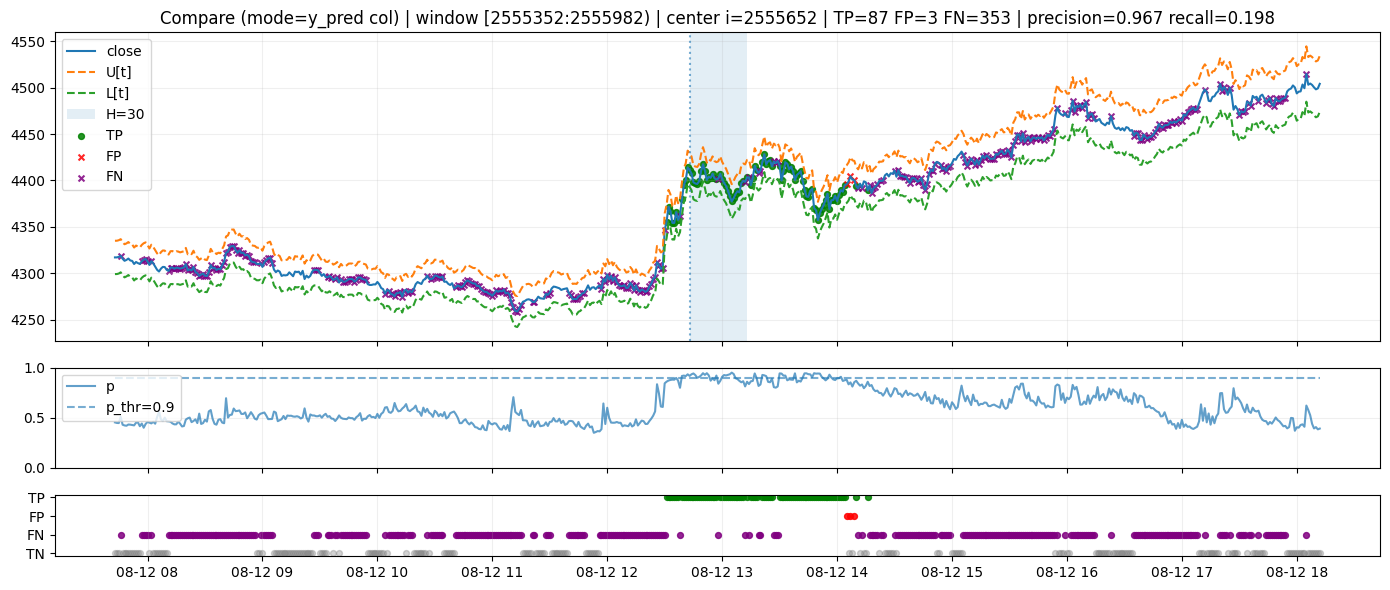

{'a': 2555352,
 'b': 2555982,
 'tp': 87,
 'fp': 3,
 'fn': 353,
 'tn': 187,
 'precision': 0.9666666666666667,
 'recall': 0.19772727272727272,
 'mode': 'y_pred col'}

In [ ]:
plot_tb30_compare_strip(df2, i=2555652, H=30, use_p_as_pred=False, p_thr=0.9)

In [ ]:
import numpy as np

def sample_with_min_gap(idxs, k=10, min_gap=5005000, seed=42):
    rng = np.random.default_rng(seed)
    idxs = np.array(sorted(idxs))

    selected = []
    candidates = idxs.copy()

    while len(selected) < k and len(candidates) > 0:
        i = rng.choice(candidates)
        selected.append(i)

        # ตัด candidate ที่อยู่ใกล้ i ออก
        candidates = candidates[np.abs(candidates - i) >= min_gap]

    return np.array(selected)

In [ ]:
candidates = pred.index[pred["p"] >= 0.9]

idxs = sample_with_min_gap(
    candidates,
    k=10,
    min_gap=100000,   # ปรับตาม time resolution ของคุณ
)

idxs

array([1328000, 2102254, 1769382, 1565523, 1938069, 2555652,  286183,
       2288006, 1085141,  387647])

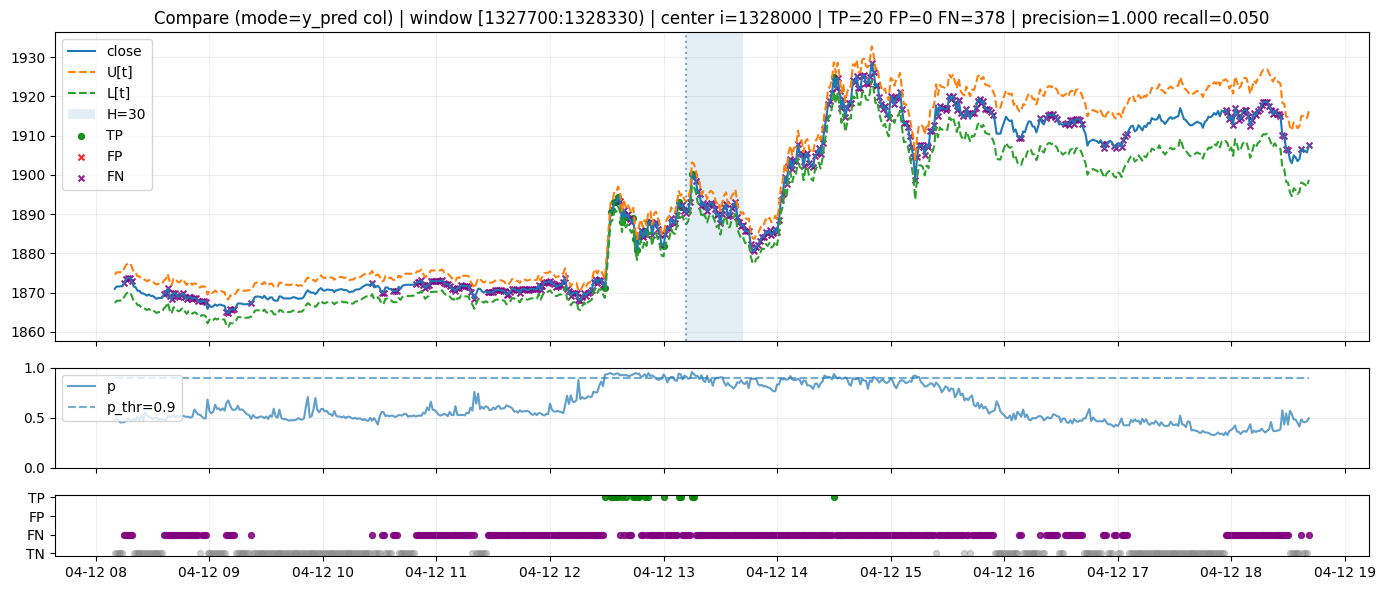

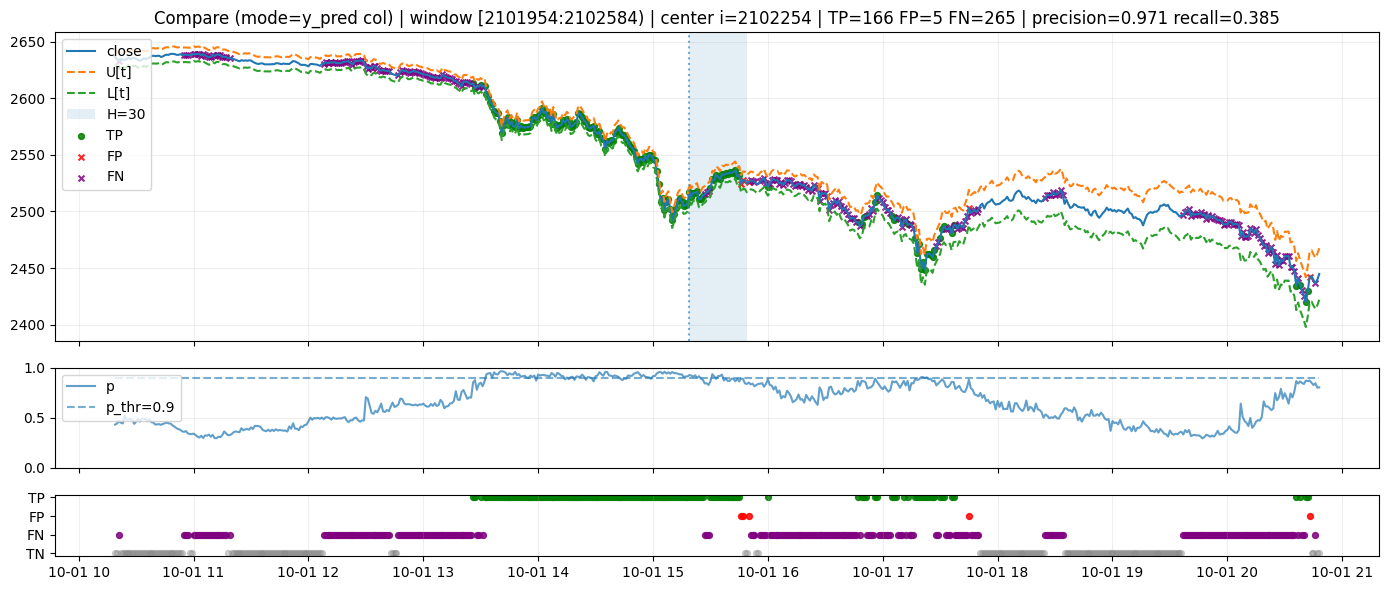

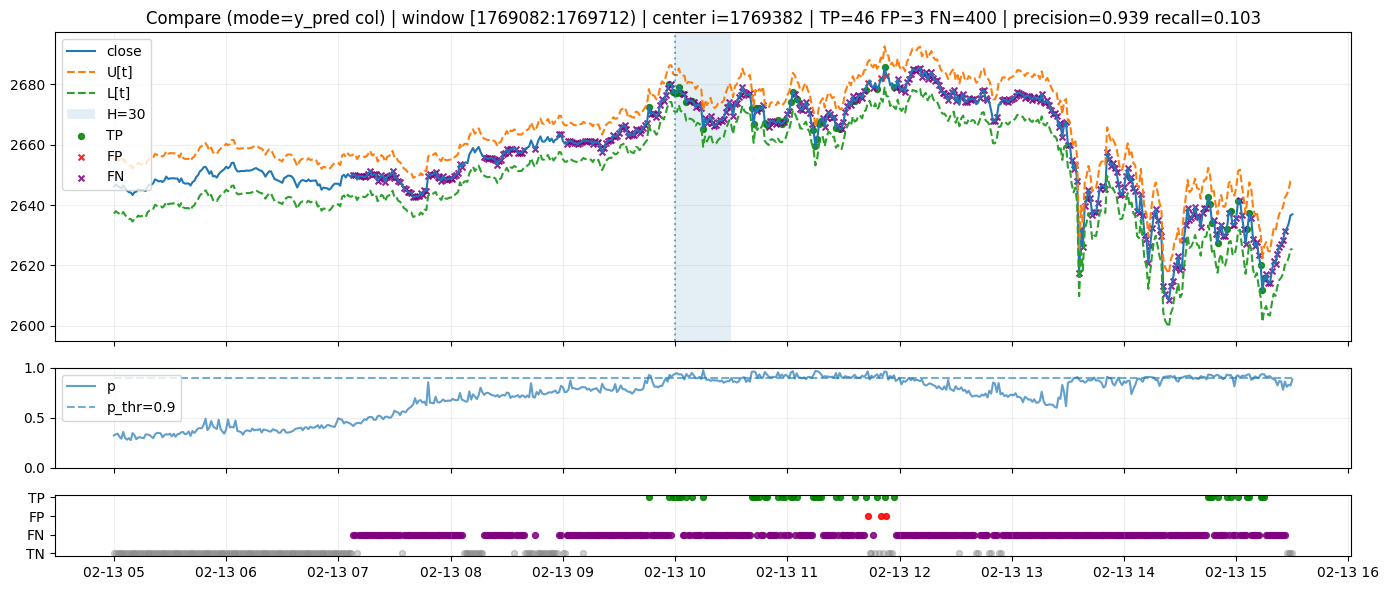

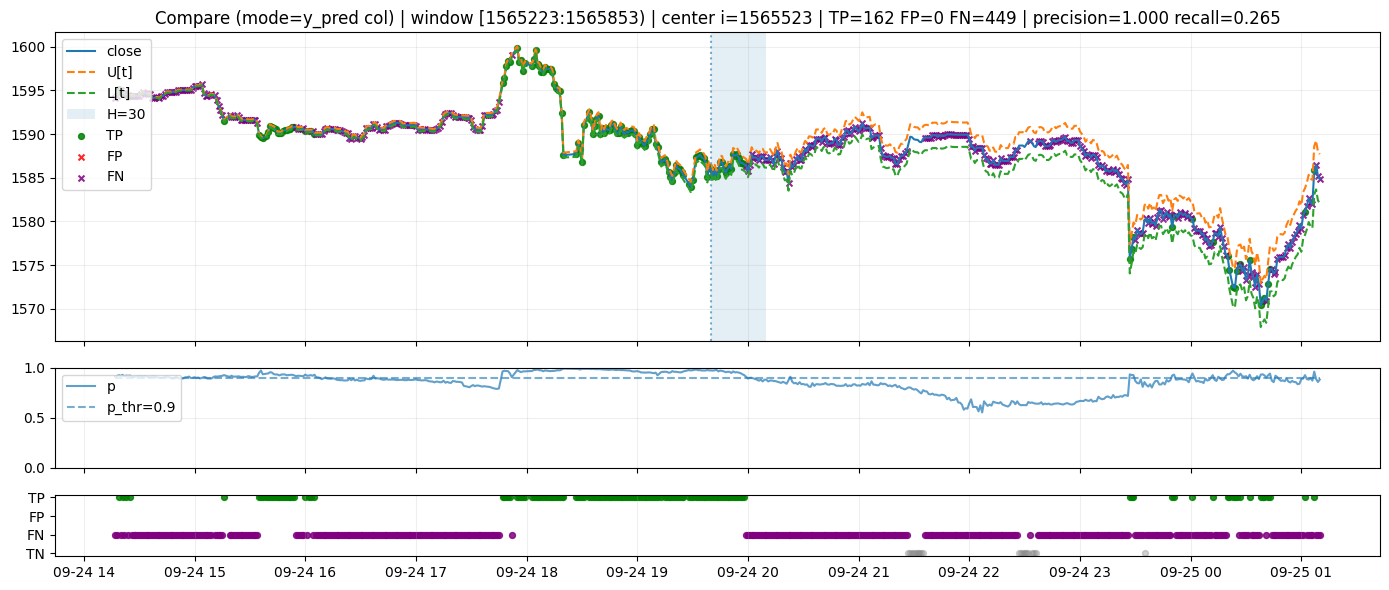

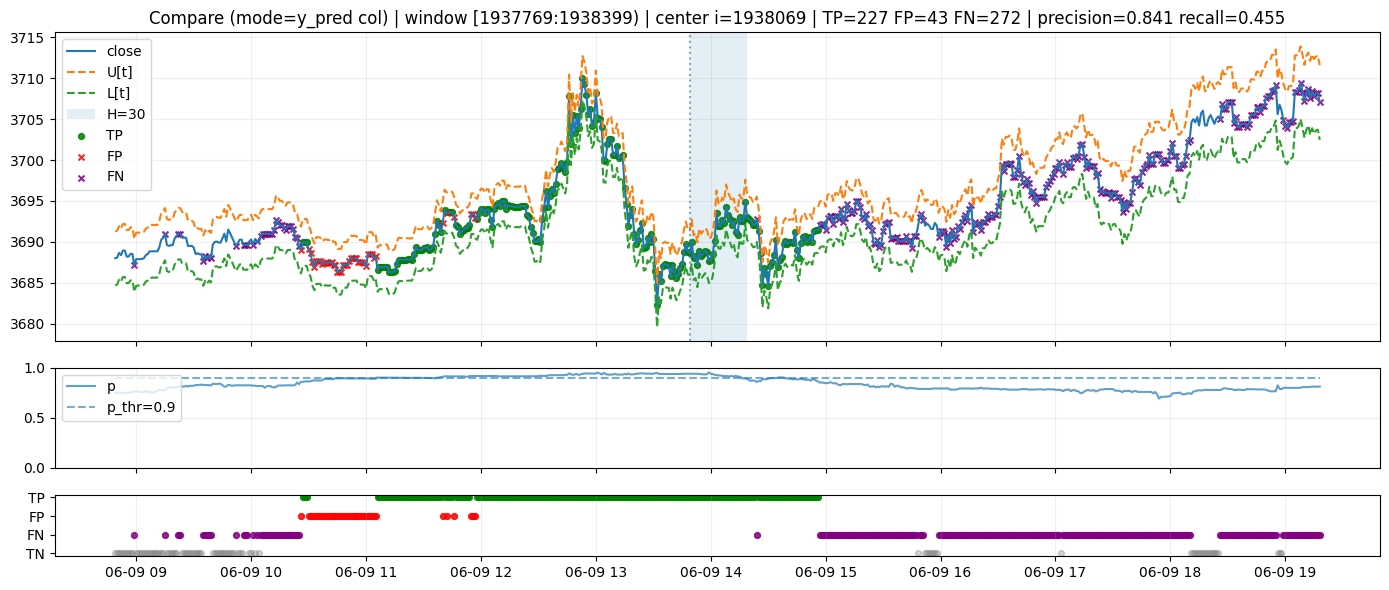

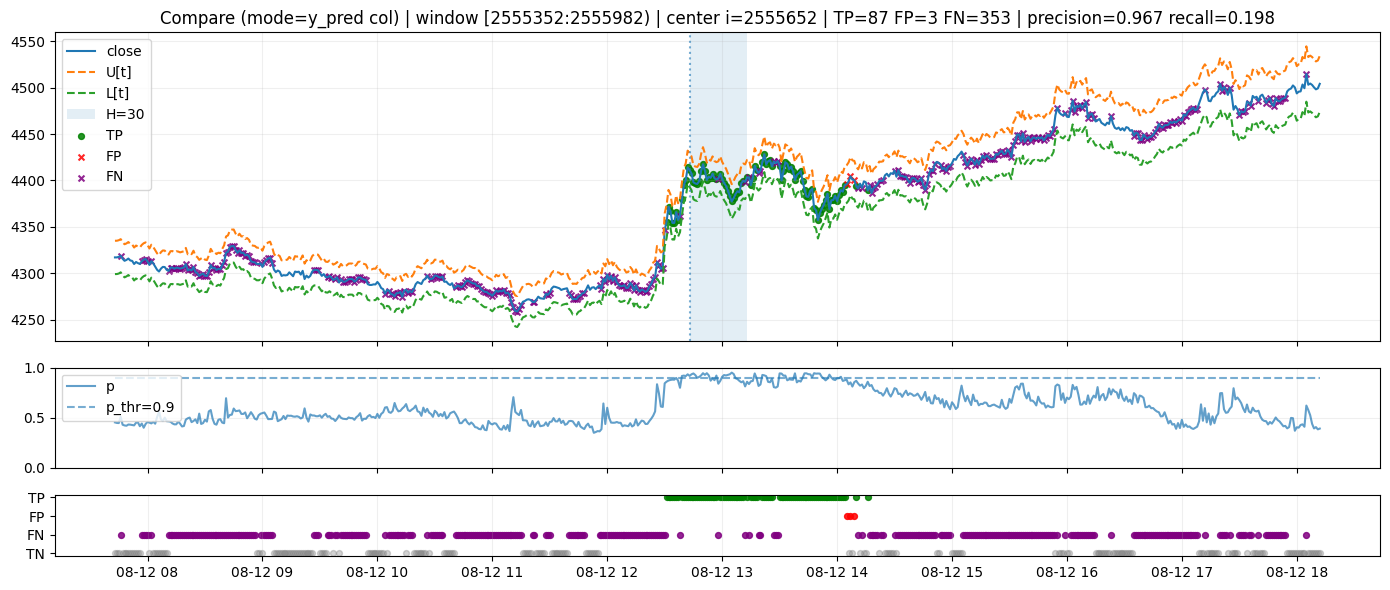

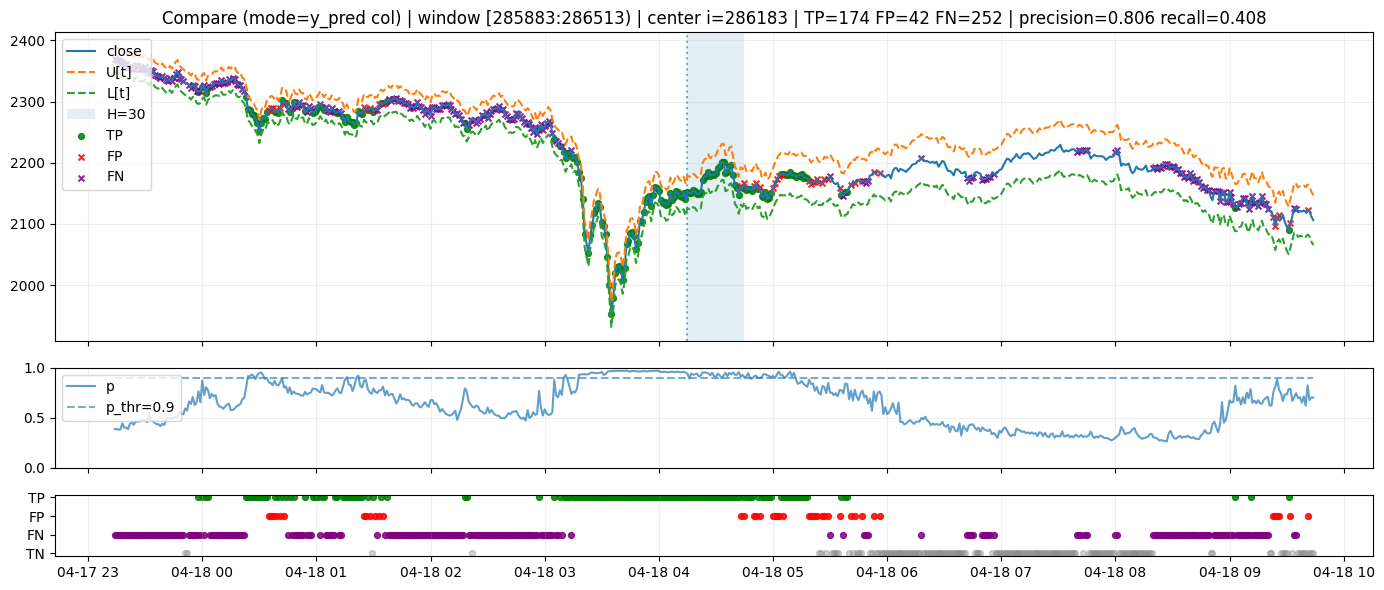

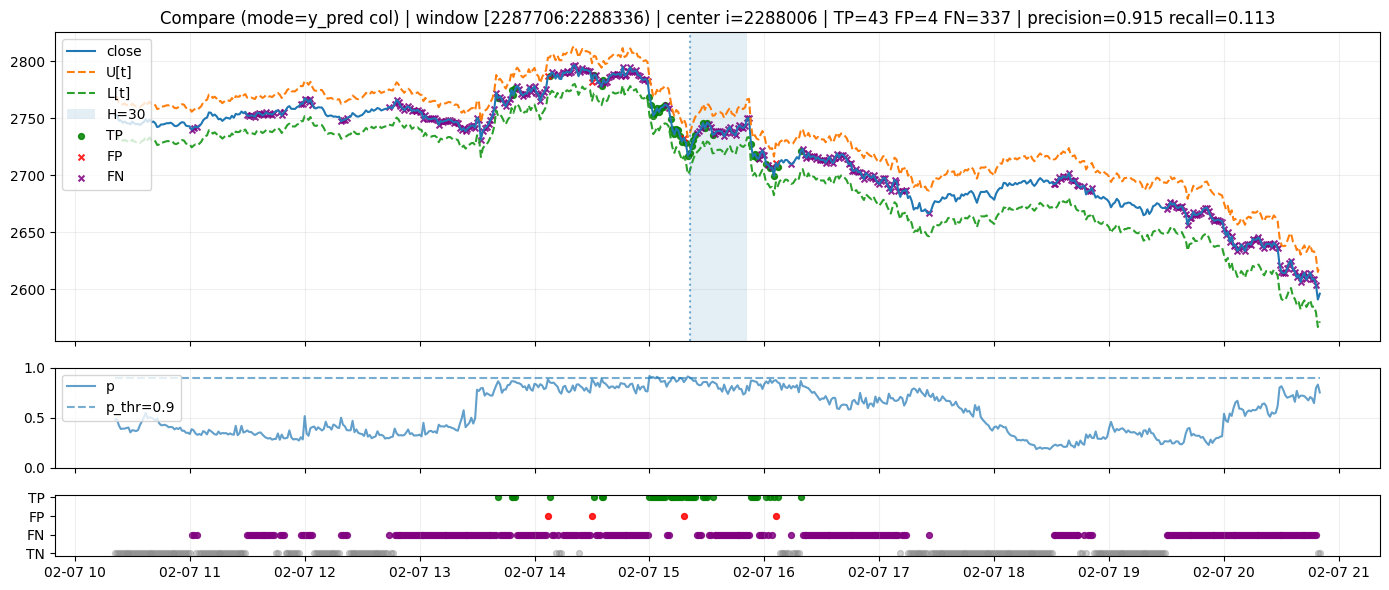

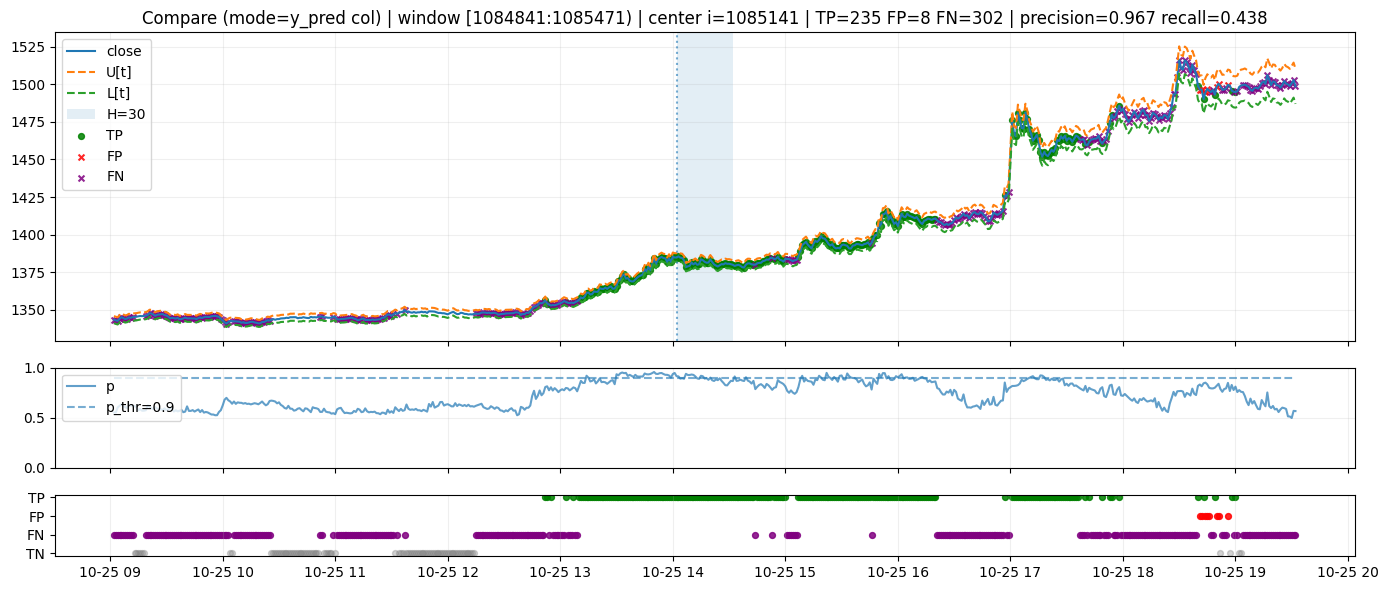

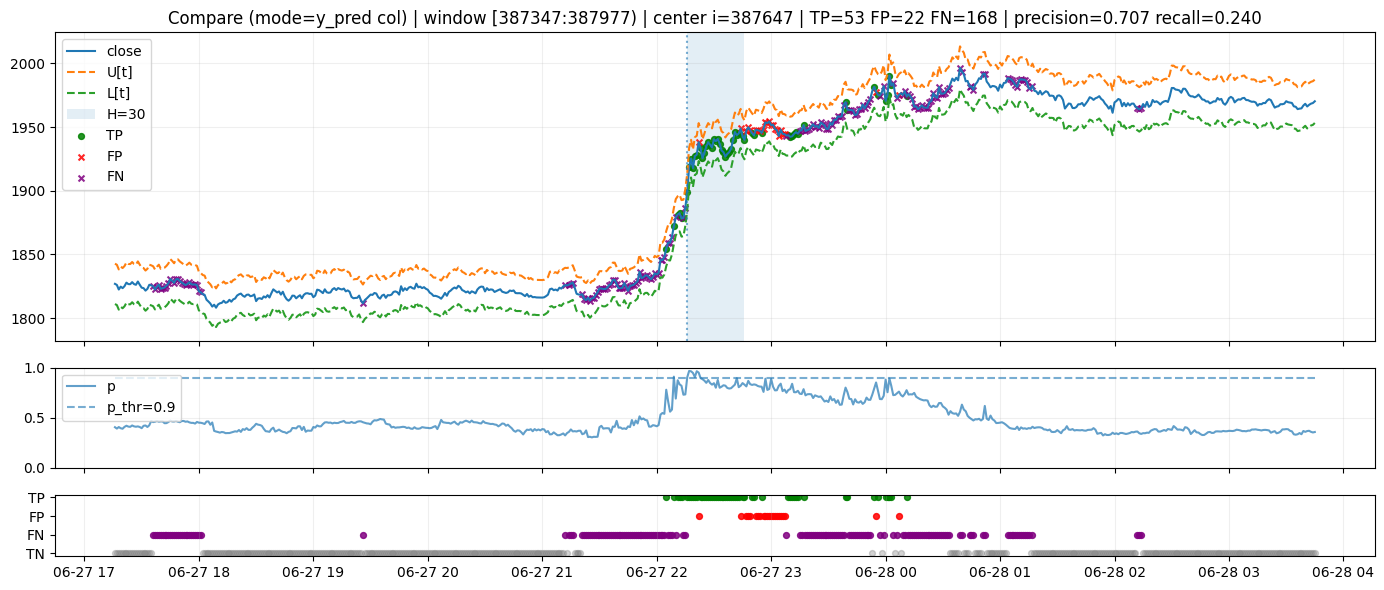

In [ ]:
for i in idxs:
    plot_tb30_compare_strip(
        df2,
        i=int(i),
        H=30,
        use_p_as_pred=False,
        p_thr=0.9,
    )

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Core helpers
# -----------------------------
def _confusion_counts(y_true: np.ndarray, y_pred: np.ndarray):
    y_true = y_true.astype(int)
    y_pred = y_pred.astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall    = tp / (tp + fn) if (tp + fn) else np.nan
    fpr       = fp / (fp + tn) if (fp + tn) else np.nan
    tpr       = recall
    acc       = (tp + tn) / (tp + fp + fn + tn) if (tp + fp + fn + tn) else np.nan
    return tp, fp, fn, tn, precision, recall, fpr, tpr, acc

def _logloss(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y*np.log(p) + (1-y)*np.log(1-p)).mean())

def _brier(y, p):
    return float(np.mean((p - y) ** 2))

# -----------------------------
# EDA tables
# -----------------------------
def per_fold_metrics(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        yhat = g[y_pred_col].astype(int).values
        p = g[p_col].astype(float).values

        tp, fp, fn, tn, precision, recall, fpr, tpr, acc = _confusion_counts(y, yhat)
        rows.append({
            "fold": fold,
            "n": len(g),
            "base_rate": float(y.mean()),
            "pred_rate": float(yhat.mean()),
            "mean_p": float(np.mean(p)),
            "p_p10": float(np.quantile(p, 0.10)),
            "p_p50": float(np.quantile(p, 0.50)),
            "p_p90": float(np.quantile(p, 0.90)),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": precision, "recall": recall, "fpr": fpr, "acc": acc,
            "logloss": _logloss(y, p),
            "brier": _brier(y, p),
        })
    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

def lift_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
    by_fold: bool = False,
    fold_col="fold",
):
    df = pred[[p_col, y_col] + ([fold_col] if by_fold else [])].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    def _one(g):
        # qcut so each bin has ~equal size
        g = g.copy()
        g["bin"] = pd.qcut(g[p_col], q=n_bins, duplicates="drop")
        out = g.groupby("bin", observed=True).agg(
            n=(y_col, "size"),
            p_mean=(p_col, "mean"),
            y_rate=(y_col, "mean"),
            p_min=(p_col, "min"),
            p_max=(p_col, "max"),
        ).reset_index(drop=True)
        base = float(g[y_col].mean())
        out["lift_vs_base"] = out["y_rate"] / (base + 1e-12)
        # sort from high-p to low-p
        out = out.sort_values("p_mean", ascending=False).reset_index(drop=True)
        return out

    if by_fold:
        res = []
        for f, g in df.groupby(fold_col):
            tmp = _one(g)
            tmp[fold_col] = f
            res.append(tmp)
        return pd.concat(res, ignore_index=True)
    else:
        return _one(df)

def calibration_table(
    pred: pd.DataFrame,
    *,
    p_col="p",
    y_col="y",
    n_bins=10,
):
    df = pred[[p_col, y_col]].copy()
    df[p_col] = df[p_col].astype(float)
    df[y_col] = df[y_col].astype(int)

    df["bin"] = pd.qcut(df[p_col], q=n_bins, duplicates="drop")
    cal = df.groupby("bin", observed=True).agg(
        n=(y_col, "size"),
        p_mean=(p_col, "mean"),
        y_rate=(y_col, "mean"),
        p_min=(p_col, "min"),
        p_max=(p_col, "max"),
    ).reset_index(drop=True)
    cal["gap(y_rate - p_mean)"] = cal["y_rate"] - cal["p_mean"]
    return cal.sort_values("p_mean").reset_index(drop=True)

def error_breakdown(
    pred: pd.DataFrame,
    *,
    y_col="y",
    y_pred_col="y_pred",
    group_cols=("climate_group", "regime_id_confirmed"),
):
    # keep only existing group cols
    group_cols = [c for c in group_cols if c in pred.columns]
    if not group_cols:
        return None

    df = pred.copy()
    y = df[y_col].astype(int).values
    yhat = df[y_pred_col].astype(int).values

    df["_TP"] = ((y == 1) & (yhat == 1)).astype(int)
    df["_FP"] = ((y == 0) & (yhat == 1)).astype(int)
    df["_FN"] = ((y == 1) & (yhat == 0)).astype(int)
    df["_TN"] = ((y == 0) & (yhat == 0)).astype(int)

    out = df.groupby(group_cols, observed=True).agg(
        n=(y_col, "size"),
        base_rate=(y_col, "mean"),
        pred_rate=(y_pred_col, "mean"),
        tp=("_TP", "sum"),
        fp=("_FP", "sum"),
        fn=("_FN", "sum"),
        tn=("_TN", "sum"),
    ).reset_index()

    out["precision"] = out["tp"] / (out["tp"] + out["fp"]).replace(0, np.nan)
    out["recall"]    = out["tp"] / (out["tp"] + out["fn"]).replace(0, np.nan)
    out["fpr"]       = out["fp"] / (out["fp"] + out["tn"]).replace(0, np.nan)
    return out.sort_values(["n"], ascending=False).reset_index(drop=True)

# -----------------------------
# Plots (matplotlib only)
# -----------------------------
def plot_calibration(cal: pd.DataFrame):
    plt.figure(figsize=(6,5))
    plt.plot(cal["p_mean"], cal["y_rate"], marker="o")
    plt.plot([0,1],[0,1], linestyle="--")
    plt.xlabel("mean predicted p")
    plt.ylabel("empirical y=1 rate")
    plt.title("Calibration (Reliability)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_lift(lift: pd.DataFrame, base_rate: float = None):
    plt.figure(figsize=(6,4))
    plt.plot(lift["y_rate"].values, marker="o")
    if base_rate is not None:
        plt.axhline(base_rate, linestyle="--")
    plt.ylabel("y=1 rate")
    plt.title("Lift by p-bin (high→low)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

def plot_rolling_p_vs_y(
    pred: pd.DataFrame,
    *,
    t_col="t",
    p_col="p",
    y_col="y",
    window=500,
    min_periods=100,
):
    df = pred[[t_col, p_col, y_col]].copy()
    df[t_col] = pd.to_datetime(df[t_col])
    df = df.sort_values(t_col)
    df["p_roll"] = df[p_col].astype(float).rolling(window, min_periods=min_periods).mean()
    df["y_roll"] = df[y_col].astype(int).rolling(window, min_periods=min_periods).mean()

    plt.figure(figsize=(10,4))
    plt.plot(df[t_col], df["p_roll"], label="rolling mean p")
    plt.plot(df[t_col], df["y_roll"], label="rolling mean y")
    plt.title(f"Rolling mean p vs y (window={window})")
    plt.xlabel("time")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

# -----------------------------
# One-call EDA runner
# -----------------------------
def run_pred_eda(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    t_col="t",
    y_col="y",
    y_pred_col="y_pred",
    p_col="p",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),
    do_plots=True,
):
    # tables
    pf = per_fold_metrics(pred, fold_col=fold_col, y_col=y_col, y_pred_col=y_pred_col, p_col=p_col)
    lift = lift_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins, by_fold=False)
    cal = calibration_table(pred, p_col=p_col, y_col=y_col, n_bins=n_bins)
    err = error_breakdown(pred, y_col=y_col, y_pred_col=y_pred_col, group_cols=group_cols)

    if do_plots:
        plot_calibration(cal)
        base = float(pred[y_col].astype(int).mean())
        plot_lift(lift, base_rate=base)
        plot_rolling_p_vs_y(pred, t_col=t_col, p_col=p_col, y_col=y_col)

    return {
        "per_fold": pf,
        "lift": lift,
        "calibration": cal,
        "error_breakdown": err,
    }

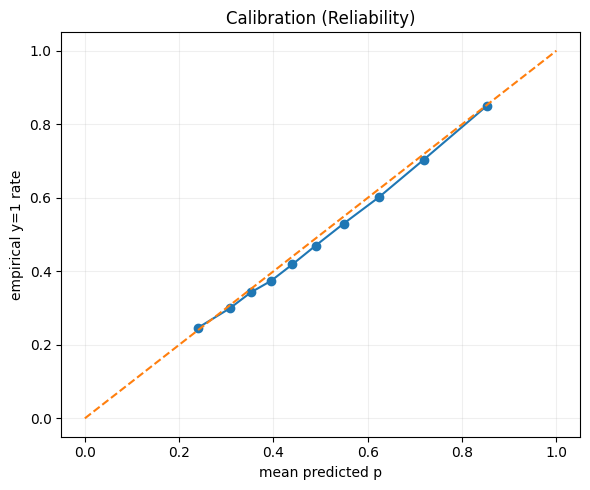

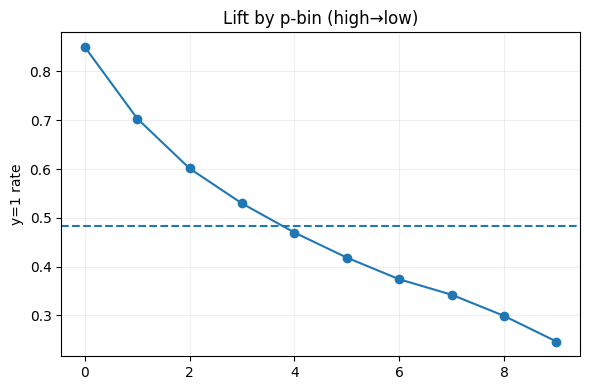

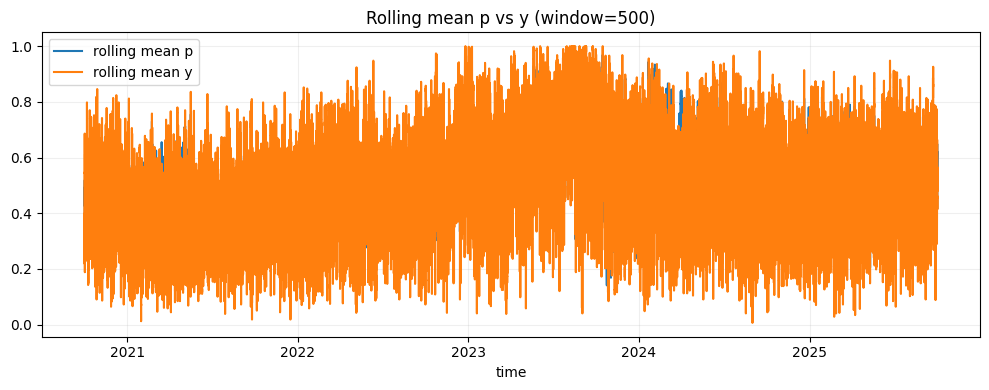

In [ ]:
out = run_pred_eda(
    pred,
    y_col="y",          # ของจริง (hit)
    y_pred_col="y_pred",
    p_col="p",
    fold_col="fold",
    t_col="t",
    n_bins=10,
    group_cols=("climate_group", "regime_id_confirmed"),  # ถ้ายังไม่ได้ join ก็ปล่อยไว้ได้
    do_plots=True,
)

In [ ]:
out["per_fold"]

,fold,n,base_rate,pred_rate,mean_p,p_p10,p_p50,p_p90,tp,fp,fn,tn,precision,recall,fpr,acc,logloss,brier
0,0,132131,0.413824,0.190917,0.452530,0.308461,0.426562,0.643125,16046,9180,38633,68272,0.636090,0.293458,0.118525,0.638139,0.639911,0.224466
1,1,129367,0.352949,0.228374,0.472060,0.333484,0.447317,0.647089,15804,13740,29856,69967,0.534931,0.346124,0.164144,0.663005,0.652359,0.229913
2,2,130622,0.373207,0.220422,0.444742,0.254772,0.428271,0.662124,15912,12880,32837,68993,0.552654,0.326407,0.157317,0.650005,0.644868,0.226579
3,3,132103,0.390574,0.106349,0.394370,0.273922,0.365494,0.555947,8857,5192,42739,75315,0.630436,0.171661,0.064491,0.637169,0.641675,0.225069
4,4,132474,0.397821,0.139703,0.405319,0.276070,0.370997,0.591373,12147,6360,40554,73413,0.656346,0.230489,0.079726,0.645863,0.632441,0.220853
5,5,129595,0.434477,0.137235,0.395250,0.242508,0.368565,0.591947,12593,5192,43713,68097,0.708069,0.223653,0.070843,0.622632,0.641580,0.225358
6,6,131030,0.457575,0.208723,0.443360,0.275175,0.425900,0.651868,19450,7899,40506,63175,0.711178,0.324405,0.111138,0.630581,0.638167,0.223525
7,7,132470,0.442847,0.151702,0.409743,0.268183,0.385429,0.593365,13972,6124,44692,67682,0.695263,0.238170,0.082974,0.616396,0.652567,0.230160
8,8,132315,0.541994,0.378030,0.518030,0.330510,0.501051,0.733139,35732,14287,35982,46314,0.714369,0.498257,0.235755,0.620081,0.632347,0.221563
9,9,129318,0.529818,0.389791,0.516050,0.298278,0.496241,0.768102,37689,12718,30826,48085,0.747694,0.550084,0.209167,0.663280,0.602618,0.208240


In [ ]:
out["lift"]

,n,p_mean,y_rate,p_min,p_max,lift_vs_base
0,262692,0.852437,0.850064,0.774922,0.993863,1.758129
1,262691,0.718445,0.703465,0.667251,0.774922,1.454929
2,262692,0.623293,0.601210,0.582606,0.667250,1.243441
3,262691,0.548573,0.529500,0.517061,0.582605,1.095130
4,262691,0.489462,0.469925,0.463429,0.517061,0.971913
5,262692,0.439854,0.418540,0.417020,0.463429,0.865637
6,262691,0.395002,0.374147,0.373266,0.417020,0.773822
7,262692,0.351882,0.342508,0.330250,0.373266,0.708385
8,262691,0.307294,0.299165,0.282355,0.330250,0.618743
9,262692,0.240101,0.246524,0.033608,0.282355,0.509870


In [ ]:
out["calibration"]

,n,p_mean,y_rate,p_min,p_max,gap(y_rate - p_mean)
0,262692,0.240101,0.246524,0.033608,0.282355,0.006424
1,262691,0.307294,0.299165,0.282355,0.330250,-0.008129
2,262692,0.351882,0.342508,0.330250,0.373266,-0.009374
3,262691,0.395002,0.374147,0.373266,0.417020,-0.020855
4,262692,0.439854,0.418540,0.417020,0.463429,-0.021315
5,262691,0.489462,0.469925,0.463429,0.517061,-0.019537
6,262691,0.548573,0.529500,0.517061,0.582605,-0.019072
7,262692,0.623293,0.601210,0.582606,0.667250,-0.022083
8,262691,0.718445,0.703465,0.667251,0.774922,-0.014980
9,262692,0.852437,0.850064,0.774922,0.993863,-0.002373


In [ ]:
import numpy as np
import pandas as pd

def sweep_thresholds_per_fold(
    pred: pd.DataFrame,
    *,
    fold_col="fold",
    y_col="y",
    p_col="p",
    thresholds=None,
):
    if thresholds is None:
        thresholds = np.linspace(0.2, 0.9, 15)

    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        base = y.mean()

        for thr in thresholds:
            yhat = (p >= thr).astype(int)

            tp = np.sum((y == 1) & (yhat == 1))
            fp = np.sum((y == 0) & (yhat == 1))
            fn = np.sum((y == 1) & (yhat == 0))
            tn = np.sum((y == 0) & (yhat == 0))

            precision = tp / (tp + fp) if (tp + fp) else np.nan
            recall    = tp / (tp + fn) if (tp + fn) else np.nan
            trade_rate = yhat.mean()

            rows.append({
                "fold": fold,
                "thr": float(thr),
                "n": len(g),
                "base_rate": float(base),
                "trade_rate": float(trade_rate),
                "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
                "precision": float(precision) if precision==precision else np.nan,
                "recall": float(recall) if recall==recall else np.nan,
            })

    return pd.DataFrame(rows).sort_values(["fold","thr"]).reset_index(drop=True)

In [ ]:
sweep = sweep_thresholds_per_fold(pred)

In [ ]:
sweep[sweep["thr"]==0.60].sort_values("precision")

,fold,thr,n,base_rate,trade_rate,tp,fp,fn,tn,precision,recall
22,1,0.55,129367,0.352949,0.228374,15804,13740,29856,69967,0.534931,0.346124
37,2,0.55,130622,0.373207,0.220422,15912,12880,32837,68993,0.552654,0.326407
262,17,0.55,129596,0.456982,0.452823,36299,22385,22924,47988,0.618550,0.612921
52,3,0.55,132103,0.390574,0.106349,8857,5192,42739,75315,0.630436,0.171661
7,0,0.55,132131,0.413824,0.190917,16046,9180,38633,68272,0.636090,0.293458
247,16,0.55,132471,0.460335,0.403922,34393,19115,26588,52375,0.642764,0.563995
67,4,0.55,132474,0.397821,0.139703,12147,6360,40554,73413,0.656346,0.230489
202,13,0.55,131029,0.507109,0.505636,43771,22482,22675,42101,0.660664,0.658745
277,18,0.55,131037,0.481337,0.380328,33249,16588,29824,51376,0.667155,0.527151
217,14,0.55,131000,0.525229,0.540252,47471,23302,21334,38893,0.670750,0.689935


In [ ]:
sweep.groupby("q")[["precision","recall","trade_rate"]].mean().reset_index()

In [ ]:
def sweep_top(pred, thresholds=(0.50,0.60,0.70,0.80,0.90), fold_col="fold", y_col="y", p_col="p"):
    out = []
    for thr in thresholds:
        rows = sweep_thresholds_per_fold(
            pred,
            fold_col=fold_col,
            y_col=y_col,
            p_col=p_col,
            thresholds=[thr],   # ต้องเป็น list/iterable
        )
        out.append(rows)
    return pd.concat(out, ignore_index=True)

p_sweep = sweep_top(pred, thresholds=(0.50,0.60,0.70,0.80,0.90), p_col="p")

In [ ]:
p_sweep

,fold,thr,n,base_rate,trade_rate,tp,fp,fn,tn,precision,recall
0,0,0.5,132131,0.413824,0.280850,21868,15241,32811,62211,0.589291,0.399934
1,1,0.5,129367,0.352949,0.338193,20992,22759,24668,60948,0.479806,0.459746
2,2,0.5,130622,0.373207,0.314419,20943,20127,27806,61746,0.509934,0.429609
3,3,0.5,132103,0.390574,0.169867,13400,9040,38196,71467,0.597148,0.259710
4,4,0.5,132474,0.397821,0.202100,16510,10263,36191,69510,0.616666,0.313277
...,...,...,...,...,...,...,...,...,...,...,...
95,15,0.9,132438,0.491007,0.003730,482,12,64546,67398,0.975709,0.007412
96,16,0.9,132471,0.460335,0.018344,2265,165,58716,71325,0.932099,0.037143
97,17,0.9,129596,0.456982,0.017964,2194,134,57029,70239,0.942440,0.037046
98,18,0.9,131037,0.481337,0.017804,2147,186,60926,67778,0.920274,0.034040


In [ ]:
# ดูค่าเฉลี่ยข้าม fold
p_sweep.groupby("thr")[["precision","recall","trade_rate","base_rate"]].mean().reset_index()

,thr,precision,recall,trade_rate,base_rate
0,0.5,0.643524,0.559107,0.429972,0.483364
1,0.6,0.716385,0.390526,0.277373,0.483364
2,0.7,0.791844,0.250746,0.166355,0.483364
3,0.8,0.868059,0.128939,0.080553,0.483364
4,0.9,0.942377,0.034748,0.020782,0.483364


In [ ]:
def pick_thr_by_precision(sweep: pd.DataFrame, target_precision=0.70):
    out = []
    for fold, g in sweep.groupby("fold"):
        gg = g.dropna(subset=["precision"]).copy()
        gg = gg[gg["precision"] >= target_precision]
        if len(gg) == 0:
            # ถ้าไม่มี threshold ไหนถึงเป้า เลือกที่ precision สูงสุด
            best = g.dropna(subset=["precision"]).sort_values(["precision","trade_rate"], ascending=[False,True]).head(1)
        else:
            # ถ้ามีหลายอันถึงเป้า เลือก trade_rate ต่ำสุด (กัน FP/overtrade)
            best = gg.sort_values(["trade_rate","thr"], ascending=[True,True]).head(1)
        out.append(best)

    return pd.concat(out, ignore_index=True).sort_values("fold").reset_index(drop=True)

In [ ]:
sweep = sweep_thresholds_per_fold(pred)
thr_by_fold = pick_thr_by_precision(sweep, target_precision=0.70)

In [ ]:
thr_by_fold

,fold,thr,n,base_rate,trade_rate,tp,fp,fn,tn,precision,recall
0,0,0.90,132131,0.413824,0.003194,402,20,54277,77432,0.952607,0.007352
1,1,0.90,129367,0.352949,0.001322,147,24,45513,83683,0.859649,0.003219
2,2,0.90,130622,0.373207,0.005948,685,92,48064,81781,0.881596,0.014052
3,3,0.90,132103,0.390574,0.001181,149,7,51447,80500,0.955128,0.002888
4,4,0.90,132474,0.397821,0.000717,95,0,52606,79773,1.000000,0.001803
5,5,0.90,129595,0.434477,0.000494,63,1,56243,73288,0.984375,0.001119
6,6,0.90,131030,0.457575,0.001122,140,7,59816,71067,0.952381,0.002335
7,7,0.85,132470,0.442847,0.000113,15,0,58649,73806,1.000000,0.000256
8,8,0.90,132315,0.541994,0.004829,630,9,71084,60592,0.985915,0.008785
9,9,0.90,129318,0.529818,0.014499,1849,26,66666,60777,0.986133,0.026987


In [ ]:
def topq_policy_per_fold(pred: pd.DataFrame, *, fold_col="fold", y_col="y", p_col="p", q=0.10):
    rows = []
    for fold, g in pred.groupby(fold_col):
        y = g[y_col].astype(int).values
        p = g[p_col].astype(float).values

        thr = np.quantile(p, 1 - q)
        yhat = (p >= thr).astype(int)

        tp = np.sum((y == 1) & (yhat == 1))
        fp = np.sum((y == 0) & (yhat == 1))
        fn = np.sum((y == 1) & (yhat == 0))
        tn = np.sum((y == 0) & (yhat == 0))

        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall    = tp / (tp + fn) if (tp + fn) else np.nan

        rows.append({
            "fold": fold,
            "q": q,
            "thr": float(thr),
            "n": len(g),
            "base_rate": float(y.mean()),
            "trade_rate": float(yhat.mean()),
            "precision": float(precision) if precision==precision else np.nan,
            "recall": float(recall) if recall==recall else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        })

    return pd.DataFrame(rows).sort_values("fold").reset_index(drop=True)

In [ ]:
top10 = topq_policy_per_fold(pred, q=0.10)
top5  = topq_policy_per_fold(pred, q=0.05)
top1  = topq_policy_per_fold(pred, q=0.01)

In [ ]:
top10

,fold,q,thr,n,base_rate,trade_rate,precision,recall,tp,fp,fn,tn
0,0,0.1,0.643125,132131,0.413824,0.100007,0.714621,0.172699,9443,3771,45236,73681
1,1,0.1,0.647089,129367,0.352949,0.100002,0.620932,0.175931,8033,4904,37627,78803
2,2,0.1,0.662124,130622,0.373207,0.100006,0.652453,0.174834,8523,4540,40226,77333
3,3,0.1,0.555947,132103,0.390574,0.100005,0.637575,0.163249,8423,4788,43173,75719
4,4,0.1,0.591373,132474,0.397821,0.100005,0.697690,0.175386,9243,4005,43458,75768
5,5,0.1,0.591947,129595,0.434477,0.100004,0.740895,0.170532,9602,3358,46704,69931
6,6,0.1,0.651868,131030,0.457575,0.100000,0.797375,0.174261,10448,2655,49508,68419
7,7,0.1,0.593365,132470,0.442847,0.100000,0.746131,0.168485,9884,3363,48780,70443
8,8,0.1,0.733139,132315,0.541994,0.100004,0.859054,0.158505,11367,1865,60347,58736
9,9,0.1,0.768102,129318,0.529818,0.100002,0.907516,0.171291,11736,1196,56779,59607


In [ ]:
top5

,fold,q,thr,n,base_rate,trade_rate,precision,recall,tp,fp,fn,tn,edge,lift
0,0,0.05,0.731471,132131,0.413824,0.050003,0.797033,0.096308,5266,1341,49413,76111,0.383209,1.926020
1,1,0.05,0.731709,129367,0.352949,0.050005,0.701963,0.099452,4541,1928,41119,81779,0.349014,1.988850
2,2,0.05,0.752153,130622,0.373207,0.050007,0.742345,0.099469,4849,1683,43900,80190,0.369139,1.989100
3,3,0.05,0.622978,132103,0.390574,0.050006,0.699364,0.089542,4620,1986,46976,78521,0.308790,1.790606
4,4,0.05,0.668130,132474,0.397821,0.050002,0.763889,0.096013,5060,1564,47641,78209,0.366067,1.920180
5,5,0.05,0.676245,129595,0.434477,0.050002,0.796914,0.091713,5164,1316,51142,71973,0.362437,1.834192
6,6,0.05,0.720881,131030,0.457575,0.050004,0.845391,0.092384,5539,1013,54417,70061,0.387816,1.847547
7,7,0.05,0.649762,132470,0.442847,0.050011,0.808604,0.091317,5357,1268,53307,72538,0.365756,1.825920
8,8,0.05,0.796892,132315,0.541994,0.050002,0.913089,0.084237,6041,575,65673,60026,0.371095,1.684684
9,9,0.05,0.833923,129318,0.529818,0.050001,0.940767,0.088783,6083,383,62432,60420,0.410949,1.775642


In [ ]:
def sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20), fold_col="fold", y_col="y", p_col="p"):
    out = []
    for q in qs:
        rows = topq_policy_per_fold(pred, fold_col=fold_col, y_col=y_col, p_col=p_col, q=q)
        rows["q"] = q
        out.append(rows)
    return pd.concat(out, ignore_index=True)

q_sweep = sweep_topq(pred, qs=(0.01,0.02,0.05,0.10,0.20))
# ดูค่าเฉลี่ยข้าม fold

,q,precision,recall,trade_rate
0,0.01,0.929448,0.019630,0.010004
1,0.02,0.903692,0.038074,0.020003
2,0.05,0.856176,0.089792,0.050004
3,0.10,0.803075,0.167687,0.100003
4,0.20,0.735282,0.305598,0.200003


In [ ]:
q_sweep.groupby("q")[["precision","recall","trade_rate","base_rate"]].mean().reset_index()

,q,precision,recall,trade_rate,base_rate
0,0.01,0.929448,0.019630,0.010004,0.483364
1,0.02,0.903692,0.038074,0.020003,0.483364
2,0.05,0.856176,0.089792,0.050004,0.483364
3,0.10,0.803075,0.167687,0.100003,0.483364
4,0.20,0.735282,0.305598,0.200003,0.483364


In [ ]:
top5 = topq_policy_per_fold(pred, q=0.05)
top5["edge"] = top5["precision"] - top5["base_rate"]
top5["lift"] = top5["precision"] / (top5["base_rate"] + 1e-12)
top5[["fold","base_rate","precision","edge","lift","trade_rate"]].sort_values("edge")

,fold,base_rate,precision,edge,lift,trade_rate
11,11,0.712062,0.991979,0.279917,1.393108,0.050006
3,3,0.390574,0.699364,0.308790,1.790606,0.050006
10,10,0.625039,0.948052,0.323013,1.516788,0.050000
1,1,0.352949,0.701963,0.349014,1.988850,0.050005
12,12,0.569279,0.919825,0.350546,1.615772,0.050004
5,5,0.434477,0.796914,0.362437,1.834192,0.050002
7,7,0.442847,0.808604,0.365756,1.825920,0.050011
4,4,0.397821,0.763889,0.366067,1.920180,0.050002
2,2,0.373207,0.742345,0.369139,1.989100,0.050007
8,8,0.541994,0.913089,0.371095,1.684684,0.050002


In [ ]:
def topq_precision_per_fold(pred, q=0.05, fold_col="fold", y_col="y", p_col="p"):
    out = []
    for f, g in pred.groupby(fold_col):
        thr = g[p_col].quantile(1-q)
        sel = g[g[p_col] >= thr]
        out.append({
            "fold": f,
            "base": g[y_col].mean(),
            "thr": thr,
            "prec_topq": sel[y_col].mean(),
            "lift_topq": sel[y_col].mean() / (g[y_col].mean() + 1e-12),
        })
    return pd.DataFrame(out).sort_values("fold")

topq_precision_per_fold(pred, q=0.05)

,fold,base,thr,prec_topq,lift_topq
0,0,0.413824,0.731471,0.797033,1.926020
1,1,0.352949,0.731709,0.701963,1.988850
2,2,0.373207,0.752153,0.742345,1.989100
3,3,0.390574,0.622978,0.699364,1.790606
4,4,0.397821,0.668130,0.763889,1.920180
5,5,0.434477,0.676245,0.796914,1.834192
6,6,0.457575,0.720881,0.845391,1.847547
7,7,0.442847,0.649762,0.808604,1.825920
8,8,0.541994,0.796892,0.913089,1.684684
9,9,0.529818,0.833923,0.940767,1.775642


# Cat Tree

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 25.7 MB/s eta 0:00:00


In [ ]:
import polars as pl
import numpy as np

def add_realized_range_and_roll_median(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    high_col: str = "high",
    low_col: str = "low",
    close_col: str = "close",
    missing_col: str = "is_missing_fill",
    # rolling settings
    win: int = 480,          # เช่น 480 นาที = 8 ชั่วโมง
    min_periods: int = 50,   # กันช่วงต้นที่ข้อมูลน้อย
    # output names
    out_range: str = "realized_range",
    out_range_bps: str = "realized_range_bps",
    out_med: str = "rr_med_480",
    out_med_bps: str = "rr_med_480_bps",
) -> pl.DataFrame:
    """
    realized_range      = high - low
    realized_range_bps  = (high-low)/close * 1e4
    rr_med_*            = rolling median ของ realized_range (robust scale)
    rr_med_*_bps        = rolling median ในหน่วย bps (แนะนำเอาไปตั้ง barrier)
    """
    df = df.sort(tcol)

    # range (absolute) + normalized (bps)
    out = df.with_columns([
        (pl.col(high_col) - pl.col(low_col))
            .cast(pl.Float64)
            .alias(out_range),

        ((pl.col(high_col) - pl.col(low_col)) / pl.col(close_col) * 1e4)
            .cast(pl.Float64)
            .alias(out_range_bps),
    ])

    # mask missing-fill rows -> null (กัน data discontinuity)
    out = out.with_columns([
        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range))
          .alias(out_range),

        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range_bps))
          .alias(out_range_bps),
    ])

    # rolling median (robust to spikes)
    out = out.with_columns([
        pl.col(out_range)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med),

        pl.col(out_range_bps)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med_bps),
    ])

    return out

In [ ]:
df = add_realized_range_and_roll_median(df, win=480, min_periods=50)

/tmp/ipython-input-2235444625.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)
/tmp/ipython-input-2235444625.py:60: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)


In [ ]:
import math
import numpy as np
import polars as pl

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    roc_auc_score, f1_score, confusion_matrix,
    precision_score
)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

In [ ]:
def sanity_check_time(df: pl.DataFrame, tcol="t") -> None:
    dt = df.schema[tcol]
    assert dt in (pl.Datetime, pl.Datetime("us"), pl.Datetime("ms"), pl.Datetime("ns")), f"{tcol} dtype is {dt}, not Datetime"
    # sorted?
    t = df[tcol].to_numpy()
    assert np.all(t[1:] >= t[:-1]), f"{tcol} is not monotonic non-decreasing"
sanity_check_time(df)

In [ ]:
def add_tb30_label_with_report(
    df: pl.DataFrame,
    *,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    rr_win=480,
    rr_min_periods=50,
    rr_use_bps=True,
    missing_col="is_missing_fill",
    H=30,
    k=5.0,
    out_col="y_tb30",
    tie_to_nan=True,
):
    df = df.sort(tcol)
    sanity_check_time(df, tcol=tcol)

    # build realized range scale (robust)
    rr = (pl.col(high_col) - pl.col(low_col)).cast(pl.Float64)
    if rr_use_bps:
        rr = (rr / pl.col(close_col) * 1e4).alias("_rr_bps")
    else:
        rr = rr.alias("_rr_abs")

    df = df.with_columns(rr)

    scale_col = "_rr_bps" if rr_use_bps else "_rr_abs"
    df = df.with_columns(
        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(scale_col))
          .rolling_median(window_size=rr_win, min_periods=rr_min_periods)
          .alias("_rr_med")
    )

    missing = df[missing_col].to_numpy().astype(bool)
    close = df[close_col].to_numpy().astype(float)
    high  = df[high_col].to_numpy().astype(float)
    low   = df[low_col].to_numpy().astype(float)
    rr_med = df["_rr_med"].to_numpy()

    n = len(df)
    y = np.full(n, np.nan, dtype=float)
    tie = np.zeros(n, dtype=bool)

    scale = k * np.sqrt(H)

    if rr_use_bps:
        dist = close * (np.asarray(rr_med, dtype=float) / 1e4) * scale
        # width in bps: (U-L)/close*1e4 = 2*dist/close*1e4
        width_bps = 2.0 * (np.asarray(rr_med, dtype=float)) * scale
    else:
        dist = np.asarray(rr_med, dtype=float) * scale
        width_bps = (2.0 * dist / close) * 1e4

    U = close + dist
    L = close - dist

    for i in range(n):
        if missing[i] or not np.isfinite(U[i]) or not np.isfinite(L[i]) or (i + H >= n):
            y[i] = np.nan
            continue

        ui, li = U[i], L[i]
        hit = 0.0
        tied = False

        for j in range(i + 1, i + H + 1):
            up = high[j] >= ui
            dn = low[j] <= li
            if up and dn:
                tied = True
                hit = np.nan if tie_to_nan else 0.0
                break
            if up:
                hit = +1.0
                break
            if dn:
                hit = -1.0
                break

        y[i] = hit
        tie[i] = tied

    out = (
        df.with_columns([
            pl.Series(out_col, y),
            pl.Series(out_col + "_tie", tie),
            pl.Series(out_col + "_width_bps", width_bps),
        ])
        .drop(["_rr_bps","_rr_abs","_rr_med"], strict=False)
    )

    valid = out.filter(pl.col(out_col).is_not_null() & pl.col(out_col).is_finite())

    rep = valid.select([
        pl.col(out_col + "_tie").mean().alias("tie_rate"),
        pl.col(out_col + "_width_bps").median().alias("width_bps_median"),
        pl.col(out_col + "_width_bps").quantile(0.90).alias("width_bps_p90"),
        pl.col(out_col).value_counts().alias("label_counts"),
    ])

    return out, rep

In [ ]:
df1, label_rep = add_tb30_label_with_report(df, H=30, out_col="y_tb30",k=1,rr_use_bps=True,rr_win=480)
print(label_rep)

# drop missing-fill rows + invalid labels
df1 = df1.filter((~pl.col("is_missing_fill")) & pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())

/tmp/ipython-input-3135928043.py:34: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=rr_win, min_periods=rr_min_periods)


shape: (3, 4)
┌──────────┬──────────────────┬───────────────┬───────────────┐
│ tie_rate ┆ width_bps_median ┆ width_bps_p90 ┆ label_counts  │
│ ---      ┆ ---              ┆ ---           ┆ ---           │
│ f64      ┆ f64              ┆ f64           ┆ struct[2]     │
╞══════════╪══════════════════╪═══════════════╪═══════════════╡
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {1.0,731625}  │
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {-1.0,770790} │
│ 0.0      ┆ 96.08024         ┆ 197.109885    ┆ {0.0,1650534} │
└──────────┴──────────────────┴───────────────┴───────────────┘


In [ ]:
# Drop rows with missing fill or label NaN
df1 = df1.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("y_tb30").is_not_null())
)

In [ ]:
summary = (
    df1.select(pl.col("y_tb30"))
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .group_by("y_tb30")
       .len()
       .with_columns((pl.col("len") / pl.col("len").sum()).alias("pct"))
       .sort("y_tb30")
)

summary

y_tb30,len,pct
i8,u32,f64
-1,770790,0.244466
0,1650534,0.523489
1,731625,0.232045


In [ ]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 

In [ ]:
FEATURES = [
    # ─────────────────────────────
    # A) Market Direction / Pressure
    # ─────────────────────────────
    "signed_quote",
    "sq_rank_with_sign",
    "sq_rank_with_sign_rank_ema_30",
    "sq_rank_with_sign_rank_ema_120",
    "sq_rank_with_sign_rank_ema_480",
    "sq_rank_with_sign_rank_ema_480_slope_120",
    "signed_quote_evt_frac_60m",
    "signed_quote_evt_frac_240m",

    # ─────────────────────────────
    # B) Activity / Participation
    # ─────────────────────────────
    "active_ms",
    "active_ms_rank_ema_30",
    "active_ms_rank_ema_120",
    "active_ms_rank_ema_480",
    "active_ms_rank_ema_120_slope_120",
    "active_ms_evt_frac_60m",
    "active_ms_evt_frac_240m",

    # robust slope state (activity)
    "active_ms_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # C) Trade Size / Commitment
    # ─────────────────────────────
    "avg_trade_q",
    "avg_trade_q_rank_ema_30",
    "avg_trade_q_rank_ema_120",
    "avg_trade_q_rank_ema_480",
    "avg_trade_q_rank_ema_120_slope_120",
    "avg_trade_q_evt_frac_60m",
    "avg_trade_q_evt_frac_240m",

    # robust slope state (size)
    "avg_trade_q_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # D) Run / Continuity
    # ─────────────────────────────
    "run_mean",
    "run_mean_q_rank_ema_30",
    "run_mean_q_rank_ema_120",
    "run_mean_q_rank_ema_480",
    "run_mean_q_rank_ema_120_slope_120",
    "run_max",
    "run_max_evt_frac_60m",

    # robust slope state (continuity)
    "run_mean_q_rank_ema_120_slope_120_bin3_robust",

    # ─────────────────────────────
    # E) Volatility / Range (TB-aligned)
    # ─────────────────────────────
    "rv_sqrt",
    "rv_sqrt_q_rank_ema_30",
    "rv_sqrt_q_rank_ema_120",
    "rv_sqrt_q_rank_ema_480",
    "rv_sqrt_ema_480",
    "rv_sqrt_q_rank_ema_480_slope_120",
    "rv_sqrt_evt_frac_60m",
    "realized_range",
    "realized_range_bps",
    "rr_med_480_bps",

    # ─────────────────────────────
    # F) Intensity / Burst
    # ─────────────────────────────
    "intensity_peak_1s",
    "intensity_peak_1s_evt_frac_60m",
    "intensity_peak_1s_evt_frac_240m",

    # ─────────────────────────────
    # G) Regime Anchor
    # ─────────────────────────────
    "climate_state",
]

In [ ]:
model_df = (
    df1.select(["t", "y_tb30"] + FEATURES)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3152949 n_features = 46


In [ ]:
def walk_forward_split_purged_on_df(
    df: pl.DataFrame,
    *,
    tcol="t",
    purge_min=30,
    embargo_min=60,
    train_frac=0.60,
    val_frac=0.20,
):
    df = df.sort(tcol)
    t = df[tcol].to_numpy()
    n = len(t)

    i1 = int(n * train_frac)
    i2 = int(n * (train_frac + val_frac))
    t1, t2 = t[i1], t[i2]

    purge = np.timedelta64(purge_min, "m")
    embargo = np.timedelta64(embargo_min, "m")

    train_m = (t <= (t1 - purge))
    val_m   = (t >= (t1 + embargo)) & (t <= (t2 - purge))
    test_m  = (t >= (t2 + embargo))

    # sanity: strict disjoint + cover check
    assert not np.any(train_m & val_m)
    assert not np.any(train_m & test_m)
    assert not np.any(val_m & test_m)
    assert train_m.sum() > 0 and val_m.sum() > 0 and test_m.sum() > 0

    return train_m, val_m, test_m, (t1, t2)

train_m, val_m, test_m, (t1, t2) = walk_forward_split_purged_on_df(model_df)

In [ ]:
# deliverable index list
train_idx = np.where(train_m)[0].tolist()
val_idx   = np.where(val_m)[0].tolist()
test_idx  = np.where(test_m)[0].tolist()

print(len(train_idx), len(val_idx), len(test_idx))

1891740 630501 630530


In [ ]:
def to_numpy_Xy(df: pl.DataFrame, feature_cols: list[str], ycol: str):
    pdf = df.select(feature_cols + [ycol]).to_pandas()
    X = pdf[feature_cols].to_numpy(dtype=float)
    y = pdf[ycol].to_numpy()
    return X, y

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df_bin = make_binary(model_df)

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

train_df = df_bin.filter(pl.Series("m", train_m))
val_df   = df_bin.filter(pl.Series("m", val_m))
test_df  = df_bin.filter(pl.Series("m", test_m))

Xtr, ytr = to_numpy_Xy(train_df, FEATURES, "y_hit")
Xva, yva = to_numpy_Xy(val_df, FEATURES, "y_hit")
Xte, yte = to_numpy_Xy(test_df, FEATURES, "y_hit")

In [ ]:
cb_hit = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.04,
    iterations=5000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

cb_hit.fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True, early_stopping_rounds=200)

0:	test: 0.6852385	best: 0.6852385 (0)	total: 207ms	remaining: 17m 15s
200:	test: 0.7361040	best: 0.7361040 (200)	total: 36.7s	remaining: 14m 35s
400:	test: 0.7371019	best: 0.7371201 (396)	total: 1m 20s	remaining: 15m 18s
600:	test: 0.7368638	best: 0.7373475 (441)	total: 1m 56s	remaining: 14m 12s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.737347503
bestIteration = 441

Shrink model to first 442 iterations.


In [ ]:
p_hit = cb_hit.predict_proba(Xte)[:, 1]
pr_auc = average_precision_score(yte, p_hit)
roc_auc = roc_auc_score(yte, p_hit)
print({"binary_pr_auc": pr_auc, "binary_roc_auc": roc_auc})

{'binary_pr_auc': np.float64(0.6871836188657885), 'binary_roc_auc': np.float64(0.7031938514444491)}


In [ ]:
df_dir = model_df.filter(pl.col("y_tb30") != 0).with_columns(
    (pl.col("y_tb30") == 1).cast(pl.Int8).alias("y_up")   # 1 => +1, 0 => -1
)

train_df2 = df_dir.filter(pl.Series("m", train_m[:df_dir.height] if df_dir.height != model_df.height else train_m))
val_df2   = df_dir.filter(pl.Series("m", val_m[:df_dir.height] if df_dir.height != model_df.height else val_m))
test_df2  = df_dir.filter(pl.Series("m", test_m[:df_dir.height] if df_dir.height != model_df.height else test_m))

# IMPORTANT: mask ต้อง alignกับ df_dir จริง ๆ => สร้าง split ใหม่บน df_dir เพื่อชัวร์
train_m2, val_m2, test_m2, _ = walk_forward_split_purged_on_df(df_dir)
train_df2 = df_dir.filter(pl.Series("m", train_m2))
val_df2   = df_dir.filter(pl.Series("m", val_m2))
test_df2  = df_dir.filter(pl.Series("m", test_m2))

Xtr2, ytr2 = to_numpy_Xy(train_df2, FEATURES, "y_up")
Xva2, yva2 = to_numpy_Xy(val_df2, FEATURES, "y_up")
Xte2, yte2 = to_numpy_Xy(test_df2, FEATURES, "y_up")

In [ ]:
cb_dir = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.05,
    iterations=4000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

cb_dir.fit(Xtr2, ytr2, eval_set=(Xva2, yva2), use_best_model=True, early_stopping_rounds=200)

0:	test: 0.4967776	best: 0.4967776 (0)	total: 97.4ms	remaining: 6m 29s
200:	test: 0.5120786	best: 0.5129798 (192)	total: 18.3s	remaining: 5m 45s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.5129798125
bestIteration = 192

Shrink model to first 193 iterations.


In [ ]:
proba = cb_dir.predict_proba(Xte2)
p_up = proba[:, 1]
p_dn = 1.0 - p_up
score = p_up - p_dn  # == 2*p_up - 1

In [ ]:
# Precision@Top10% using score (positive means +1)
# for i in range(1,101):
k = max(1, int(0.1 * len(score)))
top_idx = np.argsort(-score)[:k]
prec_top10 = (yte2[top_idx] == 1).mean()
print({"directional_precision_at_top10_score": float(prec_top10)})

{'directional_precision_at_top10_score': 0.49344251381399373}


In [ ]:
def shap_top10_mean_abs(model: CatBoostClassifier, X: np.ndarray, feature_names: list[str], class_index: int | None = None, N=5000):
    N = min(N, X.shape[0])
    pool = Pool(X[:N], feature_names=feature_names)
    sv = np.array(model.get_feature_importance(pool, type="ShapValues"))

    # Binary Logloss: (N, F+1)
    if sv.ndim == 2:
        vals = sv[:, :-1]
    # Multiclass: (N, F+1, C)
    elif sv.ndim == 3:
        assert class_index is not None
        vals = sv[:, :-1, class_index]
    else:
        raise ValueError(f"Unexpected SHAP shape: {sv.shape}")

    mean_abs = np.mean(np.abs(vals), axis=0)
    idx = np.argsort(-mean_abs)[:10]
    return [(feature_names[i], float(mean_abs[i])) for i in idx]

print("SHAP top10 (binary hit):", shap_top10_mean_abs(cb_hit, Xte, FEATURES))
print("SHAP top10 (directional up):", shap_top10_mean_abs(cb_dir, Xte2, FEATURES))

SHAP top10 (binary hit): [('rv_sqrt_ema_480', 1.141167240830712), ('rv_sqrt_q_rank_ema_480', 0.3004813621647944), ('rv_sqrt_q_rank_ema_480_slope_120', 0.28822983288304355), ('rv_sqrt_q_rank_ema_30', 0.21362481220335885), ('rv_sqrt', 0.19133682097799376), ('active_ms', 0.11107481789167536), ('run_mean_q_rank_ema_480', 0.0867907539472557), ('avg_trade_q', 0.08177883966838423), ('active_ms_rank_ema_30', 0.07417161862151425), ('active_ms_rank_ema_480', 0.07085002900353578)]
SHAP top10 (directional up): [('sq_rank_with_sign_rank_ema_120', 0.04762694429607695), ('sq_rank_with_sign_rank_ema_480', 0.025197744395995803), ('rv_sqrt_ema_480', 0.021865427523137786), ('active_ms_rank_ema_120_slope_120', 0.01882414627870024), ('climate_state', 0.017161776415582922), ('run_mean_q_rank_ema_480', 0.01641509678779923), ('rv_sqrt_q_rank_ema_480', 0.014969222979437443), ('active_ms_rank_ema_480', 0.014633423638968992), ('signed_quote_evt_frac_240m', 0.013586660941862016), ('run_mean_q_rank_ema_120_slope_1

# Cat B 2

In [ ]:
from __future__ import annotations
import polars as pl
import numpy as np
from dateutil.relativedelta import relativedelta

def _to_py_dt(x):
    # polars datetime -> python datetime
    return x.to_pydatetime() if hasattr(x, "to_pydatetime") else x

def make_walkforward_splits(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    train_months: int = 9,
    test_months: int = 3,
    step_months: int = 3,          # 3 = test ไม่ซ้อน, 1 = test ซ้อนรายเดือน
    mode: str = "rolling",         # "rolling" หรือ "expanding"
    purge_minutes: int = 30,       # กัน label horizon overlap (เช่น H=30)
    embargo_minutes: int = 60,     # กัน proximity leakage รอบ boundary
    min_train_rows: int = 50_000,  # กัน fold แรกเล็กเกิน
) -> list[dict]:
    """
    Walk-forward time split:
      - test window = [test_start, test_end)
      - train window ends at (test_start - gap) where gap = max(purge, embargo)
      - rolling: train_start = train_end - train_months
      - expanding: train_start = df_start

    Returns list of folds:
      [{"fold":k, "train_idx": np.ndarray, "test_idx": np.ndarray,
        "train_start":..., "train_end":..., "test_start":..., "test_end":...}, ...]
    """
    df = df.sort(tcol)
    tmin = _to_py_dt(df.select(pl.col(tcol).min()).item())
    tmax = _to_py_dt(df.select(pl.col(tcol).max()).item())

    gap = max(purge_minutes, embargo_minutes)

    # เริ่ม test หลังจากมี train window ครบ
    test_start = tmin + relativedelta(months=train_months)
    folds = []
    k = 0

    while True:
        test_end = test_start + relativedelta(months=test_months)
        if test_end > tmax:
            break

        train_end = test_start - relativedelta(minutes=gap)
        if mode == "rolling":
            train_start = train_end - relativedelta(months=train_months)
        elif mode == "expanding":
            train_start = tmin
        else:
            raise ValueError("mode must be 'rolling' or 'expanding'")

        # build indices (train: [train_start, train_end), test: [test_start, test_end))
        train_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= train_start) & (pl.col(tcol) < train_end))
              .select("idx").to_numpy().reshape(-1)
        )
        test_idx = (
            df.with_row_index("idx")
              .filter((pl.col(tcol) >= test_start) & (pl.col(tcol) < test_end))
              .select("idx").to_numpy().reshape(-1)
        )

        if len(train_idx) >= min_train_rows and len(test_idx) > 0:
            folds.append({
                "fold": k,
                "train_idx": train_idx.astype(np.int64),
                "test_idx": test_idx.astype(np.int64),
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            })
            k += 1

        # slide forward
        test_start = test_start + relativedelta(months=step_months)

    return folds

ไม่ให้ test ซ้อนกัน (ตีความง่าย, robust)

In [ ]:
folds = make_walkforward_splits(
    df,
    tcol="t",
    train_months=9,
    test_months=3,
    step_months=3,      # test ไม่ซ้อน
    mode="rolling",
    purge_minutes=30,
    embargo_minutes=60,
)

In [ ]:
folds

[{'fold': 0,
  'train_idx': array([     0,      1,      2, ..., 394497, 394498, 394499]),
  'test_idx': array([394560, 394561, 394562, ..., 527037, 527038, 527039]),
  'train_start': datetime.datetime(2019, 12, 30, 23, 0),
  'train_end': datetime.datetime(2020, 9, 30, 23, 0),
  'test_start': datetime.datetime(2020, 10, 1, 0, 0),
  'test_end': datetime.datetime(2021, 1, 1, 0, 0)},
 {'fold': 1,
  'train_idx': array([130980, 130981, 130982, ..., 526977, 526978, 526979]),
  'test_idx': array([527040, 527041, 527042, ..., 656637, 656638, 656639]),
  'train_start': datetime.datetime(2020, 3, 31, 23, 0),
  'train_end': datetime.datetime(2020, 12, 31, 23, 0),
  'test_start': datetime.datetime(2021, 1, 1, 0, 0),
  'test_end': datetime.datetime(2021, 4, 1, 0, 0)},
 {'fold': 2,
  'train_idx': array([262020, 262021, 262022, ..., 656577, 656578, 656579]),
  'test_idx': array([656640, 656641, 656642, ..., 787677, 787678, 787679]),
  'train_start': datetime.datetime(2020, 6, 30, 23, 0),
  'train_end'

ให้ test ซ้อนรายเดือน (monitor drift ละเอียด แต่ metric fold จะ correlated)

In [ ]:
# folds = make_walkforward_splits(
#     df,
#     tcol="t",
#     train_months=9,
#     test_months=3,
#     step_months=1,      # test ซ้อน
#     mode="rolling",
#     purge_minutes=30,
#     embargo_minutes=60,
# )

In [ ]:
def to_numpy_Xy(df: pl.DataFrame, feature_cols: list[str], ycol: str):
    pdf = df.select(feature_cols + [ycol]).to_pandas()
    X = pdf[feature_cols].to_numpy(dtype=float)
    y = pdf[ycol].to_numpy()
    return X, y

In [ ]:
import numpy as np

def split_train_val_timewise(train_idx: np.ndarray, val_frac: float = 0.2):
    # train_idx ต้องเรียงตามเวลาอยู่แล้ว
    n = len(train_idx)
    cut = int(np.floor(n * (1 - val_frac)))
    tr2 = train_idx[:cut]
    va2 = train_idx[cut:]
    return tr2, va2

In [ ]:
def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df_bin = make_binary(model_df)

In [ ]:
X = (
    df_bin
    .select(FEATURES)
    .to_numpy()
    .astype(np.float32)   # แนะนำ float32 สำหรับ speed/memory
)

In [ ]:
y = df_bin["y_hit"].to_numpy()

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

fold_results = []
models = {}

for f in folds:
    fold_id = f["fold"]
    tr_idx = f["train_idx"]
    te_idx = f["test_idx"]

    # inner split
    tr2_idx, va2_idx = split_train_val_timewise(tr_idx, val_frac=0.2)

    Xtr2, ytr2 = X[tr2_idx], y[tr2_idx]
    Xva2, yva2 = X[va2_idx], y[va2_idx]
    Xte,  yte  = X[te_idx],  y[te_idx]

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        depth=7,
        learning_rate=0.07,
        iterations=2000,
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=200,
        # แนะนำเพิ่มพวกนี้ถ้าอยากนิ่งขึ้น
        # subsample=0.8,
        # rsm=0.8,
        # l2_leaf_reg=10,
    )

    # early stopping ใช้ "val" เท่านั้น
    model.fit(
        Xtr2, ytr2,
        eval_set=(Xva2, yva2),
        use_best_model=True,
        early_stopping_rounds=200,
    )

    # evaluate on TEST (ห้ามใช้ใน fit)
    p = model.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, p)

    fold_results.append({
        "fold": fold_id,
        "auc": float(auc),
        "best_iter": int(model.get_best_iteration() or -1),
        "train_start": f["train_start"],
        "train_end": f["train_end"],
        "test_start": f["test_start"],
        "test_end": f["test_end"],
        "n_train": int(len(tr2_idx)),
        "n_val": int(len(va2_idx)),
        "n_test": int(len(te_idx)),
    })
    models[fold_id] = model

0:	test: 0.6237142	best: 0.6237142 (0)	total: 103ms	remaining: 3m 26s
200:	test: 0.6308342	best: 0.6428364 (40)	total: 7.41s	remaining: 1m 6s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6428363818
bestIteration = 40

Shrink model to first 41 iterations.
0:	test: 0.6294156	best: 0.6294156 (0)	total: 38.1ms	remaining: 1m 16s
200:	test: 0.6447011	best: 0.6577055 (43)	total: 7.48s	remaining: 1m 6s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6577055092
bestIteration = 43

Shrink model to first 44 iterations.
0:	test: 0.6018519	best: 0.6018519 (0)	total: 44.8ms	remaining: 1m 29s
200:	test: 0.6293282	best: 0.6375834 (69)	total: 7.78s	remaining: 1m 9s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6375833763
bestIteration = 69

Shrink model to first 70 iterations.
0:	test: 0.6187167	best: 0.6187167 (0)	total: 46.8ms	remaining: 1m 33s
200:	test: 0.6298229	best: 0.6417653 (69)	total: 7.82s	remaining: 1m 9s
Stopped by overfit

In [ ]:
import numpy as np

aucs = [r["auc"] for r in fold_results]
print("fold AUCs:", aucs)
print("mean AUC:", float(np.mean(aucs)))
print("std  AUC:", float(np.std(aucs)))

fold AUCs: [0.6487483185881631, 0.6158435439756879, 0.6363770535177864, 0.6218987072046656, 0.6383725795601893, 0.6727581932793657, 0.6641491926285719, 0.6475969770536831, 0.688193496942778, 0.7288744894276942, 0.7309289660386461, 0.7947769186629736, 0.7190648802552821, 0.7117020742256175, 0.7173856870389541, 0.7116231943422237, 0.7068503787607519, 0.7054257444419125, 0.697020636173389, 0.6949701408788879]
mean AUC: 0.6876280586498612
std  AUC: 0.04320159434246549


In [ ]:
import numpy as np
import pandas as pd

def build_oof_predictions_table(df, X, y, folds, models, tcol="t"):
    # เอาเวลาออกมาเป็น pandas datetime
    t = df.select(tcol).to_pandas()[tcol]
    rows = []

    for f in folds:
        fold_id = f["fold"]
        te = f["test_idx"]
        model = models[fold_id]

        p = model.predict_proba(X[te])[:, 1]

        part = pd.DataFrame({
            "idx": te,
            "fold": fold_id,
            "t": t.iloc[te].values,
            "y": y[te],
            "p": p,
            "test_start": f["test_start"],
            "test_end": f["test_end"],
        })
        rows.append(part)

    pred = pd.concat(rows, ignore_index=True).sort_values("t")
    pred["t"] = pd.to_datetime(pred["t"])
    return pred

pred = build_oof_predictions_table(df, X, y, folds, models, tcol="t")

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end
0,394560,0,2020-10-01 00:00:00,1,0.521883,2020-10-01,2021-01-01
1,394561,0,2020-10-01 00:01:00,1,0.528742,2020-10-01,2021-01-01
2,394562,0,2020-10-01 00:02:00,1,0.538151,2020-10-01,2021-01-01
3,394563,0,2020-10-01 00:03:00,1,0.551098,2020-10-01,2021-01-01
4,394564,0,2020-10-01 00:04:00,1,0.553191,2020-10-01,2021-01-01
...,...,...,...,...,...,...,...
2629435,3023995,19,2025-09-30 23:55:00,0,0.487771,2025-07-01,2025-10-01
2629436,3023996,19,2025-09-30 23:56:00,0,0.458548,2025-07-01,2025-10-01
2629437,3023997,19,2025-09-30 23:57:00,0,0.462127,2025-07-01,2025-10-01
2629438,3023998,19,2025-09-30 23:58:00,0,0.478792,2025-07-01,2025-10-01


## EDA

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end,y_pred
0,393667,0,2020-10-01 00:49:00,0,0.483408,2020-10-01 00:49:00,2021-01-01 00:49:00,0
1,393668,0,2020-10-01 00:50:00,0,0.488511,2020-10-01 00:49:00,2021-01-01 00:49:00,0
2,393669,0,2020-10-01 00:51:00,0,0.492608,2020-10-01 00:49:00,2021-01-01 00:49:00,0
3,393670,0,2020-10-01 00:52:00,0,0.475031,2020-10-01 00:49:00,2021-01-01 00:49:00,0
4,393671,0,2020-10-01 00:53:00,0,0.442977,2020-10-01 00:49:00,2021-01-01 00:49:00,0
...,...,...,...,...,...,...,...,...
2626910,3020577,19,2025-10-01 00:44:00,1,0.385456,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626911,3020578,19,2025-10-01 00:45:00,1,0.385997,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626912,3020579,19,2025-10-01 00:46:00,1,0.423733,2025-07-01 00:49:00,2025-10-01 00:49:00,0
2626913,3020580,19,2025-10-01 00:47:00,1,0.505680,2025-07-01 00:49:00,2025-10-01 00:49:00,0


In [ ]:
from sklearn.metrics import roc_auc_score, log_loss, average_precision_score

fold_auc = (
    pred.groupby("fold")
        .apply(lambda g: pd.Series({
            "n": len(g),
            "auc": roc_auc_score(g["y"], g["p"]) if g["y"].nunique() > 1 else np.nan,
            "logloss": log_loss(g["y"], g["p"]),
            "prauc": average_precision_score(g["y"], g["p"]) if g["y"].nunique() > 1 else np.nan,
            "t_start": g["t"].min(),
            "t_end": g["t"].max(),
        }))
        .reset_index()
)

fold_auc.sort_values("fold")

/tmp/ipython-input-2841759847.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,fold,n,auc,logloss,prauc,t_start,t_end
0,0,132131,0.657436,0.639911,0.588945,2020-10-01 00:49:00,2021-01-01 00:48:00
1,1,129367,0.626320,0.652359,0.503690,2021-01-01 00:49:00,2021-04-01 00:48:00
2,2,130622,0.633053,0.644868,0.528076,2021-04-01 00:49:00,2021-07-01 00:48:00
3,3,132103,0.626320,0.641675,0.531835,2021-07-01 00:49:00,2021-10-01 00:48:00
4,4,132474,0.654678,0.632441,0.571954,2021-10-01 00:49:00,2022-01-01 00:48:00
5,5,129595,0.668236,0.641580,0.613344,2022-01-01 00:49:00,2022-04-01 00:48:00
6,6,131030,0.677921,0.638167,0.653415,2022-04-01 00:49:00,2022-07-01 00:48:00
7,7,132470,0.645993,0.652567,0.609857,2022-07-01 00:49:00,2022-10-01 00:48:00
8,8,132315,0.690324,0.632347,0.730084,2022-10-01 00:49:00,2023-01-01 00:48:00
9,9,129318,0.735584,0.602618,0.768574,2023-01-01 00:49:00,2023-04-01 00:48:00


In [ ]:
pred["month"] = pred["t"].dt.to_period("M").dt.to_timestamp()

monthly = (
    pred.groupby("month")
        .apply(lambda g: pd.Series({
            "n": len(g),
            "pos_rate": g["y"].mean(),
            "auc": roc_auc_score(g["y"], g["p"]) if g["y"].nunique() > 1 else np.nan,
            "logloss": log_loss(g["y"], g["p"]),
        }))
        .reset_index()
)

monthly.tail(12)

/tmp/ipython-input-2650852720.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,month,n,pos_rate,auc,logloss
49,2024-11-01,43195.0,0.435444,0.699943,0.619426
50,2024-12-01,44639.0,0.434351,0.701128,0.632537
51,2025-01-01,44640.0,0.474418,0.701484,0.632253
52,2025-02-01,40318.0,0.446972,0.704420,0.629195
53,2025-03-01,44638.0,0.448250,0.712239,0.628921
54,2025-04-01,43199.0,0.454524,0.711665,0.614541
55,2025-05-01,44640.0,0.480242,0.661951,0.653788
56,2025-06-01,43198.0,0.509375,0.723214,0.612040
57,2025-07-01,44610.0,0.521542,0.693367,0.631033
58,2025-08-01,44629.0,0.469269,0.693826,0.628242


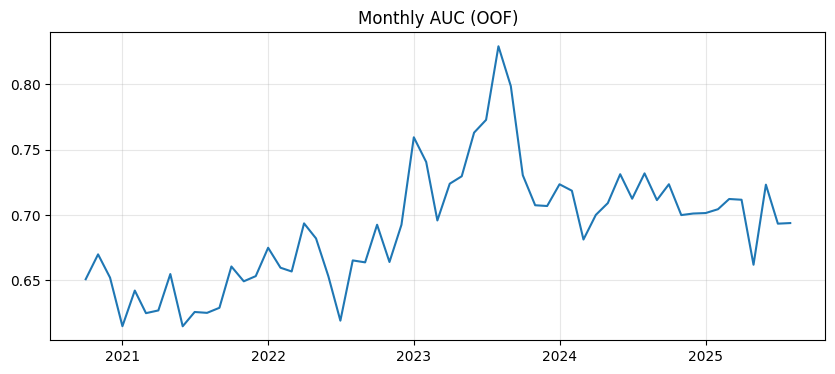

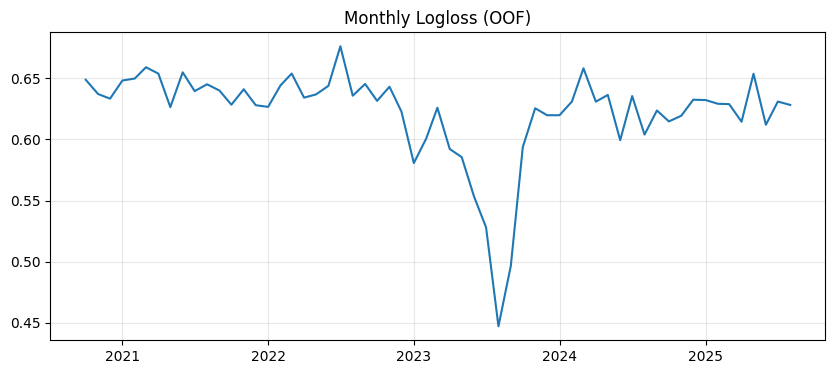

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(monthly["month"][:-2], monthly["auc"][:-2])
plt.title("Monthly AUC (OOF)")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(monthly["month"][:-2], monthly["logloss"][:-2])
plt.title("Monthly Logloss (OOF)")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ดึงคอลัมน์ regime / scale ที่อยากดูจาก polars -> pandas
reg_cols = ["climate_state", "rr_med_480_bps", "rv_sqrt_ema_480", "active_ms_rank_ema_480"]
reg = df.select(["t"] + [c for c in reg_cols if c in df.columns]).to_pandas()
reg["t"] = pd.to_datetime(reg["t"])

pred2 = pred.merge(reg, on="t", how="left")
pred2.head()

,idx,fold,t,y,p,test_start,test_end,month,climate_state,rr_med_480_bps,rv_sqrt_ema_480,active_ms_rank_ema_480
0,394560,0,2020-10-01 00:00:00,1,0.521883,2020-10-01,2021-01-01,2020-10-01,1_3_1,6.957974,0.000554,0.314980
1,394561,0,2020-10-01 00:01:00,1,0.528742,2020-10-01,2021-01-01,2020-10-01,1_3_1,6.957974,0.000555,0.317020
2,394562,0,2020-10-01 00:02:00,1,0.538151,2020-10-01,2021-01-01,2020-10-01,1_3_1,6.957974,0.000556,0.318309
3,394563,0,2020-10-01 00:03:00,1,0.551098,2020-10-01,2021-01-01,2020-10-01,1_3_1,6.957974,0.000557,0.319734
4,394564,0,2020-10-01 00:04:00,1,0.553191,2020-10-01,2021-01-01,2020-10-01,1_3_1,6.957974,0.000559,0.321858


In [ ]:
by_climate = (
    pred2.groupby("climate_state")
         .apply(lambda g: pd.Series({
             "n": len(g),
             "pos_rate": g["y"].mean(),
             "auc": roc_auc_score(g["y"], g["p"]) if g["y"].nunique()>1 else np.nan,
             "logloss": log_loss(g["y"], g["p"]),
         }))
         .reset_index()
         .sort_values("n", ascending=False)
)
by_climate

/tmp/ipython-input-810887498.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,climate_state,n,pos_rate,auc,logloss
5,0_1_0,77974.0,0.569844,0.731690,0.599545
0,0_0_0,71545.0,0.589391,0.743204,0.585168
10,0_2_0,66926.0,0.564086,0.742776,0.592001
104,4_0_4,62663.0,0.377097,0.599504,0.671063
119,4_3_4,56667.0,0.482485,0.698156,0.631068
...,...,...,...,...,...
110,4_2_0,1886.0,0.602863,0.740296,0.596069
44,1_3_4,1209.0,0.670802,0.690825,0.577401
19,0_3_4,646.0,0.722910,0.510988,0.671335
14,0_2_4,434.0,0.582949,0.562149,0.743760


In [ ]:
# bucket แบบ robust
pred2["rv_sqrt_bucket"] = pd.qcut(pred2["rv_sqrt_ema_480"], q=10, duplicates="drop")

by_rv = (
    pred2.groupby("rv_sqrt_bucket")
         .apply(lambda g: pd.Series({
             "n": len(g),
             "pos_rate": g["y"].mean(),
             "auc": roc_auc_score(g["y"], g["p"]) if g["y"].nunique()>1 else np.nan,
             "logloss": log_loss(g["y"], g["p"]),
             "p_mean": g["p"].mean(),
         }))
         .reset_index()
)
by_rv

/tmp/ipython-input-2171391279.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pred2.groupby("rv_sqrt_bucket")
/tmp/ipython-input-2171391279.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,rv_sqrt_bucket,n,pos_rate,auc,logloss,p_mean
0,"(-0.000962, 0.00012]",262944.0,0.620010,0.761377,0.561155,0.588249
1,"(0.00012, 0.00016]",262944.0,0.550060,0.720360,0.610832,0.548850
2,"(0.00016, 0.000203]",262944.0,0.538871,0.713006,0.617475,0.535415
3,"(0.000203, 0.000256]",262944.0,0.520982,0.703314,0.625486,0.526891
4,"(0.000256, 0.000336]",262944.0,0.496889,0.693168,0.632726,0.510128
5,"(0.000336, 0.000464]",262944.0,0.473827,0.684016,0.637683,0.499202
6,"(0.000464, 0.000651]",262944.0,0.451571,0.662188,0.649599,0.494634
7,"(0.000651, 0.000884]",262944.0,0.418249,0.630430,0.665006,0.495876
8,"(0.000884, 0.00131]",262944.0,0.400389,0.617778,0.681640,0.515723
9,"(0.00131, 0.0354]",262944.0,0.365063,0.619057,0.680402,0.510771


In [ ]:
# bucket แบบ robust
pred2["active_bucket"] = pd.qcut(pred2["active_ms_rank_ema_480"], q=10, duplicates="drop")

by_at = (
    pred2.groupby("active_bucket")
         .apply(lambda g: pd.Series({
             "n": len(g),
             "pos_rate": g["y"].mean(),
             "auc": roc_auc_score(g["y"], g["p"]) if g["y"].nunique()>1 else np.nan,
             "logloss": log_loss(g["y"], g["p"]),
             "p_mean": g["p"].mean(),
         }))
         .reset_index()
)
by_at

/tmp/ipython-input-1426337399.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pred2.groupby("active_bucket")
/tmp/ipython-input-1426337399.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,active_bucket,n,pos_rate,auc,logloss,p_mean
0,"(0.04, 0.221]",262944.0,0.552524,0.724037,0.607097,0.566295
1,"(0.221, 0.299]",262944.0,0.520004,0.707803,0.622656,0.558296
2,"(0.299, 0.368]",262944.0,0.514699,0.702653,0.625762,0.550342
3,"(0.368, 0.433]",262944.0,0.485659,0.692615,0.634319,0.532110
4,"(0.433, 0.497]",262944.0,0.475116,0.680276,0.641628,0.523863
5,"(0.497, 0.564]",262944.0,0.473059,0.678819,0.642498,0.517488
6,"(0.564, 0.632]",262944.0,0.467659,0.672315,0.646051,0.509261
7,"(0.632, 0.707]",262944.0,0.471036,0.665525,0.649664,0.507892
8,"(0.707, 0.8]",262944.0,0.451617,0.670521,0.646209,0.491309
9,"(0.8, 0.985]",262944.0,0.424539,0.656606,0.646121,0.468883


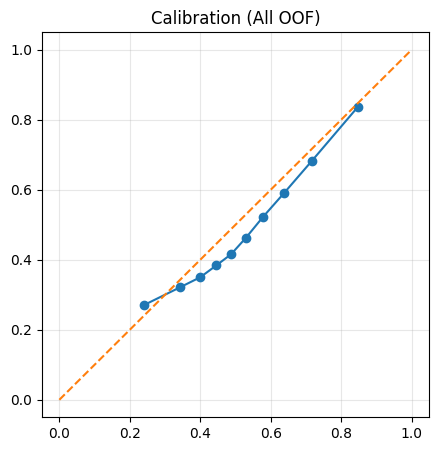

In [ ]:
from sklearn.calibration import calibration_curve

def plot_calibration(pred_df, title="Calibration"):
    y = pred_df["y"].values
    p = pred_df["p"].values
    prob_true, prob_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")

    plt.figure(figsize=(5,5))
    plt.plot(prob_pred, prob_true, marker="o")
    plt.plot([0,1],[0,1], linestyle="--")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

plot_calibration(pred, "Calibration (All OOF)")

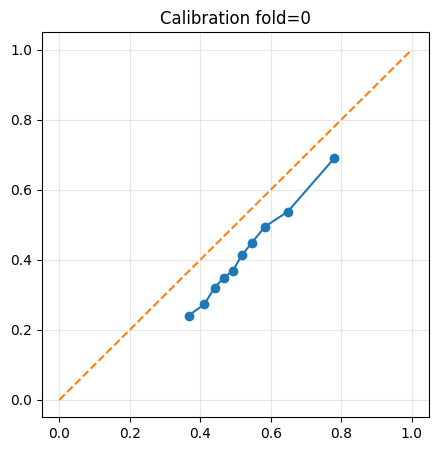

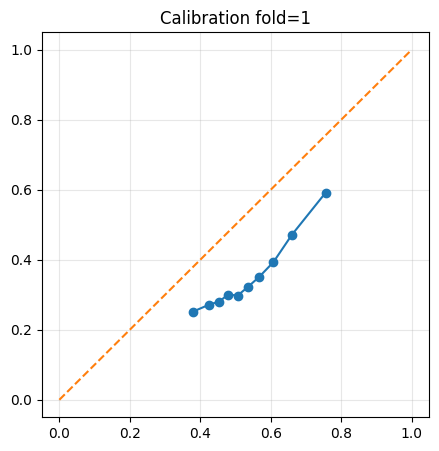

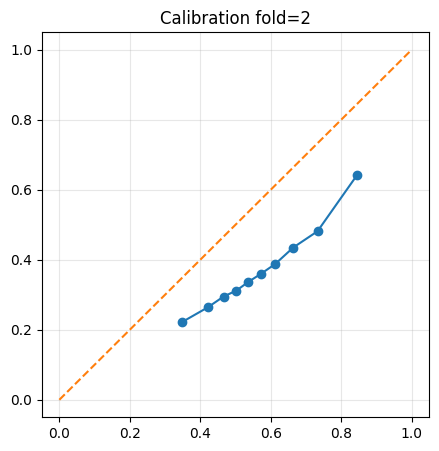

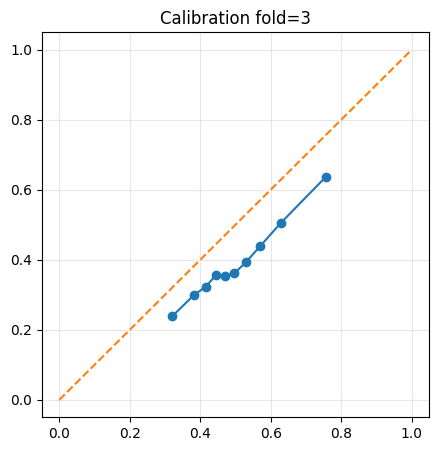

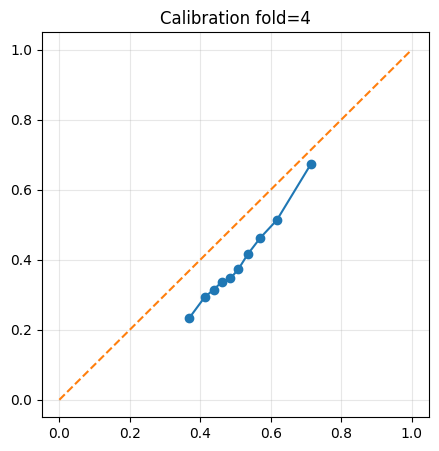

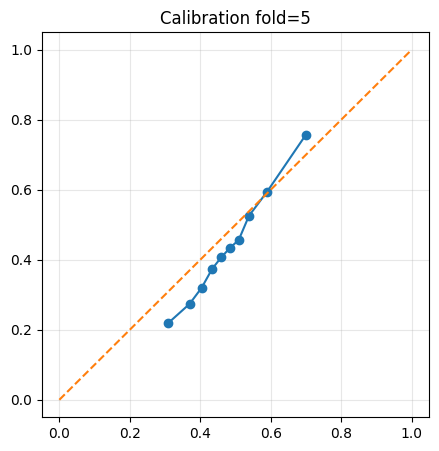

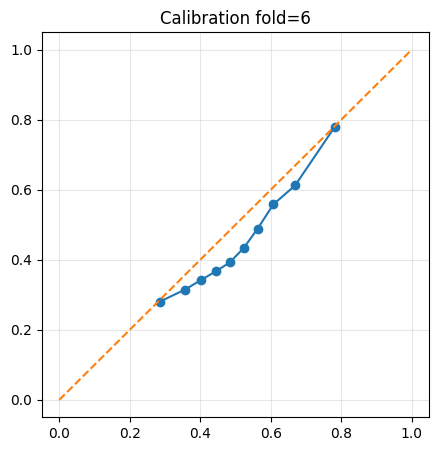

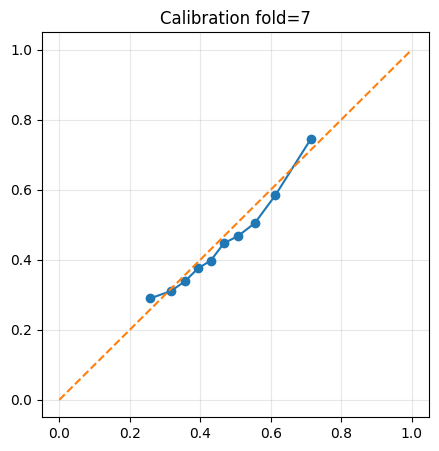

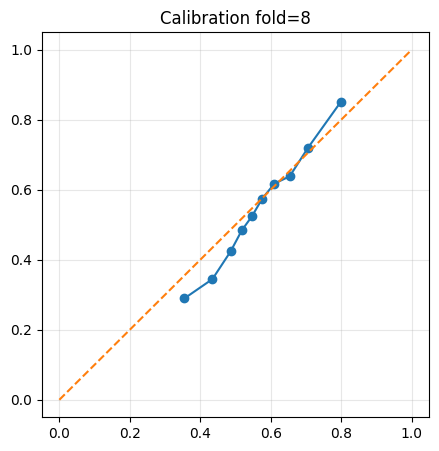

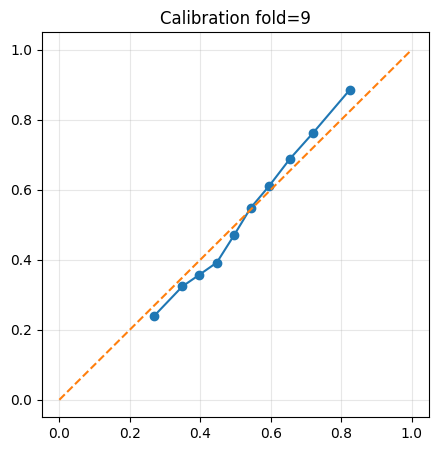

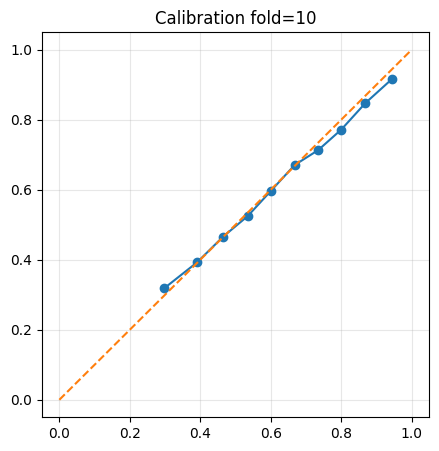

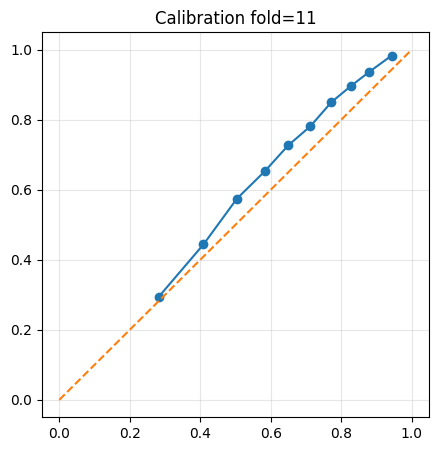

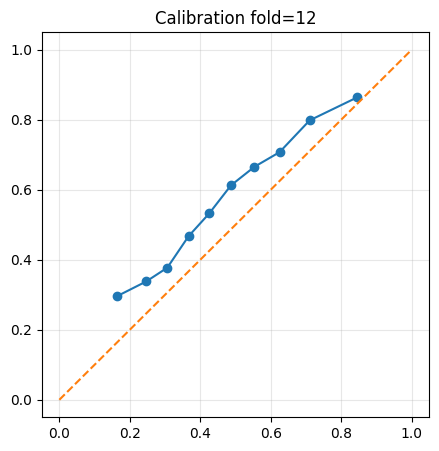

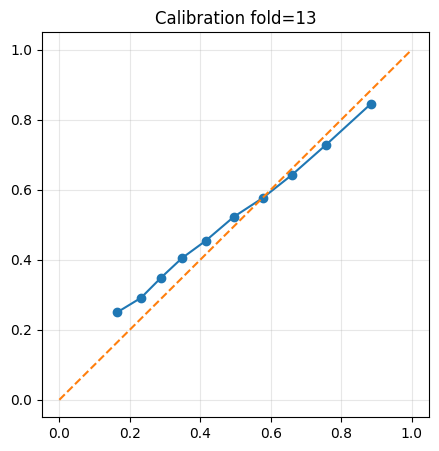

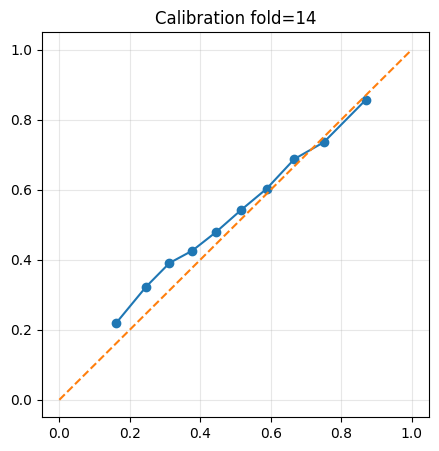

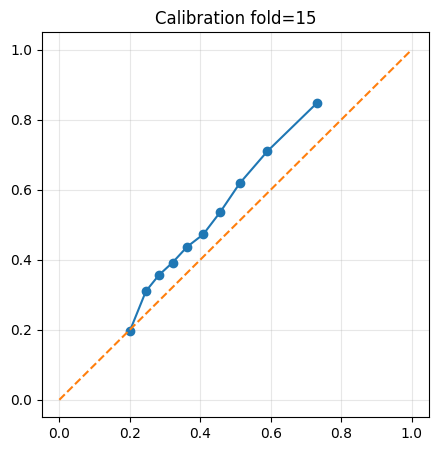

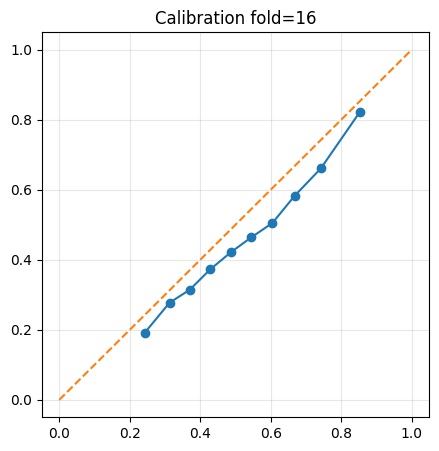

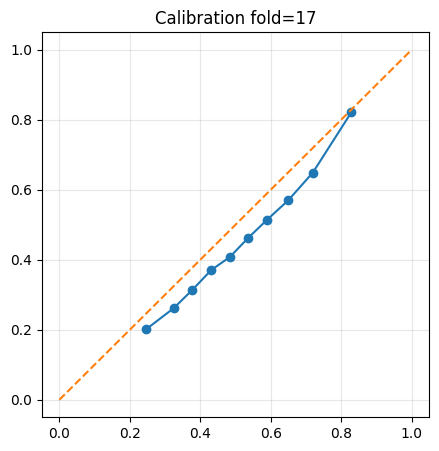

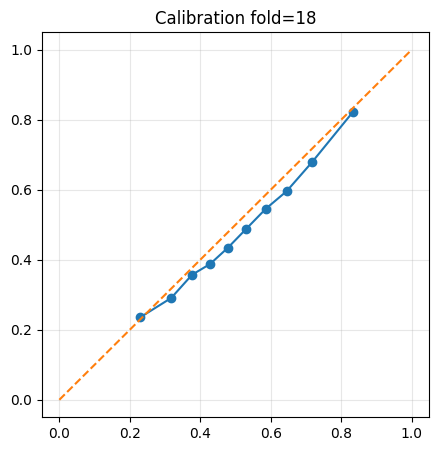

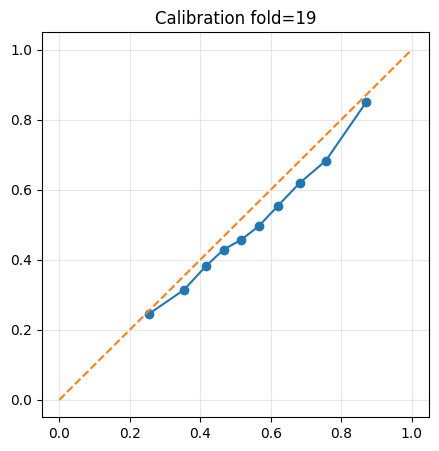

In [ ]:
for fold_id, g in pred.groupby("fold"):
    plot_calibration(g, f"Calibration fold={fold_id}")

In [ ]:
def psi(expected, actual, bins=10, eps=1e-8):
    expected = np.asarray(expected, dtype=float)
    actual   = np.asarray(actual, dtype=float)

    # quantile bins จาก expected
    qs = np.linspace(0, 1, bins+1)
    cuts = np.unique(np.quantile(expected[~np.isnan(expected)], qs))
    if len(cuts) < 3:
        return np.nan

    def hist(x):
        h, _ = np.histogram(x[~np.isnan(x)], bins=cuts)
        h = h / max(h.sum(), 1)
        return np.clip(h, eps, 1.0)

    e = hist(expected)
    a = hist(actual)
    return float(np.sum((a - e) * np.log(a / e)))

def compute_fold_feature_psi(df, folds, feature_cols, tcol="t"):
    # ใช้ df เป็น polars, แต่คำนวณใน numpy ง่ายสุด
    out = []
    for f in folds:
        tr = f["train_idx"]
        te = f["test_idx"]
        for c in feature_cols:
            x = df[c].to_numpy()
            out.append({
                "fold": f["fold"],
                "feature": c,
                "psi": psi(x[tr], x[te], bins=10),
            })
    return pd.DataFrame(out)

# เลือก 10-20 feature แกนก่อน (ไม่ต้องทั้งชุด)
drift_features = [
    "rr_med_480_bps", "realized_range_bps", "rv_sqrt_ema_480",
    "active_ms", "active_ms_rank_ema_480",
    "avg_trade_q", "sq_rank_with_sign_rank_ema_480",
]
drift_features = [c for c in drift_features if c in df.columns]

psi_table = compute_fold_feature_psi(df, folds, drift_features)
psi_pivot = psi_table.pivot_table(index="feature", columns="fold", values="psi")
psi_pivot

fold,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
feature,,,,,,,,,,,,,,,,,,,,
active_ms,0.249977,4.578296,2.704638,0.403578,0.321154,0.616358,0.146131,0.099180,0.219603,0.065352,0.326526,1.283835,0.266903,1.462098,0.149485,0.146204,0.193395,0.110133,0.023304,0.028317
active_ms_rank_ema_480,0.015636,0.738339,0.041884,4.419796,0.738229,0.166779,0.251544,0.496175,0.661152,0.236651,0.451538,0.246065,5.561675,1.017451,0.840633,0.504960,0.417666,0.069396,0.185731,0.040442
avg_trade_q,0.120893,3.479852,4.233759,1.769266,1.637982,0.003862,1.248134,0.749701,0.020752,0.218164,0.137068,0.246225,0.260765,0.394738,0.139750,0.644308,0.614464,0.193054,0.586742,0.047447
realized_range_bps,0.004185,1.046894,0.474207,0.144208,0.449903,0.148270,0.127015,0.026106,0.610704,0.335082,0.495626,0.530373,0.116147,0.596058,0.214107,0.043604,0.059834,0.137286,0.015516,0.059811
rr_med_480_bps,0.060316,4.929012,2.614150,0.772914,2.643034,0.434190,0.353861,0.198194,1.375033,0.934711,3.052368,1.403890,0.313934,1.509910,0.676228,0.117386,0.169659,0.345681,0.065750,0.251754
rv_sqrt_ema_480,0.242344,6.469813,3.857071,0.842764,1.994662,0.557409,1.000059,0.172262,1.511834,1.039792,1.468069,1.176188,0.066388,0.291717,0.554238,0.411982,0.095378,0.026656,0.023863,0.406130
sq_rank_with_sign_rank_ema_480,0.072149,0.169966,0.043522,0.118146,0.009929,0.137214,0.076251,0.103564,0.157526,0.171452,0.062686,0.200361,0.042897,0.138290,0.014900,0.143374,0.029727,0.130660,0.153158,0.026014


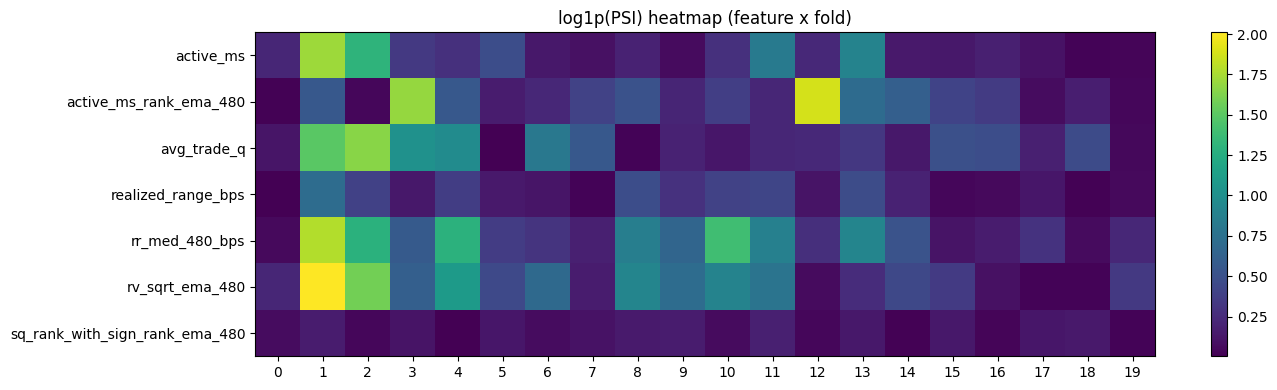

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# psi_pivot = ตารางที่คุณมี (index=feature, columns=fold, values=psi)
# ถ้าตอนนี้เป็น dataframe ชื่อ psi_pivot อยู่แล้ว ข้ามบรรทัดนี้

plt.figure(figsize=(14,4))
plt.imshow(np.log1p(psi_pivot.values), aspect="auto")  # log1p ให้เห็นทั้งเล็ก/ใหญ่
plt.yticks(range(len(psi_pivot.index)), psi_pivot.index)
plt.xticks(range(len(psi_pivot.columns)), psi_pivot.columns)
plt.title("log1p(PSI) heatmap (feature x fold)")
plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
thr = 0.25
feat_summary = pd.DataFrame({
    "psi_median": psi_pivot.median(axis=1),
    "psi_mean": psi_pivot.mean(axis=1),
    "frac_gt_0p25": (psi_pivot > thr).mean(axis=1),
    "max_psi": psi_pivot.max(axis=1),
}).sort_values(["frac_gt_0p25", "max_psi"], ascending=False)

feat_summary

,psi_median,psi_mean,frac_gt_0p25,max_psi
feature,,,,
rr_med_480_bps,0.555209,1.111099,0.75,4.929012
rv_sqrt_ema_480,0.555824,1.110431,0.70,6.469813
active_ms_rank_ema_480,0.434602,0.855087,0.60,5.561675
avg_trade_q,0.327751,0.837346,0.55,4.233759
active_ms,0.234790,0.669723,0.45,4.578296
realized_range_bps,0.146239,0.281747,0.40,1.046894
sq_rank_with_sign_rank_ema_480,0.110855,0.100089,0.00,0.200361


In [ ]:
fold_summary = pd.DataFrame({
    "psi_mean": psi_pivot.mean(axis=0),
    "psi_median": psi_pivot.median(axis=0),
    "psi_max": psi_pivot.max(axis=0),
}).sort_values("psi_mean", ascending=False)

fold_summary

,psi_mean,psi_median,psi_max
fold,,,
1,3.058882,3.479852,6.469813
2,1.995605,2.614150,4.233759
3,1.210096,0.772914,4.419796
4,1.113556,0.738229,2.643034
12,0.946958,0.260765,5.561675
10,0.856269,0.451538,3.052368
13,0.772894,0.596058,1.509910
11,0.726705,0.530373,1.403890
8,0.650944,0.610704,1.511834


In [ ]:
tmp.sort_values("fold", ascending=True)

,fold,psi_mean,psi_median,psi_max,auc
19,0,0.109266,0.071236,0.263268,0.648748
0,1,3.069205,3.521858,6.474579,0.615844
1,2,2.035920,2.695082,4.215826,0.636377
2,3,1.216883,0.781454,4.437935,0.621899
3,4,1.123075,0.715590,2.682644,0.638373
13,5,0.285655,0.153289,0.593757,0.672758
9,6,0.447626,0.261110,1.315165,0.664149
14,7,0.253718,0.184874,0.717499,0.647597
8,8,0.694643,0.657154,1.580481,0.688193
10,9,0.432065,0.311133,1.005030,0.728874


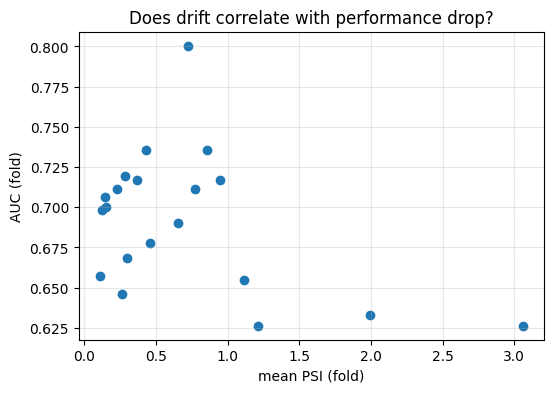

In [ ]:
tmp = fold_summary.reset_index().rename(columns={"index":"fold"}).merge(
    fold_auc[["fold","auc"]],
    on="fold",
    how="left"
)

plt.figure(figsize=(6,4))
plt.scatter(tmp["psi_mean"], tmp["auc"])
plt.xlabel("mean PSI (fold)")
plt.ylabel("AUC (fold)")
plt.title("Does drift correlate with performance drop?")
plt.grid(alpha=0.3)
plt.show()

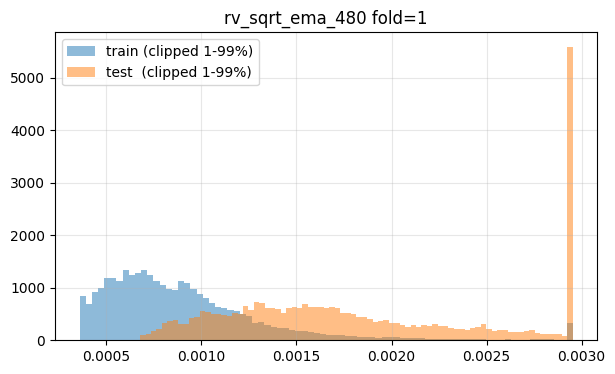

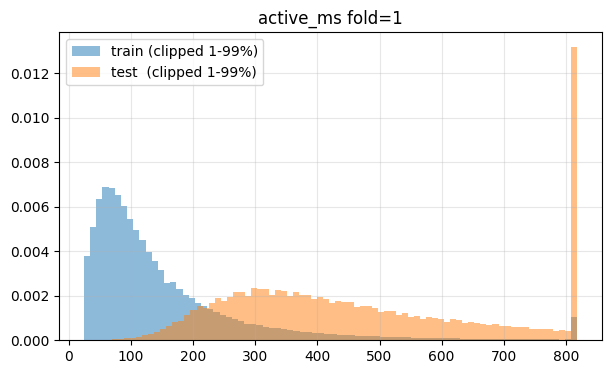

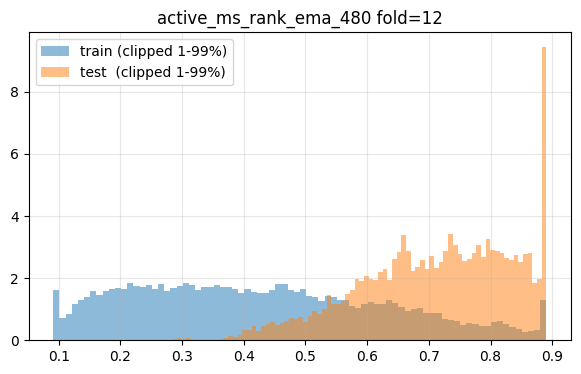

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_train_test_dist(df, folds, fold_id, feature, bins=80):
    f = [x for x in folds if x["fold"] == fold_id][0]
    tr = f["train_idx"]
    te = f["test_idx"]

    x = df[feature].to_numpy()
    a = x[tr]
    b = x[te]
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]

    # winsorize เพื่อดู core shape (กัน outlier ครอบ)
    lo, hi = np.quantile(a, [0.01, 0.99])
    a2 = np.clip(a, lo, hi)
    b2 = np.clip(b, lo, hi)

    plt.figure(figsize=(7,4))
    plt.hist(a2, bins=bins, density=True, alpha=0.5, label="train (clipped 1-99%)")
    plt.hist(b2, bins=bins, density=True, alpha=0.5, label="test  (clipped 1-99%)")
    plt.title(f"{feature} fold={fold_id}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

# ตัวอย่าง: ดู fold=1 ที่ PSI โหด
plot_train_test_dist(df, folds, fold_id=1, feature="rv_sqrt_ema_480")
plot_train_test_dist(df, folds, fold_id=1, feature="active_ms")
plot_train_test_dist(df, folds, fold_id=12, feature="active_ms_rank_ema_480")

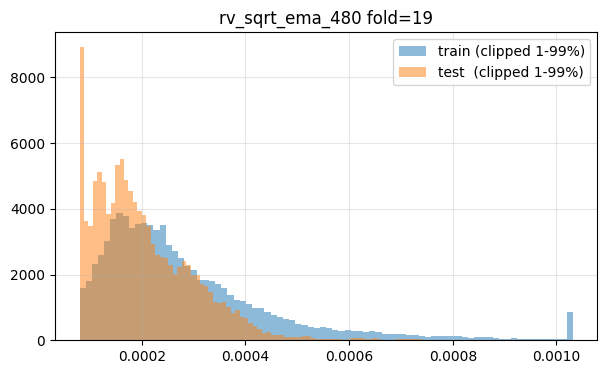

In [ ]:
plot_train_test_dist(df, folds, fold_id=19, feature="rv_sqrt_ema_480")

In [ ]:
def get_fold_importance(models, feature_names):
    rows = []
    for fid, m in models.items():
        imp = m.get_feature_importance()
        for name, val in zip(feature_names, imp):
            rows.append({"fold": fid, "feature": name, "imp": float(val)})
    return pd.DataFrame(rows)

feature_names = FEATURES  # ถ้า X ทำจาก FEATURES ตามลำดับนี้
imp_df = get_fold_importance(models, feature_names)

# ดู top 15 ต่อ fold
topk = (
    imp_df.sort_values(["fold","imp"], ascending=[True, False])
          .groupby("fold")
          .head(15)
)
topk

,fold,feature,imp
8,0,active_ms,13.467219
36,0,rv_sqrt_ema_480,11.581813
13,0,active_ms_evt_frac_60m,11.220833
37,0,rv_sqrt_q_rank_ema_480_slope_120,8.444157
27,0,run_mean_q_rank_ema_480,7.668095
...,...,...,...
849,19,active_ms_evt_frac_60m,2.724237
854,19,avg_trade_q_rank_ema_120,2.277690
879,19,climate_state,2.196435
855,19,avg_trade_q_rank_ema_480,2.184904


In [ ]:
from scipy.stats import spearmanr

def importance_rank_corr(imp_df):
    piv = imp_df.pivot_table(index="feature", columns="fold", values="imp", fill_value=0.0)
    folds_sorted = sorted(piv.columns)
    corr = []
    for i in range(len(folds_sorted)-1):
        a = piv[folds_sorted[i]].rank()
        b = piv[folds_sorted[i+1]].rank()
        corr.append(spearmanr(a, b).correlation)
    return corr

corrs = importance_rank_corr(imp_df)
corrs

[np.float64(0.7985885012153358),
 np.float64(0.8651950324861912),
 np.float64(0.8409618696203573),
 np.float64(0.8133905878614924),
 np.float64(0.8547156481808547),
 np.float64(0.8513855440173362),
 np.float64(0.9043236270892152),
 np.float64(0.8590295818212661),
 np.float64(0.9293732742053794),
 np.float64(0.9190856757838283),
 np.float64(0.8879956273255887),
 np.float64(0.9373039699963813),
 np.float64(0.8465136261107097),
 np.float64(0.8330303344078175),
 np.float64(0.9021201648077295),
 np.float64(0.8676568298753534),
 np.float64(0.784959684580923),
 np.float64(0.887619831336829),
 np.float64(0.8797151716221627)]

In [ ]:
pred

,idx,fold,t,y,p,test_start,test_end,month
0,394560,0,2020-10-01 00:00:00,1,0.521883,2020-10-01,2021-01-01,2020-10-01
1,394561,0,2020-10-01 00:01:00,1,0.528742,2020-10-01,2021-01-01,2020-10-01
2,394562,0,2020-10-01 00:02:00,1,0.538151,2020-10-01,2021-01-01,2020-10-01
3,394563,0,2020-10-01 00:03:00,1,0.551098,2020-10-01,2021-01-01,2020-10-01
4,394564,0,2020-10-01 00:04:00,1,0.553191,2020-10-01,2021-01-01,2020-10-01
...,...,...,...,...,...,...,...,...
2629435,3023995,19,2025-09-30 23:55:00,0,0.487771,2025-07-01,2025-10-01,2025-09-01
2629436,3023996,19,2025-09-30 23:56:00,0,0.458548,2025-07-01,2025-10-01,2025-09-01
2629437,3023997,19,2025-09-30 23:57:00,0,0.462127,2025-07-01,2025-10-01,2025-09-01
2629438,3023998,19,2025-09-30 23:58:00,0,0.478792,2025-07-01,2025-10-01,2025-09-01


In [ ]:
def lift_at_q(g, q=0.95):
    thr = g["p"].quantile(q)
    top = g[g["p"] >= thr]
    return pd.Series({
        "n_top": len(top),
        "hit_rate_top": top["y"].mean() if len(top) else np.nan,
        "hit_rate_all": g["y"].mean(),
        "lift": (top["y"].mean() / g["y"].mean()) if (len(top) and g["y"].mean()>0) else np.nan,
    })

lift_monthly = pred.groupby("month").apply(lift_at_q, q=0.95).reset_index()
lift_monthly.tail(12)

/tmp/ipython-input-2046857525.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lift_monthly = pred.groupby("month").apply(lift_at_q, q=0.95).reset_index()


,month,n_top,hit_rate_top,hit_rate_all,lift
49,2024-11-01,2160.0,0.854630,0.435444,1.962663
50,2024-12-01,2232.0,0.861111,0.434351,1.982523
51,2025-01-01,2232.0,0.905466,0.474418,1.908584
52,2025-02-01,2016.0,0.875000,0.446972,1.957619
53,2025-03-01,2232.0,0.893817,0.448250,1.994013
54,2025-04-01,2160.0,0.900000,0.454524,1.980092
55,2025-05-01,2232.0,0.836918,0.480242,1.742700
56,2025-06-01,2160.0,0.903704,0.509375,1.774141
57,2025-07-01,2231.0,0.911251,0.521542,1.747223
58,2025-08-01,2232.0,0.881720,0.469269,1.878924


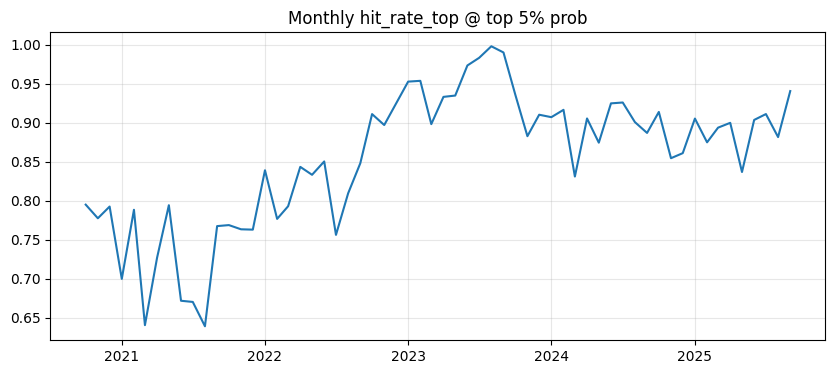

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(lift_monthly["month"][:-1], lift_monthly["hit_rate_top"][:-1])
plt.title("Monthly hit_rate_top @ top 5% prob")
plt.grid(alpha=0.3)
plt.show()

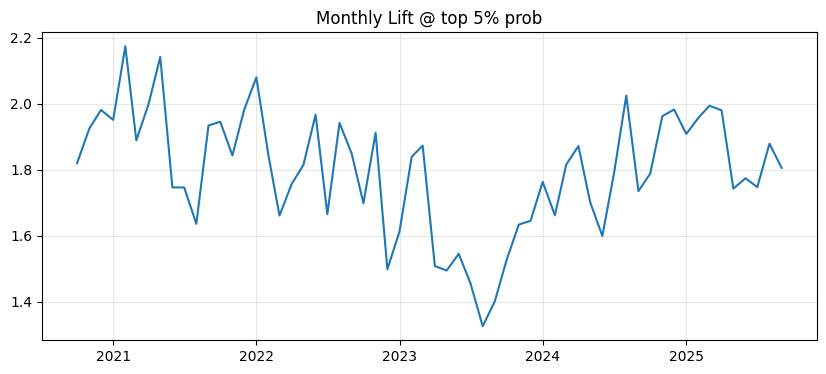

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(lift_monthly["month"][:-1], lift_monthly["lift"][:-1])
plt.title("Monthly Lift @ top 5% prob")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
lift_fold = pred.groupby("fold").apply(lift_at_q, q=0.95).reset_index()

/tmp/ipython-input-3790407017.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lift_fold = pred.groupby("fold").apply(lift_at_q, q=0.95).reset_index()


In [ ]:
lift_fold

,fold,n_top,hit_rate_top,hit_rate_all,lift
0,0,6607.0,0.797033,0.413824,1.926020
1,1,6469.0,0.701963,0.352949,1.988850
2,2,6532.0,0.742345,0.373207,1.989100
3,3,6606.0,0.699364,0.390574,1.790606
4,4,6624.0,0.763889,0.397821,1.920180
5,5,6480.0,0.796914,0.434477,1.834192
6,6,6552.0,0.845391,0.457575,1.847547
7,7,6625.0,0.808604,0.442847,1.825920
8,8,6616.0,0.913089,0.541994,1.684684
9,9,6466.0,0.940767,0.529818,1.775642


In [ ]:
tmp = fold_summary.reset_index().rename(columns={"index":"fold"}).merge(
    fold_auc[["fold","auc"]],
    on="fold",
    how="left"
)

tmp = tmp.merge(
    lift_fold[["fold","hit_rate_top"]],
    on="fold",
    how="left"
)

In [ ]:
tmp

,fold,psi_mean,psi_median,psi_max,auc,hit_rate_top
0,1,3.058882,3.479852,6.469813,0.626320,0.701963
1,2,1.995605,2.614150,4.233759,0.633053,0.742345
2,3,1.210096,0.772914,4.419796,0.626320,0.699364
3,4,1.113556,0.738229,2.643034,0.654678,0.763889
4,12,0.946958,0.260765,5.561675,0.716845,0.919825
5,10,0.856269,0.451538,3.052368,0.735522,0.948052
6,13,0.772894,0.596058,1.509910,0.711188,0.886752
7,11,0.726705,0.530373,1.403890,0.800455,0.991979
8,8,0.650944,0.610704,1.511834,0.690324,0.913089
9,6,0.457571,0.251544,1.248134,0.677921,0.845391


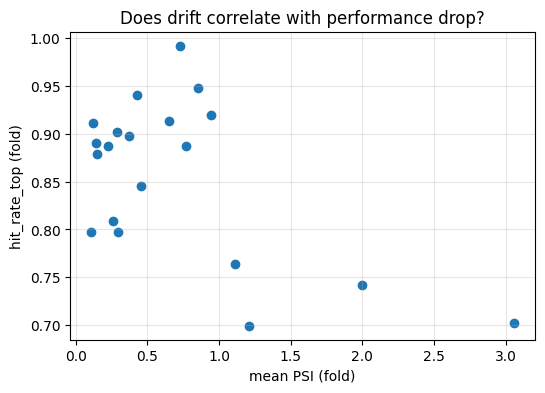

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(tmp["psi_mean"], tmp["hit_rate_top"])
plt.xlabel("mean PSI (fold)")
plt.ylabel("hit_rate_top (fold)")
plt.title("Does drift correlate with performance drop?")
plt.grid(alpha=0.3)
plt.show()